# Домашнее задание 1: рекомендательные системы

**Козлов Кирилл Андреевич** · Amazon Reviews 2018 Video Games 5-core

Пять моделей с нуля, единый временной протокол, validation-подбор и завершённая финальная оценка на test.


### 1. Источник, поля и воспроизведение

[Первоисточник Amazon Review Data 2018](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/):
`Video_Games_5.json.gz` и `meta_Video_Games.json.gz`. Исходные архивы и подготовленные данные
не загружаются в GitHub. Контрольные суммы зафиксированы в `scripts/prepare_data.py` и отчёте аудита.

Для чтения достаточно открыть выполненный notebook: все таблицы и графики сохранены.
Из папки `homework_1/` (проверено на Python 3.13):
```sh
# Если терминал открыт в корне Git-репозитория:
cd homework_1
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
python scripts/execute_notebook.py --section reports
```
Этот режим обновляет модельные таблицы и графики **из агрегированных отчётов**, сохраняет EDA-выводы,
не читает исходный test и не обучает модели; веса и данные ему не нужны.
Для повторения EDA и последовательного Run All сначала `python scripts/prepare_data.py --download`.
Полный пересчёт с нуля: `python scripts/reproduce.py --output ../../recsys-reproduction`.
Он создаёт отдельную папку, скачивает данные, выполняет EDA, все validation-сетки,
фиксирует настройки, переобучает пять моделей и только затем открывает test.
Исходные научные результаты при этом не перезаписываются; времена исполнения могут отличаться.
Подробности, требования к памяти и ограничения — в README.

Разделы 1–13: данные, EDA и протокол; 14–18: CF; 19–23: iALS; 24–28: EASE;
29–34: FM; 35–39: timeSVD++; 40–45: финальный test.
Промежуточные сравнения в разделах моделей относятся к validation; финальные выводы — к test.

| Поле | Смысл |
|---|---|
| `user_id` | анонимный ID автора отзыва |
| `item_id` | ASIN товара, общий ключ с метаданными |
| `rating` | целочисленная оценка 1–5 |
| `timestamp` | время публикации отзыва, Unix seconds; далее только UTC |
| `title`, `brand` | название и бренд из карточки товара |
| `categories` | уровни категории после удаления HTML-хвостов |
| `description`, `features` | описания и характеристики из карточки |

Дата отзыва не равна дате покупки/первого использования. Исторические версии карточек отсутствуют.
**Пункт, не закрытый перед сдачей:** у `brand`/`categories` нет исторических версий.
Fit-only словарь не доказывает, что значение карточки было доступно в момент запроса.
По строгому требованию PDF нужно согласовать статическое допущение с преподавателем
либо выполнить отдельный корректирующий эксперимент с датированными признаками FM.
Подробное обоснование и варианты исправления — в README этой домашней работы.


In [1]:
from pathlib import Path
import os, sys, json, gzip, hashlib, math, random, textwrap
from collections import Counter
import importlib.metadata

_working = Path.cwd()
ROOT = next((p for p in [_working, _working/'homework_1', _working/'recsys'/'homework_1']
             if (p/'scripts/prepare_data.py').is_file()), None)
assert ROOT is not None, 'Запустите notebook из homework_1 или корня репозитория'
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache/matplotlib'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
sys.path.insert(0, str(ROOT))
from scripts.prepare_data import deterministic_gzip, sha256

SEED = 42
K = 10
RELEVANCE_THRESHOLD = 4
VALIDATION_START = pd.Timestamp('2016-01-01', tz='UTC')
TEST_START = pd.Timestamp('2017-01-01', tz='UTC')
random.seed(SEED)
np.random.seed(SEED)
FIGURES = ROOT / 'reports/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
COLORS = ['#255F85', '#D87535', '#3B8C78', '#9274A6', '#6B7C8F']
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10, 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.prop_cycle': plt.cycler(color=COLORS), 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.alpha': 0.18, 'axes.axisbelow': True,
    'savefig.dpi': 145,
})
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')

def show_figure(name, fig):
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def fmt(value):
    return f'{value:,}'.replace(',', ' ')

versions = {name: importlib.metadata.version(name) for name in
            ['numpy', 'scipy', 'pandas', 'matplotlib', 'nbformat', 'nbclient', 'ipykernel']}
display(pd.Series(versions, name='Версия').to_frame())
from scripts.reporting import load_validation_report, load_final_report
_saved_protocol=json.loads((ROOT/'reports/evaluation_protocol.json').read_text())
validation_view={'stats':_saved_protocol['evaluation_diagnostics']['validation']}


,Версия
numpy,2.2.4
scipy,1.15.2
pandas,2.2.3
matplotlib,3.10.1
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0


In [2]:
audit = json.loads((ROOT / 'reports/data_audit.json').read_text())
for relative, info in audit['outputs'].items():
    path = ROOT / relative
    assert path.is_file(), 'Сначала выполните python scripts/prepare_data.py --download'
    assert sha256(path) == info['sha256'], f'Изменился файл: {relative}'

interactions = pd.read_csv(ROOT / 'data/processed/interactions.csv.gz',
    dtype={'user_id': 'string', 'item_id': 'string', 'rating': 'int8', 'timestamp': 'int64'})
interactions['datetime'] = pd.to_datetime(interactions['timestamp'], unit='s', utc=True)
with gzip.open(ROOT / 'data/processed/items.jsonl.gz', 'rt', encoding='utf-8') as stream:
    items = pd.DataFrame(json.loads(line) for line in stream)
items['item_id'] = items['item_id'].astype('string')
assert not interactions.duplicated(['user_id', 'item_id']).any()
assert not items.item_id.duplicated().any()
assert set(interactions.item_id) == set(items.item_id)
assert interactions[['user_id', 'item_id', 'rating', 'timestamp']].notna().all().all()
assert interactions.rating.between(1, 5).all()
assert len(interactions) == audit['cleaned']['interactions']
print('Контрольные суммы, уникальность пар и связь с метаданными проверены.')

Контрольные суммы, уникальность пар и связь с метаданными проверены.


### 2. Очистка, пропуски и границы выборки

Очистка выполнена воспроизводимым скриптом. При повторной паре пользователь–товар оставлена
самая ранняя запись; одинаковое время разрешается исходным порядком строк. При дубликате ASIN
выбрана наиболее полная карточка по фиксированному правилу. Удалены товары без метаданных,
очищен HTML, затем восстановлен 5-core. Случайной подвыборки нет.

**Ограничение:** исходный 5-core и его восстановление используют весь период наблюдений.
Это заранее отобранная когорта активных пользователей и товаров, а не оценка на полном потоке
Amazon. Дополнительные пороги активности по validation/test далее не применяем.

In [3]:
stages = pd.DataFrame([
    {'stage': 'Исходный 5-core', **audit['raw_interactions']},
    *audit['stages'],
]).rename(columns={'stage': 'Этап', 'interactions': 'Взаимодействия',
                  'users': 'Пользователи', 'items': 'Товары'})
stages['Этап'] = stages['Этап'].replace({
    'valid_records': 'Корректные ID, оценки и даты',
    'earliest_record_per_user_item': 'Одна ранняя запись на пару',
    'join_metadata_with_nonempty_title': 'Есть метаданные и название',
    'restore_five_core': 'Восстановлен 5-core'})
display(stages.set_index('Этап'))
quality = {
    'Некорректные записи': audit['interaction_quality']['invalid'].get('records', 0),
    'Полные дубли записей': audit['interaction_quality']['exact_duplicate_records'],
    'Всего удалено повторных пар': audit['interaction_quality']['removed_repeated_pair_records'],
    'Пар с разными оценками': audit['interaction_quality']['pairs_with_conflicting_ratings'],
    'Товаров без метаданных': audit['metadata_quality']['observed_items_without_metadata'],
    'Повторов ASIN в метаданных': audit['metadata_quality']['duplicate_item_records'],
}
display(pd.Series(quality, name='Количество').to_frame())

,Взаимодействия,Товары,Пользователи
Этап,,,
Исходный 5-core,497577,17408,55223
"Корректные ID, оценки и даты",497577,17408,55223
Одна ранняя запись на пару,473427,17408,55223
Есть метаданные и название,472743,17389,55223
Восстановлен 5-core,452989,16859,50546


,Количество
Некорректные записи,0
Полные дубли записей,23287
Всего удалено повторных пар,24150
Пар с разными оценками,133
Товаров без метаданных,19
Повторов ASIN в метаданных,12908


In [4]:
user_activity = interactions.groupby('user_id', observed=True).size()
item_popularity = interactions.groupby('item_id', observed=True).size()
n_users, n_items = len(user_activity), len(item_popularity)
density = len(interactions) / (n_users * n_items)
summary = pd.Series({
    'Взаимодействия': len(interactions), 'Пользователи': n_users, 'Товары': n_items,
    'Плотность, %': density * 100, 'Разреженность, %': (1-density) * 100,
    'Средняя история пользователя': user_activity.mean(),
    'Медианная история пользователя': user_activity.median(),
    'Среднее число отзывов товара': item_popularity.mean(),
    'Медианное число отзывов товара': item_popularity.median(),
}, name='Значение')
display(summary.to_frame())
assert 100_000 <= len(interactions) <= 2_000_000
assert n_users >= 1_000 and n_items >= 1_000
assert user_activity.min() >= 5 and item_popularity.min() >= 5

,Значение
Взаимодействия,"452,989.000"
Пользователи,"50,546.000"
Товары,"16,859.000"
"Плотность, %",0.053
"Разреженность, %",99.947
Средняя история пользователя,8.962
Медианная история пользователя,6.000
Среднее число отзывов товара,26.869
Медианное число отзывов товара,12.000


### 3. Оценки и определение релевантности

Оценка 4–5 обозначает наблюдаемый положительный отклик. Оценка 1–3 не считается релевантной
для top-10, но это не причина удалять запись из истории. Ненаблюдаемый товар не обязательно
не нравится пользователю: в данных нет логов показов и полного набора покупок.

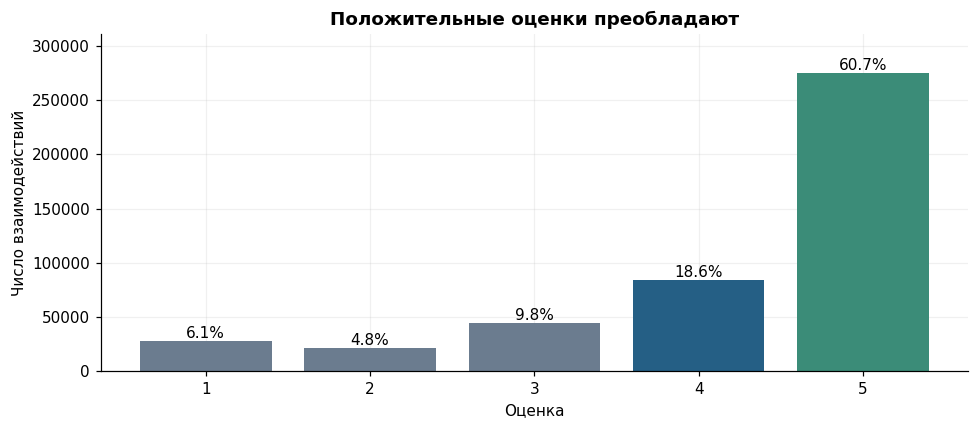

**Вывод:** оценки 4–5 составляют **79.3%**, а пятёрки — **60.7%**. Поэтому распределение классов несбалансировано. Основная задача — ранжирование новых товаров, а не точность угадывания наиболее частой оценки.

In [5]:
rating_counts = interactions.rating.value_counts().reindex(range(1, 6), fill_value=0)
positive_share = float((interactions.rating >= RELEVANCE_THRESHOLD).mean())
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(rating_counts.index.astype(str), rating_counts.values,
              color=[COLORS[4]]*3 + [COLORS[0], COLORS[2]])
for bar, count in zip(bars, rating_counts):
    ax.text(bar.get_x()+bar.get_width()/2, count, f'{count/len(interactions):.1%}',
            ha='center', va='bottom', fontsize=10)
ax.set(xlabel='Оценка', ylabel='Число взаимодействий',
       title='Положительные оценки преобладают', ylim=(0, rating_counts.max()*1.13))
show_figure('01_rating_distribution', fig)
display(Markdown(f'**Вывод:** оценки 4–5 составляют **{positive_share:.1%}**, '
    f'а пятёрки — **{rating_counts.loc[5]/len(interactions):.1%}**. '
    'Поэтому распределение классов несбалансировано. Основная задача — ранжирование '
    'новых товаров, а не точность угадывания наиболее частой оценки.'))

### 4. Активность пользователей и популярность товаров

Обе оси количества взаимодействий ниже используют логарифмическую шкалу. Нижняя граница 5
связана с отбором 5-core, поэтому по этим данным нельзя судить о частоте одноразовых пользователей Amazon.

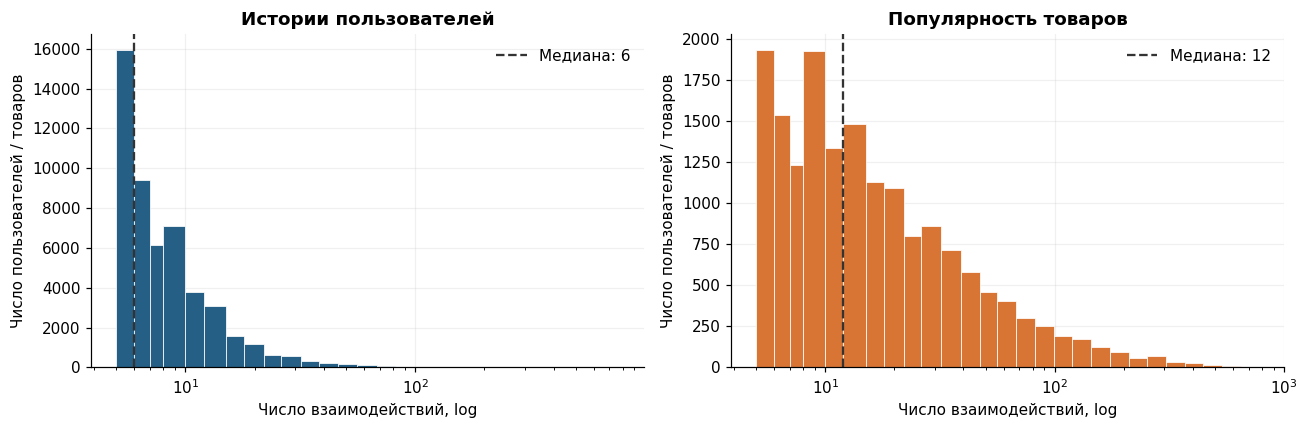

,Пользователи,Товары
count,"50,546.000","16,859.000"
mean,8.962,26.869
std,10.375,46.099
min,5.000,5.000
50%,6.000,12.000
90%,14.000,57.000
95%,20.000,95.000
99%,42.000,247.420
max,771.000,777.000


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, series, title, color in zip(axes,
        [user_activity, item_popularity], ['Истории пользователей', 'Популярность товаров'], COLORS):
    bins = np.unique(np.geomspace(5, series.max()+1, 28).astype(int))
    ax.hist(series, bins=bins, color=color, edgecolor='white', linewidth=.5)
    ax.set_xscale('log')
    ax.set(xlabel='Число взаимодействий, log', ylabel='Число пользователей / товаров', title=title)
    ax.axvline(series.median(), color='#333333', linestyle='--', label=f'Медиана: {series.median():g}')
    ax.legend(frameon=False)
show_figure('02_activity_and_popularity', fig)
display(pd.DataFrame({'Пользователи': user_activity.describe(percentiles=[.5,.9,.95,.99]),
                      'Товары': item_popularity.describe(percentiles=[.5,.9,.95,.99])}))

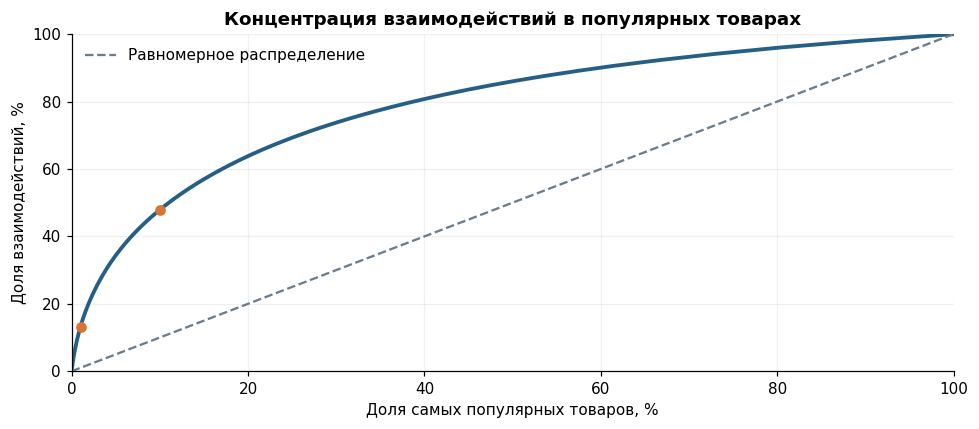

**Вывод:** верхний 1% товаров собирает **13.3%** взаимодействий, верхние 10% — **47.9%**. Это обосновывает дополнительный анализ качества по популярности товаров и catalog coverage; популярность сама по себе ещё не доказывает качество персональных рекомендаций.

In [7]:
pop_sorted = item_popularity.sort_values(ascending=False)
cumulative = pop_sorted.cumsum() / pop_sorted.sum()
top_one_count = math.ceil(len(pop_sorted)*.01)
top_ten_count = math.ceil(len(pop_sorted)*.10)
top_one_share = float(cumulative.iloc[top_one_count-1])
top_ten_share = float(cumulative.iloc[top_ten_count-1])
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, len(cumulative)+1)/len(cumulative)*100, cumulative.values*100, linewidth=2.5)
ax.plot([0,100], [0,100], '--', color=COLORS[4], label='Равномерное распределение')
ax.scatter([100*top_one_count/n_items, 100*top_ten_count/n_items],
           [top_one_share*100, top_ten_share*100], color=COLORS[1], zorder=3)
ax.set(xlabel='Доля самых популярных товаров, %', ylabel='Доля взаимодействий, %',
       title='Концентрация взаимодействий в популярных товарах', xlim=(0,100), ylim=(0,100))
ax.legend(frameon=False)
show_figure('03_popularity_concentration', fig)
display(Markdown(f'**Вывод:** верхний 1% товаров собирает **{top_one_share:.1%}** взаимодействий, '
    f'верхние 10% — **{top_ten_share:.1%}**. Это обосновывает дополнительный анализ '
    'качества по популярности товаров и catalog coverage; популярность сама по себе ещё '
    'не доказывает качество персональных рекомендаций.'))

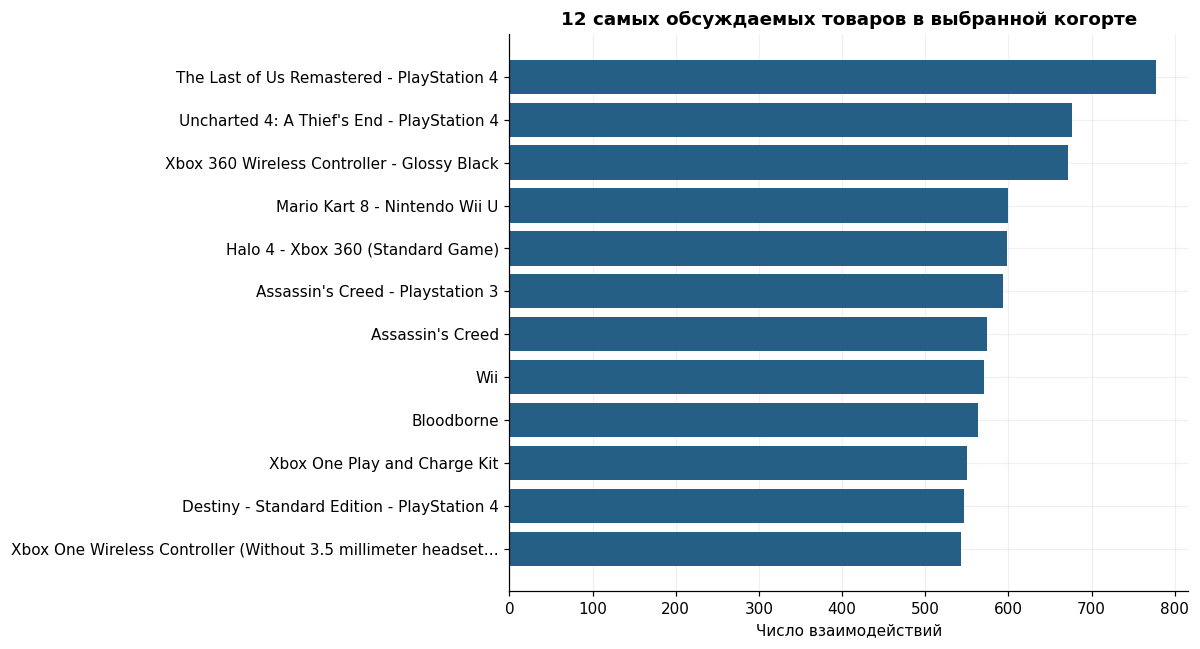

In [8]:
top_items = pop_sorted.head(12).rename('reviews').reset_index().merge(
    items[['item_id','title']], on='item_id', validate='one_to_one')
fig, ax = plt.subplots(figsize=(11, 6))
labels = [textwrap.shorten(t, width=65, placeholder='…') for t in top_items.title]
ax.barh(labels[::-1], top_items.reviews.iloc[::-1], color=COLORS[0])
ax.set(xlabel='Число взаимодействий', title='12 самых обсуждаемых товаров в выбранной когорте')
show_figure('04_top_items', fig)

### 5. Временная структура и точность timestamp

Проверяем общий календарь и длительность пользовательских историй. Снижение числа отзывов в
поздние годы может быть связано с отбором датасета; это не измерение динамики рынка игр.
2018 год представлен только до 2 октября.

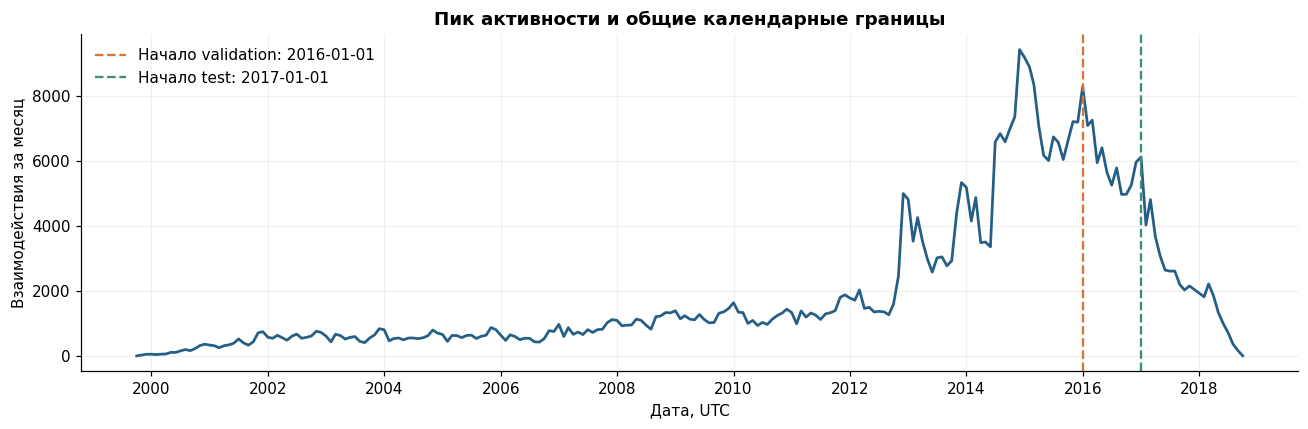

,Взаимодействия,Пользователи,Товары
datetime,,,
2011,16262,6455,4888
2012,22855,8333,6155
2013,43116,13753,8646
2014,68242,18838,10806
2015,85905,21997,12108
2016,72730,19776,11291
2017,37929,12347,8750
2018,11379,4777,4703


In [9]:
monthly = interactions.set_index('datetime').resample('MS').size()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index, monthly.values, color=COLORS[0], linewidth=1.8)
ax.axvline(VALIDATION_START, color=COLORS[1], linestyle='--', label='Начало validation: 2016-01-01')
ax.axvline(TEST_START, color=COLORS[2], linestyle='--', label='Начало test: 2017-01-01')
ax.set(xlabel='Дата, UTC', ylabel='Взаимодействия за месяц', title='Пик активности и общие календарные границы')
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.legend(frameon=False)
show_figure('05_monthly_activity', fig)
annual = interactions.groupby(interactions.datetime.dt.year).agg(
    interactions=('rating','size'), users=('user_id','nunique'), items=('item_id','nunique'))
display(annual.tail(8).rename(columns={'interactions':'Взаимодействия','users':'Пользователи','items':'Товары'}))

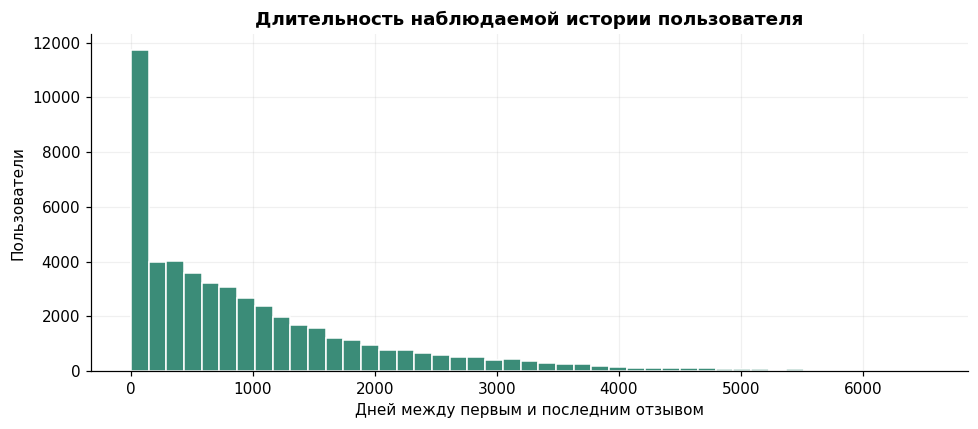

**Вывод:** 100.0% timestamp приходятся на 00:00 UTC: в этой выгрузке фактическая точность — день. Границы разбиения ставим между днями, не делим один день случайно. У **11.8%** пользователей все записи относятся к одному дню; это совместимо с пакетным написанием отзывов и не доказывает одновременные покупки.

In [10]:
user_dates = interactions.groupby('user_id').datetime.agg(['min','max','nunique'])
spans = (user_dates['max']-user_dates['min']).dt.days
midnight_share = float((interactions.timestamp % 86400 == 0).mean())
same_day_share = float((spans==0).mean())
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(spans, bins=45, color=COLORS[2], edgecolor='white')
ax.set(xlabel='Дней между первым и последним отзывом', ylabel='Пользователи',
       title='Длительность наблюдаемой истории пользователя')
show_figure('06_user_history_duration', fig)
display(Markdown(f'**Вывод:** {midnight_share:.1%} timestamp приходятся на 00:00 UTC: '
    'в этой выгрузке фактическая точность — день. Границы разбиения ставим между днями, '
    f'не делим один день случайно. У **{same_day_share:.1%}** пользователей все записи относятся '
    'к одному дню; это совместимо с пакетным написанием отзывов и не доказывает одновременные покупки.'))

### 6. Покрытие и структура метаданных

Пустые строки и списки считаем отсутствующим значением. Показываем покрытие и по товарам,
и с весом по числу взаимодействий: второе показывает, какая часть истории имеет признаки.
Покрытие — диагностическая статистика, а не гарантия полезности признака для FM.

,"Товары, %","Взаимодействия, %",Товаров без значения
Название,100.000,100.000,0.000
Бренд,99.324,99.713,114.000
Категории,99.128,99.568,147.000
Описание,96.785,97.675,542.000
Характеристики,87.662,91.801,"2,080.000"


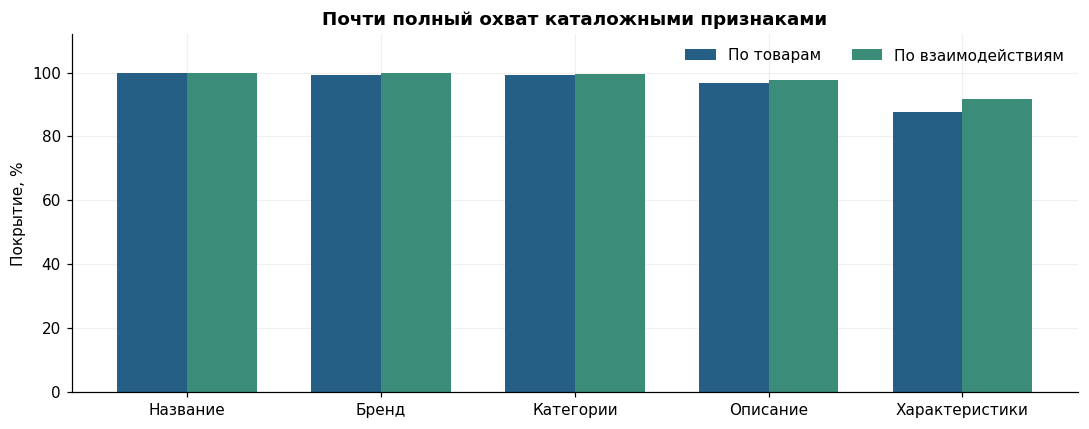

In [11]:
fields = ['title','brand','categories','description','features']
field_labels = ['Название','Бренд','Категории','Описание','Характеристики']
coverage = pd.DataFrame(index=fields)
for field in fields:
    present = items[field].map(bool)
    coverage.loc[field,'Товары, %'] = present.mean()*100
    weighted = items.item_id.map(item_popularity).fillna(0)
    coverage.loc[field,'Взаимодействия, %'] = weighted[present].sum()/len(interactions)*100
    coverage.loc[field,'Товаров без значения'] = (~present).sum()
coverage.index = field_labels
display(coverage)
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(fields)); width=.36
ax.bar(x-width/2, coverage['Товары, %'], width, label='По товарам', color=COLORS[0])
ax.bar(x+width/2, coverage['Взаимодействия, %'], width, label='По взаимодействиям', color=COLORS[2])
ax.set_xticks(x, field_labels)
ax.set(ylabel='Покрытие, %', ylim=(0,112), title='Почти полный охват каталожными признаками')
ax.legend(frameon=False, ncols=2)
show_figure('07_metadata_coverage', fig)

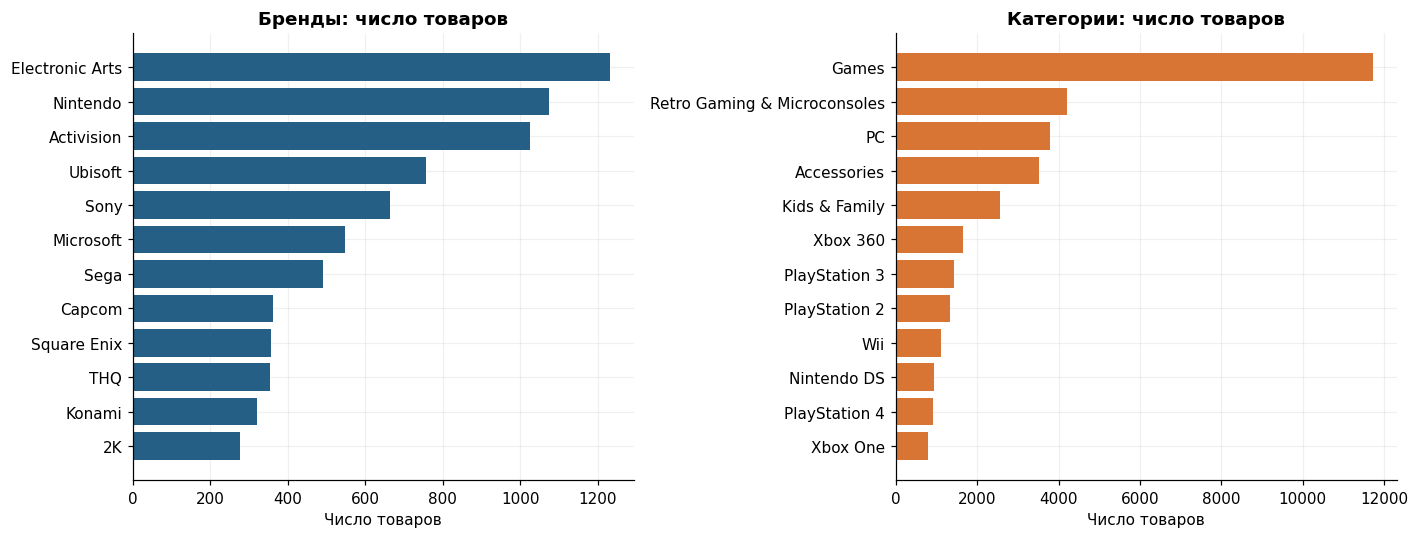

**Вывод:** найдено **1573** непустых значений бренда и **123** значений категорий с учётом корневой Video Games. Категории содержат платформы и типы товаров — это осмысленные признаки совместимости и интересов. Уровни иерархии пересекаются: столбцы категорий нельзя интерпретировать как непересекающиеся классы. Редкие бренды нельзя объединять по частоте на всём датасете: порог и словарь строятся только по fit.

In [12]:
brand_counts = items.loc[items.brand.map(bool),'brand'].value_counts()
category_counts = items[['item_id','categories']].explode('categories').dropna().query(
    "categories != 'Video Games'").categories.value_counts()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, values, title, color in zip(axes, [brand_counts.head(12), category_counts.head(12)],
        ['Бренды: число товаров', 'Категории: число товаров'], COLORS):
    labels=[textwrap.shorten(str(s), width=29, placeholder='…') for s in values.index]
    ax.barh(labels[::-1], values.iloc[::-1], color=color)
    ax.set(xlabel='Число товаров', title=title)
show_figure('08_brands_and_categories', fig)
display(Markdown(f'**Вывод:** найдено **{len(brand_counts)}** непустых значений бренда и '
    f'**{len(category_counts)+1}** значений категорий с учётом корневой Video Games. '
    'Категории содержат платформы и типы товаров — это осмысленные признаки совместимости и интересов. '
    'Уровни иерархии пересекаются: столбцы категорий нельзя интерпретировать как непересекающиеся классы. '
    'Редкие бренды нельзя объединять по частоте на всём датасете: порог и словарь строятся только по fit.'))

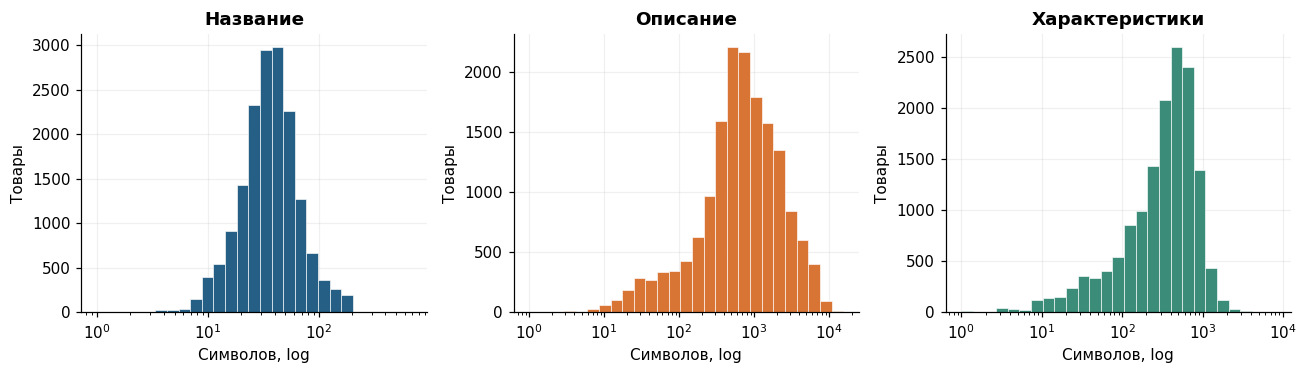

,Название,Описание,Характеристики
count,"16,859.000","16,859.000","16,859.000"
mean,43.100,"1,168.400",381.000
std,29.900,"1,437.300",363.200
min,3.000,0.000,0.000
50%,36.000,660.000,321.000
90%,73.200,"2,862.400",823.200
99%,164.000,"6,843.900","1,519.400"
max,679.000,"15,438.000","7,988.000"


**Вывод:** у **967** товаров нормализованное название совпадает с названием другого ASIN. Это повод для проверки вариантов издания, но не основание автоматически склеивать объекты: платформа, комплект и версия могут различаться. Длины текстов неоднородны, поэтому для FM разумно начать с брендов и категорий. Добавление текстовых признаков проверять отдельной абляцией; словарь/IDF обучать только по fit.

In [13]:
text_lengths = pd.DataFrame({
    'Название': items.title.str.len(),
    'Описание': items.description.map(lambda x: len(' '.join(x))),
    'Характеристики': items.features.map(lambda x: len(' '.join(x))),
})
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (field, values), color in zip(axes, text_lengths.items(), COLORS):
    nonempty=values[values>0]
    bins=np.geomspace(1, nonempty.max()+1, 28)
    ax.hist(nonempty, bins=bins, color=color, edgecolor='white', linewidth=.4)
    ax.set_xscale('log')
    ax.set(xlabel='Символов, log', ylabel='Товары', title=field)
show_figure('09_text_lengths', fig)
normalized_titles=items.title.str.casefold().str.replace(r'\W+', ' ', regex=True).str.strip()
title_groups=normalized_titles.value_counts()
duplicate_title_items=int(normalized_titles.isin(title_groups[title_groups>1].index).sum())
display(text_lengths.describe(percentiles=[.5,.9,.99]).round(1))
display(Markdown(f'**Вывод:** у **{fmt(duplicate_title_items)}** товаров нормализованное название '
    'совпадает с названием другого ASIN. Это повод для проверки вариантов издания, но не основание '
    'автоматически склеивать объекты: платформа, комплект и версия могут различаться. '
    'Длины текстов неоднородны, поэтому для FM разумно начать с брендов и категорий. '
    'Добавление текстовых признаков проверять отдельной абляцией; словарь/IDF обучать только по fit.'))

**План признаков и защита от информации из будущего**

| Признак | Правило использования |
|---|---|
| User/item ID | Словари только по fit; сами по себе не выполняют требование FM о метапризнаках |
| Бренд, категории | Основные кандидаты для FM; неизвестные значения → отдельный UNK, пропуски → MISSING |
| Название/описание/характеристики | Возможная абляция; словарь, частотные пороги, IDF и преобразования только по fit |
| Активность/популярность, статистики оценок | Вычислять заново только на fit текущего этапа |
| Текст будущего отзыва, его оценка, helpful votes | Не использовать как признаки рекомендации |
| Цена, готовые рейтинговые агрегаты, also-buy/also-view | Исключить: нет исторической версии и происхождение может включать будущие события |

Каталожные поля — снимок на момент выгрузки. Их доступность до рекомендации является **явным
допущением**; доказать её по этим файлам нельзя. Это ограничение эксперимента, а не устранённая утечка.
Фильтр 5-core по полному периоду также остаётся ограничением состава когорты.

### 7. Предлагаемое временное разбиение

Используем **единую глобальную временную ось**, а не случайный split и не последний отзыв каждого
пользователя. Иначе события позднего периода одного пользователя могут попасть в обучение для
ранней рекомендации другому. Обоснование: [Ji et al., A Critical Study on Data Leakage](https://arxiv.org/abs/2010.11060).

Фиксируем календарные границы без разрезания суток:

- **Train:** всё до `2016-01-01 00:00 UTC`.
- **Validation:** от `2016-01-01` включительно до `2017-01-01` исключительно.
- **Test:** от `2017-01-01` включительно до конца выгрузки.

Это примерно 73% / 16% / 11% событий; календарные интервалы важнее ровного процентного отношения.
Validation покрывает полный год после пика активности. Test длиннее года и включает неполный 2018:
это проверка переноса во времени, а не одинаковые горизонты. Последствия сдвига явно отмечаем.
Границы не подбирались по качеству моделей и не должны меняться после начала экспериментов.

На этапе подбора fit = train. После выбора всех настроек **один раз переобучаем каждую модель
на train ∪ validation**, пересоздаём преобразования признаков по этому fit и оцениваем test.
Никакие test-взаимодействия в обучение или дообучение не попадают.

In [14]:
train = interactions[interactions.datetime < VALIDATION_START].copy()
validation = interactions[(interactions.datetime >= VALIDATION_START) &
                           (interactions.datetime < TEST_START)].copy()
test = interactions[interactions.datetime >= TEST_START].copy()
final_fit = pd.concat([train, validation], ignore_index=True)
partitions={'train':train, 'validation':validation, 'test':test}
assert len(train)+len(validation)+len(test) == len(interactions)
assert train.datetime.max() < validation.datetime.min()
assert validation.datetime.max() < test.datetime.min()
assert final_fit.datetime.max() < test.datetime.min()
assert not train.index.intersection(validation.index).size
assert not train.index.intersection(test.index).size
assert not validation.index.intersection(test.index).size
split_rows=[]
for name, frame in partitions.items():
    split_rows.append({'Выборка':name, 'Взаимодействия':len(frame),
        'Доля, %':100*len(frame)/len(interactions), 'Пользователи':frame.user_id.nunique(),
        'Товары':frame.item_id.nunique(), 'Первая дата':frame.datetime.min().strftime('%Y-%m-%d'),
        'Последняя дата':frame.datetime.max().strftime('%Y-%m-%d')})
split_table=pd.DataFrame(split_rows).set_index('Выборка')
display(split_table)

,Взаимодействия,"Доля, %",Пользователи,Товары,Первая дата,Последняя дата
Выборка,,,,,,
train,330951,73.059,43463,15578,1999-10-14,2015-12-31
validation,72730,16.056,19776,11291,2016-01-01,2016-12-31
test,49308,10.885,14735,9766,2017-01-01,2018-10-02


### 8. Общие кандидаты, cold start и оценочные пользователи

Для этапа с обучающими данными $F$ и будущим окном $W$:

1. $I_F$ — **все товары, встречавшиеся в fit**, включая товары с оценками 1–3.
   Это консервативная наблюдаемая версия каталога, а не восстановленная дата релиза.
2. $H_u(F)$ — все товары, известные пользователю до границы, независимо от оценки.
   Кандидаты: $C_u = I_F \setminus H_u(F)$; ранжируем **весь** этот набор.
3. $R_u(W) = \{i \in C_u: (u,i,r,t)\in W,\ r\ge4\}$ — доступные релевантные товары.
4. Основная оценка: пользователи, встречавшиеся в fit хотя бы один раз, с $|R_u|>0$
   и не менее 10 кандидатами. Порог 5 по train **не вводим**: короткие истории остаются;
   отдельно анализируем срезы 1–4 / 5–9 / 10+ событий, определённые только по fit.

Новые пользователи и новые товары не входят в основное warm-start сравнение: иначе чистые
коллаборативные методы и FM решали бы разные задачи. Показываем число исключённых событий
и долю доступной положительной обратной связи. Не удаляем такие события из исходных временных
файлов и не заявляем качество рекомендаций для cold start.

Пользователи без релевантных объектов в окне не участвуют в macro Recall/NDCG: знаменатель
Recall для них нулевой. Их число показываем отдельно. Конкретная модель не имеет права исключить
пользователя, изменить кандидатов или таргет test. Для невозможности выдать персональный скор
заранее предусмотрен единый fallback по популярности положительных fit-взаимодействий;
долю fallback необходимо отчитывать. Пока fallback и модели не реализуем.

Все рекомендации для окна строятся **в начале окна**, без обновления истории внутри него.
Для test fit уже включает весь validation, поэтому известные к этому моменту товары маскируются.
Это batch top-N на будущем окне, а не предсказание следующего события. Для timeSVD++ время
запроса — соответствующая граница окна, не время будущего отзыва.

In [15]:
def evaluation_view(fit, holdout):
    fit_users=set(fit.user_id)
    catalog=frozenset(fit.item_id)
    histories=fit.groupby('user_id', observed=True).item_id.agg(frozenset).to_dict()
    warm_user=holdout.user_id.isin(fit_users)
    warm_item=holdout.item_id.isin(catalog)
    status=np.select([warm_user & warm_item, ~warm_user & warm_item,
                      warm_user & ~warm_item],
                     ['known_user_known_item','new_user_known_item','known_user_new_item'],
                     default='new_user_new_item')
    eligible=holdout[warm_user & warm_item]
    relevant=eligible[eligible.rating >= RELEVANCE_THRESHOLD]
    positives=relevant.groupby('user_id', observed=True).item_id.agg(frozenset).to_dict()
    history_counts=fit.groupby('user_id', observed=True).size()
    positive_history_counts=fit[fit.rating >= RELEVANCE_THRESHOLD].groupby('user_id', observed=True).size()
    query_rows=[]
    for user in sorted(positives):
        assert positives[user].isdisjoint(histories[user])
        assert positives[user].issubset(catalog)
        n_candidates=len(catalog)-len(histories[user])
        assert n_candidates >= K
        query_rows.append({'user_id':user, 'history':int(history_counts[user]),
            'positive_history':int(positive_history_counts.get(user,0)),
            'relevant':len(positives[user]), 'candidates':n_candidates})
    queries=pd.DataFrame(query_rows)
    stats={
        'fit_interactions':len(fit), 'fit_users':len(fit_users), 'catalog_items':len(catalog),
        'holdout_interactions':len(holdout), 'holdout_users':holdout.user_id.nunique(),
        'eligible_interactions':len(eligible), 'eligible_users':eligible.user_id.nunique(),
        'relevant_interactions':len(relevant), 'evaluation_users':len(queries),
        'known_users_without_available_relevance':holdout.loc[warm_user, 'user_id'].nunique()-len(queries),
        'all_positive_interactions':int((holdout.rating >= RELEVANCE_THRESHOLD).sum()),
        'positive_interaction_coverage':len(relevant)/int((holdout.rating >= RELEVANCE_THRESHOLD).sum()),
        'users_without_positive_fit_history':int((queries.positive_history==0).sum()),
        'minimum_candidate_count':int(queries.candidates.min()),
        'relevance_size_median':float(queries.relevant.median()),
        'cold_status_counts':pd.Series(status).value_counts().astype(int).to_dict(),
    }
    return {'stats':stats, 'catalog':catalog, 'histories':histories,
            'relevance':positives, 'queries':queries}

validation_view=evaluation_view(train, validation)
test_view=evaluation_view(final_fit, test)
views={'validation':validation_view, 'test':test_view}
cohort_table=pd.DataFrame({name:view['stats'] for name,view in views.items()}).drop('cold_status_counts')
display(cohort_table.rename(index={
    'fit_interactions':'Взаимодействия в fit','fit_users':'Пользователи в fit',
    'catalog_items':'Товары-кандидаты до персональной маски',
    'holdout_interactions':'Все взаимодействия будущего окна','holdout_users':'Все пользователи окна',
    'eligible_interactions':'События с известными пользователем и товаром',
    'eligible_users':'Известные пользователи с доступными событиями',
    'relevant_interactions':'Доступные релевантные взаимодействия',
    'evaluation_users':'Пользователи основной оценки',
    'known_users_without_available_relevance':'Известные пользователи без доступной релевантности',
    'all_positive_interactions':'Все положительные взаимодействия окна',
    'positive_interaction_coverage':'Доля доступных положительных событий',
    'users_without_positive_fit_history':'Оценочные пользователи без положительной истории fit',
    'minimum_candidate_count':'Минимальное число кандидатов у оценочного пользователя',
    'relevance_size_median':'Медианное число релевантных товаров'}))

,validation,test
Взаимодействия в fit,330951,403681
Пользователи в fit,43463,48349
Товары-кандидаты до персональной маски,15578,16721
Все взаимодействия будущего окна,72730,49308
Все пользователи окна,19776,14735
События с известными пользователем и товаром,31860,29488
Известные пользователи с доступными событиями,11905,11339
Доступные релевантные взаимодействия,25646,23454
Пользователи основной оценки,10207,9521
Известные пользователи без доступной релевантности,4683,3017


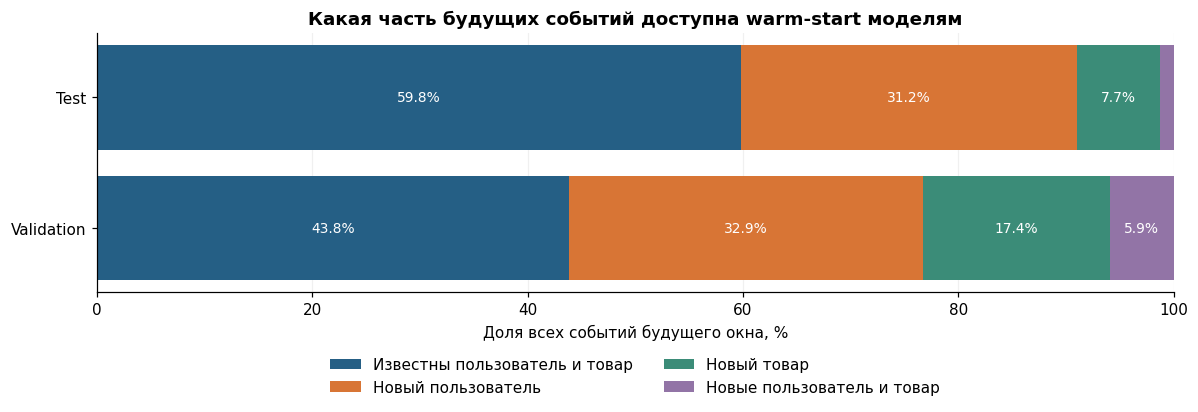

**Вывод:** основная оценка использует **10 207** пользователей validation и **9 521** пользователей test. После ограничения на известный каталог и пользователей доступно **42.9%** / **58.0%** положительных событий окон. Поэтому будущие метрики характеризуют warm-start часть когорты, а не весь сервис.

In [16]:
status_order=['known_user_known_item','new_user_known_item','known_user_new_item','new_user_new_item']
status_labels=['Известны пользователь и товар','Новый пользователь','Новый товар','Новые пользователь и товар']
status_frame=pd.DataFrame({name:view['stats']['cold_status_counts'] for name,view in views.items()}).reindex(status_order).fillna(0)
fig, ax=plt.subplots(figsize=(11,4))
left=np.zeros(2)
for status,label,color in zip(status_order,status_labels,COLORS):
    values=status_frame.loc[status].to_numpy()/status_frame.sum().to_numpy()*100
    ax.barh(['Validation','Test'], values, left=left, label=label, color=color)
    for j,value in enumerate(values):
        if value>5: ax.text(left[j]+value/2,j,f'{value:.1f}%',ha='center',va='center',color='white',fontsize=9)
    left+=values
ax.set(xlabel='Доля всех событий будущего окна, %', xlim=(0,100), title='Какая часть будущих событий доступна warm-start моделям')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(.5,-.2), ncols=2)
show_figure('10_cold_start_breakdown',fig)
display(Markdown(f'**Вывод:** основная оценка использует '
    f'**{fmt(validation_view["stats"]["evaluation_users"])}** пользователей validation и '
    f'**{fmt(test_view["stats"]["evaluation_users"])}** пользователей test. '
    f'После ограничения на известный каталог и пользователей доступно '
    f'**{validation_view["stats"]["positive_interaction_coverage"]:.1%}** / '
    f'**{test_view["stats"]["positive_interaction_coverage"]:.1%}** положительных событий окон. '
    'Поэтому будущие метрики характеризуют warm-start часть когорты, а не весь сервис.'))

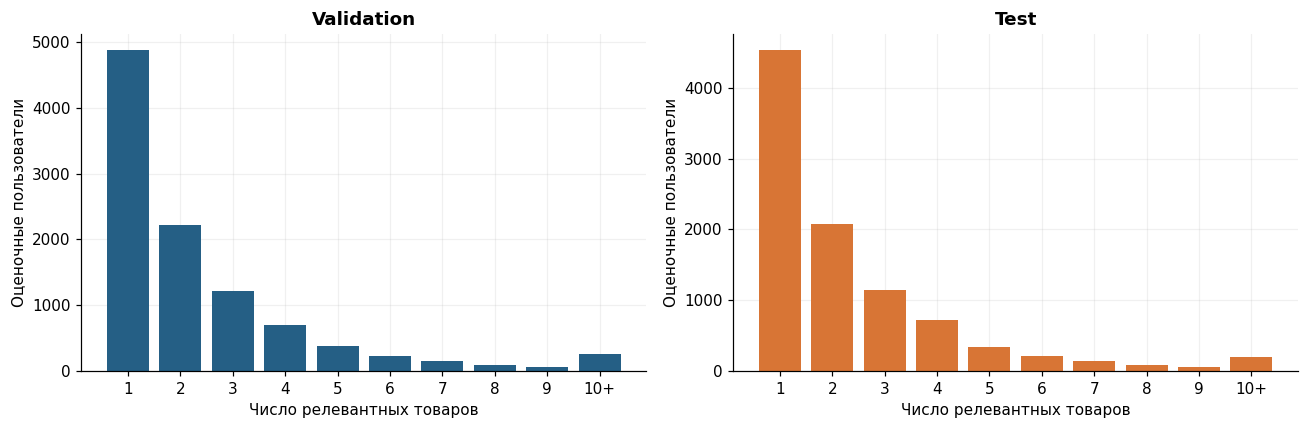

,validation,test
"История до границы, событий",,
1–4,5943,4561
5–9,2766,3149
10+,1498,1811


In [17]:
fig, axes=plt.subplots(1,2,figsize=(12,4))
for ax,(name,view),color in zip(axes,views.items(),COLORS):
    counts=view['queries'].relevant.clip(upper=10).value_counts().reindex(range(1,11),fill_value=0)
    ax.bar(range(1,11),counts.values,color=color)
    ax.set_xticks(range(1,11),[str(i) for i in range(1,10)]+['10+'])
    ax.set(xlabel='Число релевантных товаров',ylabel='Оценочные пользователи',title=name.capitalize())
show_figure('11_relevance_per_query',fig)
activity_slices={}
for name,view in views.items():
    bins=pd.cut(view['queries'].history,bins=[0,4,9,np.inf],labels=['1–4','5–9','10+'])
    activity_slices[name]=bins.value_counts(sort=False).to_dict()
display(pd.DataFrame(activity_slices).rename_axis('История до границы, событий'))

### 9. Метрики и правила общего сравнения

**Основная метрика до подбора — NDCG@10. Дополнительная — Recall@10.**
Обе метрики считаем на бинарной релевантности `rating >= 4` для всех моделей, независимо от их
обучающего таргета. Для пользователя $u$ пусть $L_u=(i_1,\ldots,i_{10})$, $y_j=\mathbb{1}[i_j\in R_u]$.

$$\mathrm{Recall@10}_u = \frac{|L_u\cap R_u|}{|R_u|}$$
$$\mathrm{NDCG@10}_u = \frac{\sum_{j=1}^{10} y_j/\log_2(j+1)}
{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)}$$

Recall показывает, какую долю доступных будущих положительных объектов нашли.
NDCG дополнительно учитывает место объекта: верхние позиции важнее. Наблюдаемый ноль не
равен доказанному неприятию товара, поэтому результат — метрика поиска будущих наблюдаемых
положительных отзывов, не измерение причинного эффекта рекомендаций.

- Усреднение **macro по пользователям**, каждый оценочный пользователь имеет одинаковый вес.
- Ранжировать все $C_u$, без подмешивания будущих новых объектов и без sampled negatives.
  Выборка случайных кандидатов способна менять порядок моделей:
  [Krichene & Rendle, On Sampled Metrics](https://research.google/pubs/on-sampled-metrics-for-item-recommendation/).
- На выдаче ровно 10 разных товаров; исключить все ранее известные пользователю товары.
  Равные scores разрешать по лексикографическому ASIN. Если персональный скор недоступен
  или хотя бы один score кандидата — NaN/inf, всю выдачу этого пользователя заменить
  общим fallback: число fit-оценок 4–5 товара по убыванию, затем ASIN по возрастанию.
  Маска известных товаров и набор кандидатов сохраняются; долю fallback отчитывать.
- Для **всех пяти моделей** на каждом этапе одинаковы fit, оценочные пользователи, $R_u$, $C_u$,
  маски, timestamp запроса и агрегирование. Изменение таргета пятой модели не меняет эти множества.
- Подбирать все гиперпараметры только по validation NDCG@10; пространства поиска и бюджеты
  фиксировать до запусков. При равной основной метрике выбирать более простую/быструю настройку;
  дополнительную метрику не превращать в незаявленный критерий выбора.
- Затем зафиксировать настройки, переобучить на train ∪ validation и один раз сравнить на test.
  Для стохастических методов использовать один заранее заданный seed; при исследовании
  устойчивости заранее зафиксировать общий набор seeds, а не выбирать лучший запуск по test.
- Дополнительно: catalog coverage@10 и результаты по длине **fit-истории**; границы популярности
  head/tail определять только по fit. Это диагностика, не дополнительные критерии подбора.
- Для итоговых различий: paired bootstrap по одним и тем же пользователям, 2 000 повторов,
  seed 42, 95% интервалы для метрик и разностей. Пользователей ресемплировать совместно для
  сравниваемых моделей. Такая оценка не учитывает всю межпользовательскую зависимость и
  вариативность переобучения, поэтому небольшие различия не объявлять надёжным преимуществом автоматически.

Если для iALS выберем положительные события как вход, пользователи с одними оценками 1–3 всё
равно остаются в общей оценочной когорте. Число таких историй приведено выше; адаптер метода
должен корректно обработать их или применить общий fallback. EASE/SLIM/FM не получают собственные
наборы «удобных» пользователей.

### 10. Сохранение протокола и проверка разбиения

Сохраняем временные файлы локально в `data/splits/`, а в репозитории — только агрегированные
отчёты и параметры. В файлах сохраняются все события соответствующего периода, включая cold-start:
маски основной оценки определяются описанными правилами. Отдельный файл train+validation не
нужен — это конкатенация train и validation. Этот этап только готовит разбиение; обучение первой модели находится в разделе 12.

In [18]:
split_dir=ROOT/'data/splits'
split_dir.mkdir(parents=True,exist_ok=True)
split_manifest={}
for name,frame in partitions.items():
    path=split_dir/f'{name}.csv.gz'
    with deterministic_gzip(path) as stream:
        frame[['user_id','item_id','rating','timestamp']].to_csv(stream,index=False,lineterminator='\n')
    split_manifest[name]={
        'path':str(path.relative_to(ROOT)), 'sha256':sha256(path),
        'interactions':len(frame), 'users':frame.user_id.nunique(), 'items':frame.item_id.nunique(),
        'start_utc':frame.datetime.min().isoformat(), 'end_utc':frame.datetime.max().isoformat()}

protocol={
    'version':1, 'status':'fixed_before_model_training', 'seed':SEED, 'k':K,
    'relevance':{'rating_at_least':RELEVANCE_THRESHOLD,'binary':True},
    'validation_start_utc':VALIDATION_START.isoformat(), 'test_start_utc':TEST_START.isoformat(),
    'validation_fit':'train', 'test_fit':'train + validation, after hyperparameter selection',
    'query_time':'start of each holdout window; frozen history throughout the window',
    'catalog':'all items observed in the stage fit, regardless of rating',
    'candidates':'entire fit catalog minus all items seen by that user in fit; no sampling',
    'evaluation_users':'known in stage fit, >=1 available relevant holdout item, >=10 candidates',
    'cold_start':'excluded from primary metrics; counts and coverage reported; retained in split files',
    'users_without_relevance':'excluded from macro Recall/NDCG; counts reported',
    'missing_personal_scores':'if personalization is unavailable or any candidate score is non-finite, replace the entire user ranking by descending count of rating>=4 fit events; ties by item_id; never drop users',
    'ties':'descending finite score, then ascending lexicographic item_id',
    'primary_metric':'macro NDCG@10', 'secondary_metric':'macro Recall@10',
    'diagnostics':['catalog coverage@10','fit-history slices 1-4 / 5-9 / 10+','fit-popularity slices'],
    'confidence_intervals':{'method':'paired user bootstrap','resamples':2000,'confidence':.95,'seed':SEED},
    'feature_preprocessing':'fit only; rebuild on train+validation for final test',
    'limitations':['source and restored 5-core use full-period cohort selection',
                  'catalog metadata are crawl-time snapshots; historical availability unverified',
                  'review timestamp is day-resolution feedback, not purchase time',
                  'unequal validation/test horizons and temporal drift',
                  'warm-start observed-rating retrieval, not causal online recommendation quality'],
    'input_checksums':audit['outputs'], 'splits':split_manifest,
    'evaluation_diagnostics':{name:view['stats'] for name,view in views.items()},
}
(ROOT/'reports/evaluation_protocol.json').write_text(
    json.dumps(protocol,ensure_ascii=False,indent=2,sort_keys=True)+'\n',encoding='utf-8')
eda_summary={
    'interactions':len(interactions),'users':n_users,'items':n_items,'density':density,
    'positive_rating_fraction':positive_share,'top_one_percent_item_interaction_share':top_one_share,
    'top_ten_percent_item_interaction_share':top_ten_share,'same_day_history_user_fraction':same_day_share,
    'timestamp_midnight_fraction':midnight_share,'duplicate_normalized_title_items':duplicate_title_items,
    'metadata_coverage':coverage.to_dict(orient='index'),'unique_nonempty_brands':len(brand_counts),
    'unique_categories_including_root':len(category_counts)+1,
    'user_history_slices':activity_slices,'library_versions':versions,
}
(ROOT/'reports/eda_summary.json').write_text(
    json.dumps(eda_summary,ensure_ascii=False,indent=2,sort_keys=True)+'\n',encoding='utf-8')
for name,frame in partitions.items():
    restored=pd.read_csv(split_dir/f'{name}.csv.gz',dtype={'user_id':'string','item_id':'string',
        'rating':'int8','timestamp':'int64'})
    pd.testing.assert_frame_equal(frame[['user_id','item_id','rating','timestamp']].reset_index(drop=True),restored)
print('Разбиение хронологично; файлы перечитаны без изменений; параметры и контрольные суммы сохранены.')

Разбиение хронологично; файлы перечитаны без изменений; параметры и контрольные суммы сохранены.


### 11. Выводы по EDA

In [19]:
display(Markdown(f'''
1. **Датасет подходит по размеру:** {fmt(len(interactions))} взаимодействий, {fmt(n_users)} пользователей,
   {fmt(n_items)} товаров. Разреженность **{(1-density):.3%}**; медианная история —
   **{user_activity.median():g}** взаимодействий. Для сравнения методов нужен анализ коротких профилей.
2. **Есть выраженный перекос обратной связи:** {positive_share:.1%} оценок — 4–5.
   Выбираем поиск положительно оценённых новых товаров и метрики top-10, а не accuracy по оценке.
3. **Популярность неравномерна:** верхние 10% товаров дают {top_ten_share:.1%} событий.
   В будущем рядом с NDCG/Recall полезны coverage и срезы по популярности, определённой на fit.
4. **Метаданных достаточно для FM:** бренд есть у {coverage.loc['Бренд','Товары, %']:.2f}% товаров,
   категории у {coverage.loc['Категории','Товары, %']:.2f}%. Первая версия признаков — ID + бренд + категории;
   полезность метаданных предстоит подтвердить абляцией, а не наличием полей.
5. **Время учитываем глобально:** train до 2016, validation за 2016, test с 2017.
   Момент рекомендации фиксирован на границе окна. После подбора предусмотрен refit на train+validation.
6. **Область применимости ограничена:** warm-start оценка охватывает
   {test_view['stats']['positive_interaction_coverage']:.1%} положительных событий test;
   исходный 5-core, снимок каталога, задержка отзывов и длинный test-горизонт ограничивают переносимость.

**Следующий раздел:** реализация первой модели и общего оценщика, фиксированное пространство поиска
и подбор на validation. Качество остальных методов и эффект метаданных/кастомного сигнала ещё
не исследованы. Запрет на использование датасета из семинаров ещё нужно сверить с курсом.
'''))


1. **Датасет подходит по размеру:** 452 989 взаимодействий, 50 546 пользователей,
   16 859 товаров. Разреженность **99.947%**; медианная история —
   **6** взаимодействий. Для сравнения методов нужен анализ коротких профилей.
2. **Есть выраженный перекос обратной связи:** 79.3% оценок — 4–5.
   Выбираем поиск положительно оценённых новых товаров и метрики top-10, а не accuracy по оценке.
3. **Популярность неравномерна:** верхние 10% товаров дают 47.9% событий.
   В будущем рядом с NDCG/Recall полезны coverage и срезы по популярности, определённой на fit.
4. **Метаданных достаточно для FM:** бренд есть у 99.32% товаров,
   категории у 99.13%. Первая версия признаков — ID + бренд + категории;
   полезность метаданных предстоит подтвердить абляцией, а не наличием полей.
5. **Время учитываем глобально:** train до 2016, validation за 2016, test с 2017.
   Момент рекомендации фиксирован на границе окна. После подбора предусмотрен refit на train+validation.
6. **Область применимости ограничена:** warm-start оценка охватывает
   58.0% положительных событий test;
   исходный 5-core, снимок каталога, задержка отзывов и длинный test-горизонт ограничивают переносимость.

**Следующий раздел:** реализация первой модели и общего оценщика, фиксированное пространство поиска
и подбор на validation. Качество остальных методов и эффект метаданных/кастомного сигнала ещё
не исследованы. Запрет на использование датасета из семинаров ещё нужно сверить с курсом.


### 12. Первая модель: item-based коллаборативная фильтрация

Реализация — `models/item_knn.py`. Общая индексация — `data_utils.py`, оценщик — `evaluation.py`.
Используются NumPy/SciPy для матричных операций; готовых recommender/kNN/metric API нет.
Метод относится к item-based neighborhood CF ([Sarwar et al., 2001](https://files.grouplens.org/papers/www10_sarwar.pdf)).
Ниже определена конкретная бинарная версия со shrinkage; это не утверждение о точном повторении всех вариантов статьи.

Пусть $B_{ui}=1$ только для **fit-оценки 4–5**, иначе 0. Все оценки 1–3 остаются в истории и
каталоге, но не создают положительную связь между товарами. Обозначим
$c_{ij}=\sum_u B_{ui}B_{uj}$ и $n_i=\sum_u B_{ui}$. Тогда:

$$s_{ij}=\begin{cases}
\dfrac{c_{ij}}{\sqrt{n_i n_j}}\dfrac{c_{ij}}{c_{ij}+\lambda}, & i\ne j,\ c_{ij}>0,\\
0,&\text{иначе.}
\end{cases}$$

При $\lambda=0$ получаем обычное cosine similarity. При $\lambda>0$ совпадение на одном-двух
пользователях получает меньший вес. Для каждого **целевого** товара $i$ сохраняем $m$ соседей
с максимальным $s_{ij}$, равные веса разрешаем по ASIN. После усечения граф не обязан быть симметричным.

$$\widehat r_{ui}=\sum_{j\in N_m(i)} B_{uj}s_{ij}.$$

Это сумма вкладов понравившихся товаров без дополнительной нормировки. Матрица графа содержит
целевые товары по строкам, поэтому пакетный прогноз равен $B_{batch}S_{pruned}^{T}$.
Разреженные матрицы сохраняют весь fit-каталог, включая товары без положительных оценок.

Если нет положительной истории или **ни у одного неизвестного пользователю кандидата нет
положительного соседского вклада**, ItemKNN сигнализирует отсутствие персонального прогноза.
Общий оценщик применяет ранее зафиксированную популярность fit-оценок 4–5. Пользователь остаётся
в метриках. При частичной поддержке нулевой хвост ранжируется по ASIN, без незаявленного popular backfill.
Это определение отсутствия сигнала зафиксировано в конфигурации до поиска.

### 13. Общий оценщик и проверки корректности

`FitData` строит ID-словари только по fit. `EvaluationContext` один раз фиксирует пользователей,
релевантность, каталог и историю. Каждая модель предоставляет `score_batch(user_ids, query_timestamp=...)`
и тот же порядок столбцов каталога; оценщик проверяет отпечаток fit и соответствие каталога.
Временем запроса остаётся начало будущего окна. Скорер не получает validation-метки.

Оценщик сам исключает **все** ранее оценённые товары, обрабатывает NaN/inf на кандидатах, выбирает
точный top-10 с разрешением граничных ties по ASIN и считает macro NDCG/Recall, coverage и fallback.
Даже при вычислении top-10 через partition граничные равенства обрабатываются явно — иначе набор
выбранных товаров зависел бы от неопределённого порядка partition.

Проверки запускаются отдельно:
```sh
python -m unittest discover -s tests -v
```
В `tests/test_recommendation.py` — 12 проверок: формулы на ручном примере, ориентация графа,
нулевые профили, отрицательная история, запрет временной утечки, ties, метрики с несколькими
релевантными товарами, macro-усреднение, fallback, неизменность результата при размере batch,
форма scores и парный bootstrap. Формулы метрик проверены вручную, а top-k — полным сортированием.

In [20]:
from models.item_knn import ItemKNN
from evaluation import EvaluationContext, evaluate_model

search_configuration=json.loads((ROOT/'configs/item_knn_search.json').read_text())
display(pd.Series({
    'Метод':search_configuration['model'],
    'Число соседей':str(search_configuration['grid']['n_neighbors']),
    'Shrinkage':str(search_configuration['grid']['shrinkage']),
    'Бюджет':search_configuration['budget'],
    'Критерий выбора':search_configuration['selection'],
    'Равенство основной метрики':search_configuration['tie_break'],
},name='Зафиксировано до запуска').to_frame())


,Зафиксировано до запуска
Метод,ItemKNN
Число соседей,"[20, 50, 100, 200]"
Shrinkage,"[0.0, 10.0, 50.0]"
Бюджет,12
Критерий выбора,maximum validation macro NDCG@10
Равенство основной метрики,"fewer neighbors, then smaller shrinkage; no se..."


### 14. Подбор только на validation

Сетка: $m\in\{20,50,100,200\}$, $\lambda\in\{0,10,50\}$ — **12 конфигураций**.
Никакой случайной выборки пользователей или кандидатов: участвует вся validation-когорта.
Основная метрика — NDCG@10. При её точном равенстве выбираем меньше соседей, затем меньшее
shrinkage; Recall не используется как скрытый критерий выбора. Сетку после просмотра результатов
не расширяем. Все модели детерминированы; seed 42 используется в bootstrap.

`search_plan.json` записывается до первой подгонки. Эксперимент загружает только временные файлы
train и validation, проверяет их контрольные суммы и сверяет состав когорты с протоколом.
Test-события скрипт не читает, на train+validation пока не переобучает.

В качестве контроля считаем неперсонализированную популярность: число fit-оценок 4–5 товара.
Для неё одинаковые каталог, пользователи, маски и метрики. Fallback rate у этого контроля означает
долю аварийной замены выдачи, а не наличие персонализации: сам контроль неперсонализирован.

In [21]:
validation_runs=load_validation_report(ROOT,'item_knn')
assert validation_runs['summary']['cohort']['evaluation_users']==validation_view['stats']['evaluation_users']
assert validation_runs['summary']['cohort']['relevant_interactions']==validation_view['stats']['relevant_interactions']
assert validation_runs['summary']['completed_trials']==12
assert validation_runs['summary']['test_evaluated'] is False
search_results=validation_runs['search'].sort_values(
    ['ndcg_at_10','n_neighbors','shrinkage'],ascending=[False,True,True]).reset_index(drop=True)
columns=['n_neighbors','shrinkage','ndcg_at_10','recall_at_10','catalog_coverage_at_10',
         'fallback_rate','fit_seconds','evaluation_seconds']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(search_results[columns])

,n_neighbors,shrinkage,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,fit_seconds,evaluation_seconds
0,100,10.000000,0.021111,0.032179,0.738798,0.051435,0.337878,1.277437
1,200,10.000000,0.021053,0.031936,0.734369,0.051435,0.411082,1.439080
2,50,10.000000,0.021031,0.032057,0.746566,0.051435,0.286753,1.079337
3,200,50.000000,0.020942,0.032029,0.711516,0.051435,0.411943,1.432614
4,100,50.000000,0.020885,0.031872,0.715753,0.051435,0.447174,1.278256
5,50,50.000000,0.020839,0.031999,0.725510,0.051435,0.284098,1.091421
6,20,10.000000,0.020710,0.031267,0.765695,0.051533,0.250426,1.007829
7,20,50.000000,0.020543,0.031112,0.748042,0.051533,0.246629,1.016145
8,200,0.000000,0.015092,0.022641,0.854988,0.051435,0.404334,1.423342
9,20,0.000000,0.015070,0.022635,0.857235,0.051533,0.264489,0.999462


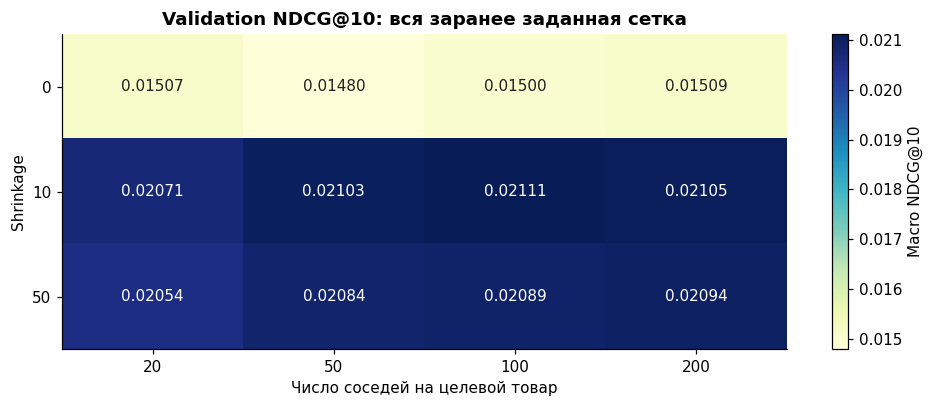

In [22]:
heat=validation_runs['search'].pivot(index='shrinkage',columns='n_neighbors',values='ndcg_at_10').sort_index()
fig,ax=plt.subplots(figsize=(9,3.8))
image=ax.imshow(heat.values,cmap='YlGnBu',aspect='auto')
ax.set_xticks(range(len(heat.columns)),heat.columns)
ax.set_yticks(range(len(heat.index)),[f'{x:g}' for x in heat.index])
for row in range(heat.shape[0]):
    for col in range(heat.shape[1]):
        value=heat.iloc[row,col]
        text_color='white' if value>(heat.values.min()+heat.values.max())/2 else '#202020'
        ax.text(col,row,f'{value:.5f}',ha='center',va='center',color=text_color)
ax.grid(False)
ax.set(xlabel='Число соседей на целевой товар',ylabel='Shrinkage',title='Validation NDCG@10: вся заранее заданная сетка')
fig.colorbar(image,ax=ax,label='Macro NDCG@10')
show_figure('12_item_knn_validation_grid',fig)

### 15. Результат первой модели и контроль популярности

Далее представлены **validation-результаты**. Лучшая конфигурация уже выбиралась на этих же
пользователях, поэтому её преимущество и интервалы не являются независимой финальной проверкой.
Времена зависят от машины и нагрузки; это фактические замеры отдельных запусков, а не метрика подбора.
Общее чтение файлов и построение общей индексации не включены в fit_seconds отдельных конфигураций.

,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds
model,,,,,,,
Popularity (control),0.005779,0.010252,0.000963,0.000000,10207,1.224501,0.000000
ItemKNN (selected),0.021111,0.032179,0.738798,0.051435,10207,1.277437,0.337878


estimate   ci_low  ci_high
metric       estimate_for                            
ndcg_at_10   ItemKNN       0.021111 0.019287 0.023026
             Popularity    0.005779 0.004977 0.006649
             difference    0.015333 0.013472 0.017275
recall_at_10 ItemKNN       0.032179 0.029379 0.035092
             Popularity    0.010252 0.008781 0.011881
             difference    0.021928 0.018886 0.025032

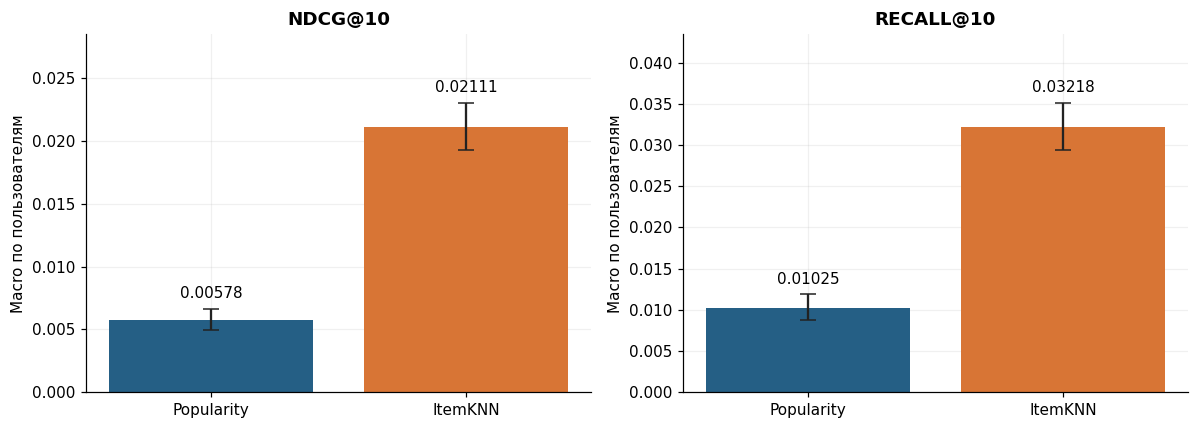

In [23]:
comparison=validation_runs['comparison']
intervals=validation_runs['intervals']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(comparison.set_index('model'))
    display(intervals.set_index(['metric','estimate_for']))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,metric in zip(axes,['ndcg_at_10','recall_at_10']):
    values=comparison[metric].to_numpy()
    ax.bar(['Popularity','ItemKNN'],values,color=COLORS[:2])
    for position,(label,value) in enumerate(zip(['Popularity','ItemKNN'],values)):
        row=intervals[(intervals.metric==metric)&(intervals.estimate_for==label)].iloc[0]
        errors=np.maximum(0,np.array([[value-row.ci_low],[row.ci_high-value]]))
        ax.errorbar(position,value,yerr=errors,fmt='none',color='#222222',capsize=5)
        ax.text(position,row.ci_high+max(values)*.04,f'{value:.5f}',ha='center')
    ax.set(title=metric.replace('_at_','@').upper(),ylabel='Macro по пользователям',ylim=(0,max(values)*1.35))
show_figure('13_item_knn_vs_popularity',fig)

### 16. Диагностика: история, популярность и fallback

Срезы истории определяются **только по train**. Head — верхние 10% fit-каталога по числу
положительных fit-отзывов (ties по ASIN); tail — остальные 90%. В таблице head/tail Recall
пересчитывается по соответствующей части релевантных объектов, но рекомендации остаются прежними.
Пользователь может участвовать в обоих срезах, поэтому их метрики не усредняются в общий Recall.

users     ndcg   recall  fallback_rate
model      history_slice                                        
Popularity 1-4             5943 0.006765 0.011434       0.000000
           5-9             2766 0.004511 0.009421       0.000000
           10+             1498 0.004205 0.007094       0.000000
ItemKNN    1-4             5943 0.021634 0.032072       0.086152
           5-9             2766 0.019806 0.033355       0.004700
           10+             1498 0.021447 0.030435       0.000000

users  relevant_interactions  recall_at_10
model      item_slice                                                       
Popularity head_top_10_percent     5704                  10248      0.024125
           tail_other_90_percent   7765                  15398      0.000000
ItemKNN    head_top_10_percent     5704                  10248      0.056922
           tail_other_90_percent   7765                  15398      0.014238

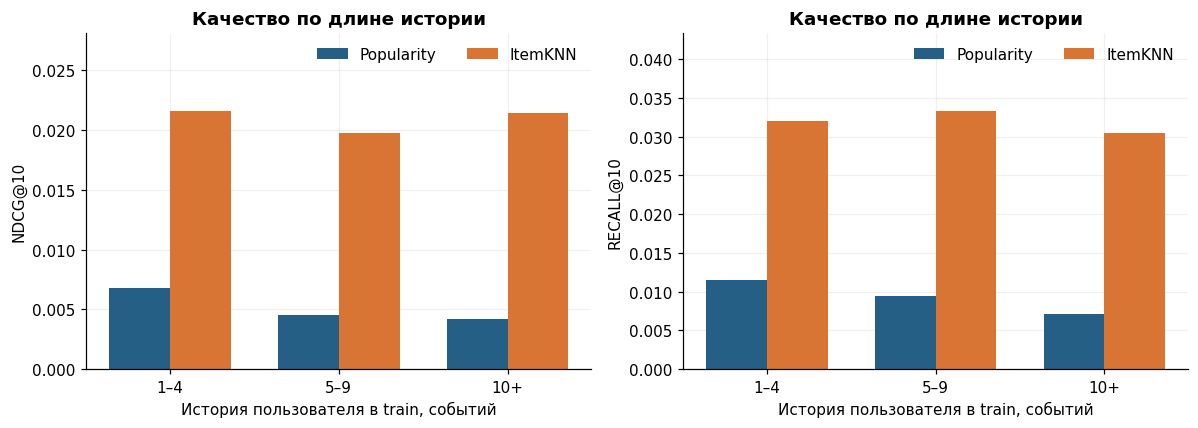

In [24]:
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(validation_runs['history_slices'])
    display(validation_runs['popularity_slices'])
fig,axes=plt.subplots(1,2,figsize=(11,4))
x=np.arange(3);width=.36
for ax,metric in zip(axes,['ndcg','recall']):
    for offset,(model,color) in enumerate(zip(['Popularity','ItemKNN'],COLORS)):
        values=validation_runs['history_slices'].loc[model][metric].to_numpy()
        ax.bar(x+(offset-.5)*width,values,width,label=model,color=color)
    ax.set_xticks(x,['1–4','5–9','10+'])
    ax.set(xlabel='История пользователя в train, событий',ylabel=metric.upper()+'@10',title='Качество по длине истории')
    ax.set_ylim(0,validation_runs['history_slices'][metric].max()*1.3)
    ax.legend(frameon=False,ncols=2)
show_figure('14_item_knn_history_slices',fig)

### 17. Выводы по первой модели

In [25]:
best_parameters=validation_runs['summary']['best_params']
best_metrics=validation_runs['summary']['best_validation_metrics']
control_metrics=validation_runs['summary']['popularity_validation_metrics']
relative_ndcg=best_metrics['ndcg_at_10']/control_metrics['ndcg_at_10']-1 if control_metrics['ndcg_at_10'] else float('nan')
unshrunk_ndcg=float(validation_runs['search'].loc[
    (validation_runs['search'].n_neighbors==best_parameters['n_neighbors']) &
    (validation_runs['search'].shrinkage==0),'ndcg_at_10'].iloc[0])
ndcg_difference=intervals[(intervals.metric=='ndcg_at_10')&(intervals.estimate_for=='difference')].iloc[0]
recall_difference=intervals[(intervals.metric=='recall_at_10')&(intervals.estimate_for=='difference')].iloc[0]
display(Markdown(f'''
- Выбраны **{best_parameters['n_neighbors']} соседей** и **shrinkage {best_parameters['shrinkage']:g}**
  из заранее заданных 12 вариантов. Критерий — только validation NDCG@10.
- **ItemKNN:** NDCG@10 = **{best_metrics['ndcg_at_10']:.6f}**,
  Recall@10 = **{best_metrics['recall_at_10']:.6f}**.
  **Популярность:** {control_metrics['ndcg_at_10']:.6f} / {control_metrics['recall_at_10']:.6f} соответственно.
- Относительное изменение NDCG к контролю — **{relative_ndcg:+.1%}**.
  Парный 95% bootstrap-интервал разности NDCG:
  **[{ndcg_difference.ci_low:.6f}; {ndcg_difference.ci_high:.6f}]**;
  разности Recall: **[{recall_difference.ci_low:.6f}; {recall_difference.ci_high:.6f}]**.
  Интервалы описывают validation после выбора конфигурации и не устраняют оптимизм подбора.
- В оценке сохранены все **{fmt(best_metrics['users'])}** пользователей.
  Fallback использован для **{best_metrics['fallback_rate']:.2%}**;
  покрытие каталога top-10 — **{best_metrics['catalog_coverage_at_10']:.2%}**,
  у контроля — **{control_metrics['catalog_coverage_at_10']:.2%}**.
- При том же числе соседей обычный cosine без shrinkage даёт NDCG@10
  **{unshrunk_ndcg:.6f}**; добавление выбранного shrinkage изменило его на
  **{best_metrics['ndcg_at_10']/unshrunk_ndcg-1:+.1%}**. После 50 соседей результаты
  при shrinkage 10 близки; максимум на 100 соседях не доказывает надёжного превосходства
  над соседними настройками. Это сравнение внутри заранее заданной validation-сетки.
  Ни оптимальность за пределами сетки, ни превосходство над другими методами
  из этих результатов не следуют.

Файлы: `reports/item_knn_validation/` — план, все 12 запусков, сравнение, срезы и интервалы.
Персональные метрики и индексы выдач сохранены только локально в `data/validation/item_knn/`.
**На этапе этого подбора test не использовался.** Завершённое финальное сравнение приведено в разделах 40–45.
'''))


- Выбраны **100 соседей** и **shrinkage 10**
  из заранее заданных 12 вариантов. Критерий — только validation NDCG@10.
- **ItemKNN:** NDCG@10 = **0.021111**,
  Recall@10 = **0.032179**.
  **Популярность:** 0.005779 / 0.010252 соответственно.
- Относительное изменение NDCG к контролю — **+265.3%**.
  Парный 95% bootstrap-интервал разности NDCG:
  **[0.013472; 0.017275]**;
  разности Recall: **[0.018886; 0.025032]**.
  Интервалы описывают validation после выбора конфигурации и не устраняют оптимизм подбора.
- В оценке сохранены все **10 207** пользователей.
  Fallback использован для **5.14%**;
  покрытие каталога top-10 — **73.88%**,
  у контроля — **0.10%**.
- При том же числе соседей обычный cosine без shrinkage даёт NDCG@10
  **0.015001**; добавление выбранного shrinkage изменило его на
  **+40.7%**. После 50 соседей результаты
  при shrinkage 10 близки; максимум на 100 соседях не доказывает надёжного превосходства
  над соседними настройками. Это сравнение внутри заранее заданной validation-сетки.
  Ни оптимальность за пределами сетки, ни превосходство над другими методами
  из этих результатов не следуют.

Файлы: `reports/item_knn_validation/` — план, все 12 запусков, сравнение, срезы и интервалы.
Персональные метрики и индексы выдач сохранены только локально в `data/validation/item_knn/`.
**На этапе этого подбора test не использовался.** Завершённое финальное сравнение приведено в разделах 40–45.


### 18. Вторая модель: iALS с нуля

Реализация — `models/ials.py`, постановка implicit ALS следует
[Hu, Koren, Volinsky (2008)](https://yifanhu.net/PUB/cf.pdf).
Берём бинарное предпочтение $p_{ui}=1$ для fit-оценки 4–5, иначе 0, и
$c_{ui}=1+\alpha p_{ui}$. В частности, **ненаблюдаемые пары имеют confidence 1**, а не 0.
Оценки 1–3 не становятся положительными сигналами, но остаются в общей маске истории.
Это базовый iALS для задания №2; подбор confidence не является кастомным таргетом задания №5.

$$L=\sum_{u,i}c_{ui}(p_{ui}-x_u^T y_i)^2+
\lambda\left(\sum_u\|x_u\|^2+\sum_i\|y_i\|^2\right).$$

При фиксированных $Y$ обновляем каждого пользователя точным решением системы:

$$\left(Y^TY+\alpha\sum_{i:p_{ui}=1}y_i y_i^T+\lambda I\right)x_u
=(1+\alpha)\sum_{i:p_{ui}=1}y_i.$$

Аналогично обновляем товары при фиксированных $X$. Регуляризация постоянная, не умножается
на степень пользователя/товара. Полную матрицу confidence не создаём: $Y^TY$ учитывает все пары.
Строки одинаковой степени обрабатываются пакетно — это вычислительная оптимизация без сэмплирования
и без изменения системы. Используется `numpy.linalg.solve`, а не обращение матрицы или готовая ALS.

Начальные item-факторы случайны с seed 42, user-факторы нулевые. Пустые положительные профили имеют
точное оптимальное решение 0; такие пользователи остаются в оценке через общий fallback.
Прогноз $\widehat r_{ui}=x_u^Ty_i$ ранжируется общим оценщиком. Отрицательный latent score допустим
и сам по себе не означает отсутствие персонализации.

### 19. План подбора и изоляция test

До обучения зафиксирован `configs/ials_search.json`:
$f\in\{16,32,64\}$, $\alpha\in\{10,40\}$, $\lambda\in\{0.1,1\}$ — **12 конфигураций**.
Для каждой ровно **15 полных итераций ALS**, один seed 42; early stopping нет.
Критерий — validation macro NDCG@10; ties: меньше факторов, меньше alpha, больше lambda.
Пространство после просмотра результатов не расширяется.

Контроль потерь — точная полная функция $L$, вычисленная через Gram-матрицы и поправку на
положительные пары. Она должна не возрастать после ALS-итерации; это проверка реализации,
а не критерий подбора. Потери разных alpha/lambda не сравниваем как качество рекомендаций.

Сравнение использует **сохранённую лучшую CF-конфигурацию 100 соседей / shrinkage 10**.
Проверяются исходные файлы, контрольные суммы выдач и отпечаток общей когорты. CF не перенастраивается.
Все 10 207 пользователей, каталог из 15 578 товаров, ground truth, маски и fallback общие.

Секция iALS выполняется в новом ядре отдельно от старых EDA/CF-ячеек:
```sh
python scripts/execute_notebook.py --section ials
```
Этот режим блокирует открытие test CSV, общего файла взаимодействий и сырой полной истории.
Сохранённые EDA/CF-выводы не пересчитываются. Счётчики выполнения новых ячеек относятся к отдельному ядру.
Скрипт подбора читает только `data/splits/train.csv.gz` и `validation.csv.gz`.
Полный `Run All` воспроизводит также исторический EDA; для текущего validation-only этапа используем
только `--section ials`.

Если совпадают код, конфигурация, данные и контрольные суммы результатов, можно переиспользовать
завершённый подбор. Для нового полного расчёта изменить `REUSE_IALS_RESULTS=False` ниже
либо выполнить `python scripts/tune_ials.py` без `--reuse-completed`.

In [26]:
ials_configuration=json.loads((ROOT/'configs/ials_search.json').read_text())
display(pd.Series({
    'Число факторов':str(ials_configuration['grid']['n_factors']),
    'Alpha':str(ials_configuration['grid']['alpha']),
    'Lambda':str(ials_configuration['grid']['regularization']),
    'Итерации':ials_configuration['n_iterations'],
    'Seed':ials_configuration['seed'],
    'Конфигурации':ials_configuration['budget'],
    'Критерий':ials_configuration['selection'],
},name='Зафиксированный план iALS').to_frame())


,Зафиксированный план iALS
Число факторов,"[16, 32, 64]"
Alpha,"[10.0, 40.0]"
Lambda,"[0.1, 1.0]"
Итерации,15
Seed,42
Конфигурации,12
Критерий,maximum validation macro NDCG@10


In [27]:
ials_runs=load_validation_report(ROOT,'ials')
assert ials_runs['summary']['completed_trials']==12
assert ials_runs['summary']['test_evaluated'] is False
assert ials_runs['summary']['cohort_fingerprint']==json.loads((ROOT/'reports/item_knn_validation/summary.json').read_text())['cohort_fingerprint']
assert ials_runs['summary']['cohort']['evaluation_users']==10207
ials_search=ials_runs['search'].sort_values(
    ['ndcg_at_10','n_factors','alpha','regularization'],ascending=[False,True,True,False])
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(ials_search[['n_factors','alpha','regularization','ndcg_at_10','recall_at_10',
        'catalog_coverage_at_10','fallback_rate','fit_seconds','evaluation_seconds','last_relative_loss_decrease']])

,n_factors,alpha,regularization,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,fit_seconds,evaluation_seconds,last_relative_loss_decrease
10,64,40.000000,0.100000,0.021893,0.034360,0.143215,0.050260,44.419219,1.582736,0.001003
11,64,40.000000,1.000000,0.021805,0.034215,0.143728,0.050260,43.294342,1.507528,0.001858
9,64,10.000000,1.000000,0.021663,0.034499,0.090320,0.050260,42.706728,1.517855,0.000588
8,64,10.000000,0.100000,0.021652,0.034341,0.090833,0.050260,43.688998,1.483316,0.000389
7,32,40.000000,1.000000,0.021022,0.032723,0.088330,0.050260,10.940124,1.563004,0.001169
6,32,40.000000,0.100000,0.020868,0.032795,0.087367,0.050260,10.789307,1.466264,0.000705
4,32,10.000000,0.100000,0.020407,0.032499,0.054693,0.050260,11.003952,1.495845,0.000250
5,32,10.000000,1.000000,0.020331,0.032371,0.054500,0.050260,10.767218,1.495836,0.000364
2,16,40.000000,0.100000,0.018547,0.030460,0.050135,0.050260,3.144182,1.447818,0.000386
3,16,40.000000,1.000000,0.018469,0.030347,0.050006,0.050260,3.115576,1.453825,0.000650


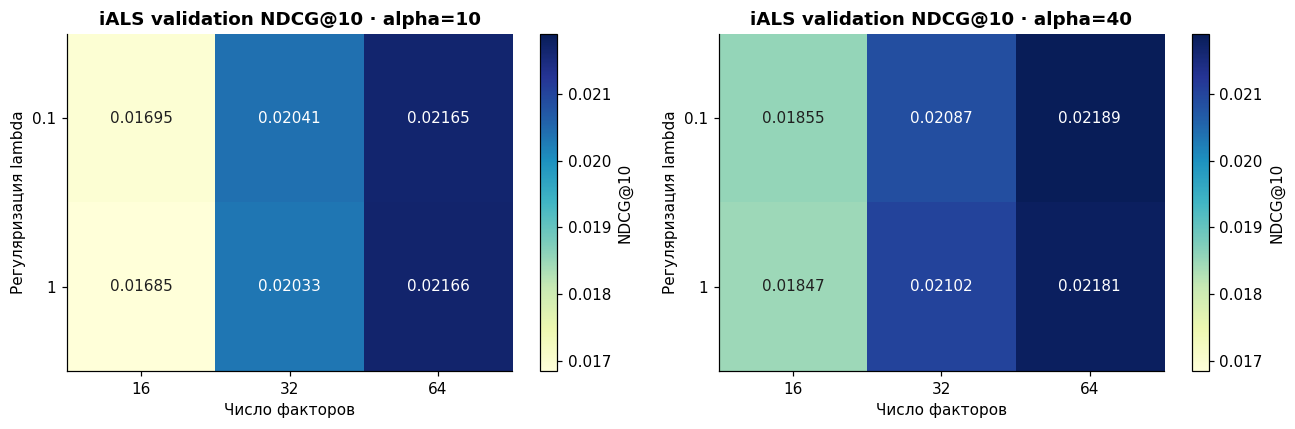

In [28]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
minimum=ials_search.ndcg_at_10.min();maximum=ials_search.ndcg_at_10.max()
for ax,alpha in zip(axes,[10.,40.]):
    table=ials_search[ials_search.alpha==alpha].pivot(index='regularization',columns='n_factors',values='ndcg_at_10').sort_index()
    im=ax.imshow(table.values,cmap='YlGnBu',vmin=minimum,vmax=maximum,aspect='auto')
    ax.set_xticks(range(len(table.columns)),table.columns)
    ax.set_yticks(range(len(table.index)),[f'{v:g}' for v in table.index])
    for row in range(table.shape[0]):
        for col in range(table.shape[1]):
            value=table.iloc[row,col]
            ax.text(col,row,f'{value:.5f}',ha='center',va='center',
                color='white' if value>(minimum+maximum)/2 else '#202020')
    ax.grid(False)
    ax.set(xlabel='Число факторов',ylabel='Регуляризация lambda',title=f'iALS validation NDCG@10 · alpha={alpha:g}')
    fig.colorbar(im,ax=ax,label='NDCG@10')
show_figure('15_ials_validation_grid',fig)

### 20. Оптимизация и ограничение числа итераций

Ни одна конфигурация не использует validation для остановки. График показывает обучение на train.
Относительное снижение в последней итерации отражает ограниченность бюджета, но не гарантирует,
что достигнут глобальный минимум или максимум ranking-метрики. Время fit включает точный подсчёт
потерь; общее чтение/индексация вынесены за замер модели. Время CF взято из ранее записанного запуска,
поэтому разницу времени нельзя считать строгим синхронным бенчмарком аппаратуры.

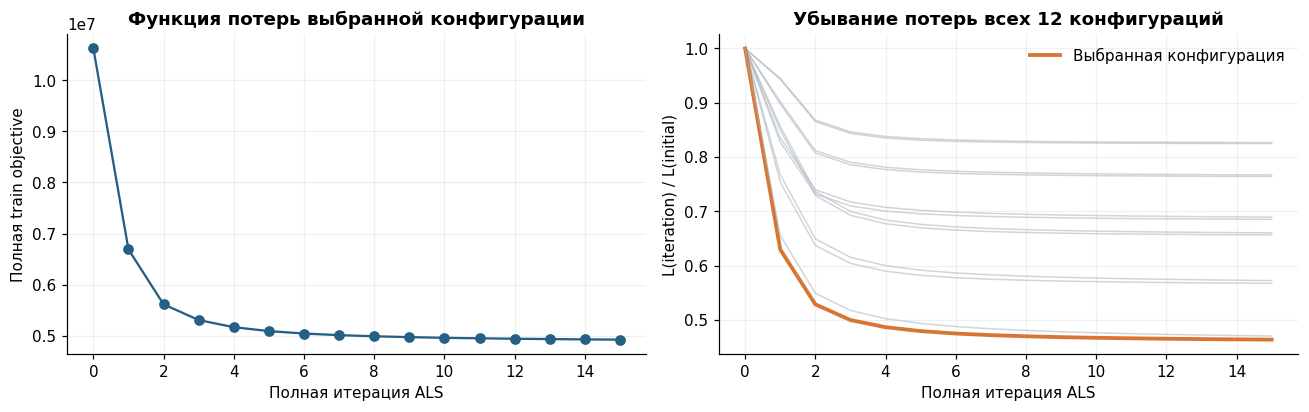

Относительное снижение потерь на последней итерации: 0.1003%


In [29]:
ials_curve=ials_runs['curve']
ials_best_params=ials_runs['summary']['best_params']
ials_winner=ials_search.iloc[0]
ials_best_trial=int(ials_winner.trial)
best_curve=ials_curve[ials_curve.trial==ials_best_trial].sort_values('iteration')
for trial,curve in ials_curve.groupby('trial'):
    values=curve.sort_values('iteration').objective.to_numpy()
    assert len(values)==16 and np.all(np.diff(values)<=1e-7*max(1,values[0]))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(best_curve.iteration,best_curve.objective,marker='o',color=COLORS[0])
axes[0].set(xlabel='Полная итерация ALS',ylabel='Полная train objective',title='Функция потерь выбранной конфигурации')
for trial,curve in ials_curve.groupby('trial'):
    curve=curve.sort_values('iteration');chosen=trial==ials_best_trial
    axes[1].plot(curve.iteration,curve.objective/curve.objective.iloc[0],
        color=COLORS[1] if chosen else '#AAB4BD',linewidth=2.5 if chosen else 1,
        alpha=1 if chosen else .55,label='Выбранная конфигурация' if chosen else None)
axes[1].set(xlabel='Полная итерация ALS',ylabel='L(iteration) / L(initial)',title='Убывание потерь всех 12 конфигураций')
axes[1].legend(frameon=False)
show_figure('16_ials_training_objective',fig)
print('Относительное снижение потерь на последней итерации:',
      f'{ials_winner.last_relative_loss_decrease:.4%}')

### 21. Сравнение iALS и item-based CF на validation

Показываем обе модели после выбора настроек на одном validation. Сравнение не является
независимой финальной проверкой. Парный bootstrap использует одни и те же пользовательские позиции,
2 000 повторов и seed 42. Он не учитывает оптимизм выбора по validation и всю вариативность обучения.
Популярность оставлена как контроль; её предыдущие результаты также проверены по сохранённым выдачам.

,catalog_coverage_at_10,evaluation_seconds,fallback_rate,ndcg_at_10,recall_at_10,users,fit_seconds
model,,,,,,,
Popularity,0.000963,1.224501,0.000000,0.005779,0.010252,10207,0.000000
ItemKNN,0.738798,1.277437,0.051435,0.021111,0.032179,10207,0.337878
iALS,0.143215,1.582736,0.050260,0.021893,0.034360,10207,44.419219


estimate    ci_low  ci_high
metric       estimate_for                             
ndcg_at_10   iALS          0.021893  0.020066 0.023882
             ItemKNN       0.021111  0.019287 0.023026
             difference    0.000782 -0.001015 0.002595
recall_at_10 iALS          0.034360  0.031527 0.037376
             ItemKNN       0.032179  0.029379 0.035092
             difference    0.002181 -0.000720 0.005099

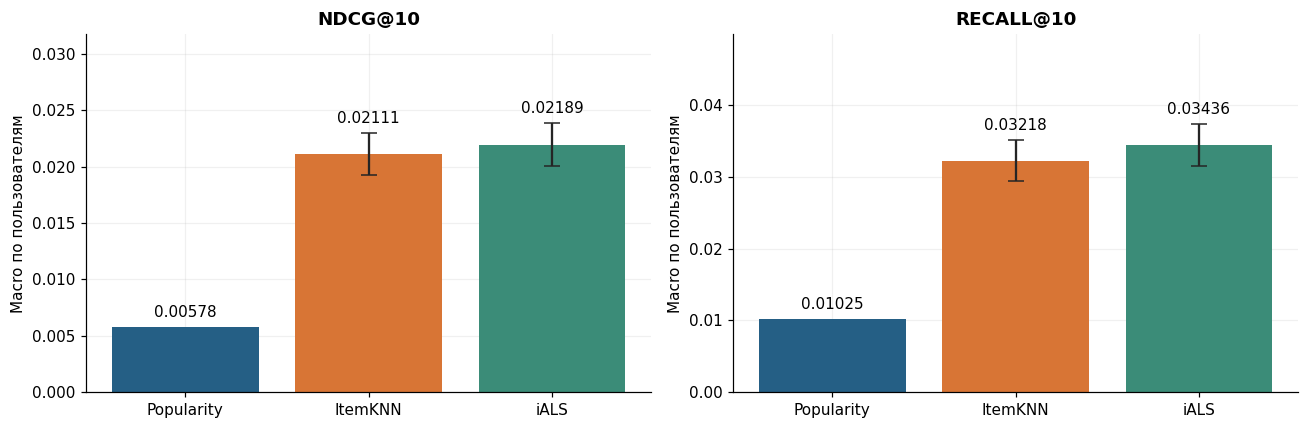

In [30]:
ials_comparison=ials_runs['comparison']
ials_intervals=ials_runs['intervals']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(ials_comparison.set_index('model'))
    display(ials_intervals.set_index(['metric','estimate_for']))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric in zip(axes,['ndcg_at_10','recall_at_10']):
    values=ials_comparison[metric].to_numpy()
    ax.bar(ials_comparison.model,values,color=COLORS[:3])
    for position,(name,value) in enumerate(zip(ials_comparison.model,values)):
        ci=ials_intervals[(ials_intervals.metric==metric)&(ials_intervals.estimate_for==name)]
        upper=value
        if len(ci):
            ci=ci.iloc[0];upper=ci.ci_high
            errors=np.maximum(0,np.array([[value-ci.ci_low],[ci.ci_high-value]]))
            ax.errorbar(position,value,yerr=errors,fmt='none',color='#252525',capsize=5)
        ax.text(position,upper+max(values)*.04,f'{value:.5f}',ha='center')
    ax.set(title=metric.replace('_at_','@').upper(),ylabel='Macro по пользователям',ylim=(0,max(values)*1.45))
show_figure('17_ials_vs_item_knn',fig)

users     ndcg   recall  fallback_rate
model      history_slice                                        
Popularity 1-4             5943 0.006765 0.011434       0.000000
           5-9             2766 0.004511 0.009421       0.000000
           10+             1498 0.004205 0.007094       0.000000
ItemKNN    1-4             5943 0.021634 0.032072       0.086152
           5-9             2766 0.019806 0.033355       0.004700
           10+             1498 0.021447 0.030435       0.000000
iALS       1-4             5943 0.022691 0.034203       0.084133
           5-9             2766 0.021001 0.037281       0.004700
           10+             1498 0.020377 0.029589       0.000000

users  relevant_interactions  recall_at_10
model      item_slice                                                       
Popularity head_top_10_percent     5704                  10248      0.024125
           tail_other_90_percent   7765                  15398      0.000000
ItemKNN    head_top_10_percent     5704                  10248      0.056922
           tail_other_90_percent   7765                  15398      0.014238
iALS       head_top_10_percent     5704                  10248      0.081696
           tail_other_90_percent   7765                  15398      0.002851

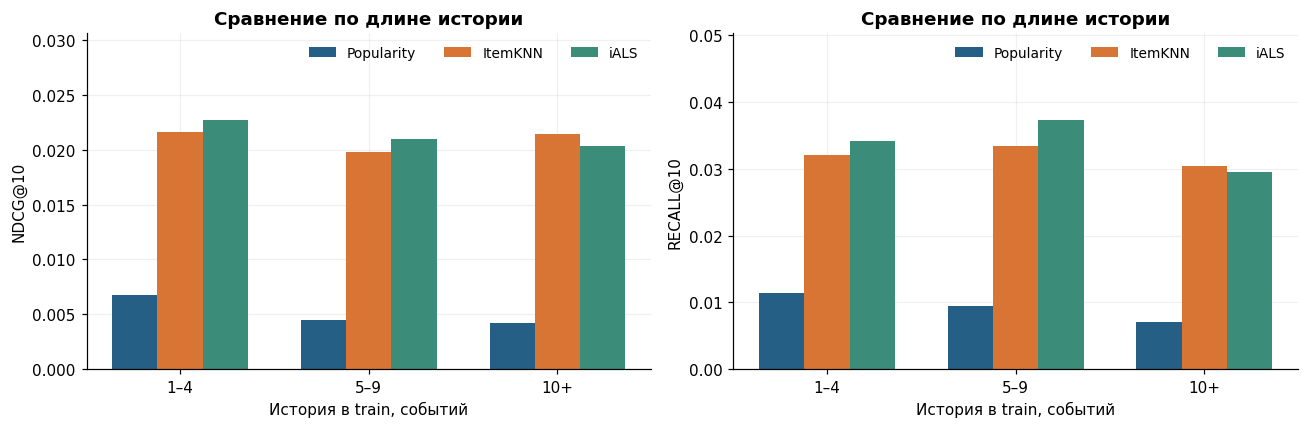

In [31]:
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(ials_runs['history_slices'])
    display(ials_runs['popularity_slices'])
fig,axes=plt.subplots(1,2,figsize=(12,4));positions=np.arange(3);width=.24
for ax,metric in zip(axes,['ndcg','recall']):
    for offset,(name,color) in enumerate(zip(['Popularity','ItemKNN','iALS'],COLORS)):
        values=ials_runs['history_slices'].loc[name][metric].to_numpy()
        ax.bar(positions+(offset-1)*width,values,width,label=name,color=color)
    ax.set_xticks(positions,['1–4','5–9','10+'])
    ax.set(xlabel='История в train, событий',ylabel=metric.upper()+'@10',
        title='Сравнение по длине истории',ylim=(0,ials_runs['history_slices'][metric].max()*1.35))
    ax.legend(frameon=False,ncols=3,fontsize=9)
show_figure('18_ials_history_slices',fig)

### 22. Выводы по iALS

In [32]:
ials_metrics=ials_runs['summary']['best_validation_metrics']
cf_metrics=ials_runs['summary']['cf_validation_metrics']
ndcg_delta=ials_metrics['ndcg_at_10']-cf_metrics['ndcg_at_10']
recall_delta=ials_metrics['recall_at_10']-cf_metrics['recall_at_10']
difference=ials_intervals[(ials_intervals.metric=='ndcg_at_10')&(ials_intervals.estimate_for=='difference')].iloc[0]
verdict='выше, чем' if ndcg_delta>0 else 'ниже, чем' if ndcg_delta<0 else 'такой же, как'
ndcg_interval_text='не включает ноль' if difference.ci_low>0 or difference.ci_high<0 else 'включает ноль'
tail=ials_runs['popularity_slices']
head_ials=tail.loc[('iALS','head_top_10_percent'),'recall_at_10']
head_cf=tail.loc[('ItemKNN','head_top_10_percent'),'recall_at_10']
tail_ials=tail.loc[('iALS','tail_other_90_percent'),'recall_at_10']
tail_cf=tail.loc[('ItemKNN','tail_other_90_percent'),'recall_at_10']
display(Markdown(f'''
- По validation NDCG выбраны **число факторов {ials_best_params['n_factors']}**,
  **alpha {ials_best_params['alpha']:g}**, **lambda {ials_best_params['regularization']:g}**;
  для всех конфигураций было ровно **15 итераций** и seed 42.
- iALS: **NDCG@10 {ials_metrics['ndcg_at_10']:.6f}**, **Recall@10 {ials_metrics['recall_at_10']:.6f}**.
  ItemKNN: **{cf_metrics['ndcg_at_10']:.6f} / {cf_metrics['recall_at_10']:.6f}**.
  NDCG iALS {verdict} у CF; разность NDCG = **{ndcg_delta:+.6f}**,
  разность Recall = **{recall_delta:+.6f}**.
- Парный 95% интервал разности NDCG: **[{difference.ci_low:.6f}; {difference.ci_high:.6f}]**,
  он {ndcg_interval_text}. Это описательный интервал validation после подбора, не независимое test-доказательство.
- Обе модели оценены на **10 207 пользователях** и том же каталоге.
  Fallback iALS — **{ials_metrics['fallback_rate']:.2%}**, CF — **{cf_metrics['fallback_rate']:.2%}**.
  Catalog coverage iALS — **{ials_metrics['catalog_coverage_at_10']:.2%}**,
  CF — **{cf_metrics['catalog_coverage_at_10']:.2%}**; высокая coverage сама по себе не доказывает лучшее качество.
- В срезе популярных товаров Recall iALS **{head_ials:.4f}** против **{head_cf:.4f}** у CF,
  а в хвосте — **{tail_ials:.4f}** против **{tail_cf:.4f}**. Популярность определена только по train;
  пользователи могут присутствовать в обоих срезах. Улучшение общей метрики сопровождается потерей качества в хвосте.
  По длине истории iALS выигрывает по обеим метрикам в группах 1–4 и 5–9, а CF — в группе 10+.
- Потери всех 12 iALS-запусков убывают, но **15 итераций и один seed — ограниченный бюджет**.
  Train objective не заменяет ranking-метрики; выбранные параметры не объявляются оптимальными вне сетки.
  В iALS нет метаданных, а исходные оценки используются только через положительный порог.

Артефакты — `reports/ials_validation/`; индивидуальные метрики, выдачи и факторы только в
`data/validation/ials/`, исключённой из Git. **Test в этом этапе не открывался и не оценивался**;
параметры выбраны только по validation. Финальное сравнение всех пяти моделей — в разделах 40–45.
'''))


- По validation NDCG выбраны **число факторов 64**,
  **alpha 40**, **lambda 0.1**;
  для всех конфигураций было ровно **15 итераций** и seed 42.
- iALS: **NDCG@10 0.021893**, **Recall@10 0.034360**.
  ItemKNN: **0.021111 / 0.032179**.
  NDCG iALS выше, чем у CF; разность NDCG = **+0.000782**,
  разность Recall = **+0.002181**.
- Парный 95% интервал разности NDCG: **[-0.001015; 0.002595]**,
  он включает ноль. Это описательный интервал validation после подбора, не независимое test-доказательство.
- Обе модели оценены на **10 207 пользователях** и том же каталоге.
  Fallback iALS — **5.03%**, CF — **5.14%**.
  Catalog coverage iALS — **14.32%**,
  CF — **73.88%**; высокая coverage сама по себе не доказывает лучшее качество.
- В срезе популярных товаров Recall iALS **0.0817** против **0.0569** у CF,
  а в хвосте — **0.0029** против **0.0142**. Популярность определена только по train;
  пользователи могут присутствовать в обоих срезах. Улучшение общей метрики сопровождается потерей качества в хвосте.
  По длине истории iALS выигрывает по обеим метрикам в группах 1–4 и 5–9, а CF — в группе 10+.
- Потери всех 12 iALS-запусков убывают, но **15 итераций и один seed — ограниченный бюджет**.
  Train objective не заменяет ranking-метрики; выбранные параметры не объявляются оптимальными вне сетки.
  В iALS нет метаданных, а исходные оценки используются только через положительный порог.

Артефакты — `reports/ials_validation/`; индивидуальные метрики, выдачи и факторы только в
`data/validation/ials/`, исключённой из Git. **Test в этом этапе не открывался и не оценивался**;
параметры выбраны только по validation. Финальное сравнение всех пяти моделей — в разделах 40–45.


### 23. Третья модель: EASE с нуля

По [Steck (2019), EASE](https://arxiv.org/abs/1905.03375) обучаем линейное восстановление
бинарной положительной истории $X$ ($rating\ge4$):
$$\min_B \|X-XB\|_F^2+\lambda\|B\|_F^2,\quad \mathrm{diag}(B)=0.$$
$$P=(X^\top X+\lambda I)^{-1},\qquad B_{ij}=-P_{ij}/P_{jj}\;(i\ne j),\quad B_{jj}=0.$$
Столбец $j$ содержит веса исходных товаров для предсказания целевого товара $j$; $scores=XB$.

В `models/ease.py` матрица строится через точное разложение Холецкого и SPD-инверсию LAPACK.
Это линейная алгебра SciPy, все шаги EASE реализованы самостоятельно. Полная матрица float64
переиспользует один буфер; нет top-k усечения весов, ограничения ранга или отсечения отрицательных весов.
Нули $X$ участвуют в квадратичной функции потерь. Это иной objective, чем confidence-weighted iALS.
Оценки 1–3 дают нулевой вход, но все ранее оценённые товары маскируются общим оценщиком.

### 24. Подбор регуляризации: заранее фиксированный план

В `configs/ease_search.json` до первого обучения зафиксированы
$\lambda\in\{1,10,30,100,300,1000,10000\}$: семь запусков без расширения сетки.
Потери суммируются, а не усредняются по пользователям. Выбор — максимум validation macro NDCG@10;
при точном равенстве выбирается большее $\lambda$. Для точного EASE случайная инициализация не нужна.

Каждый запуск обучается только на train. Каталог, пользователи, время запроса, релевантность,
маскирование и popularity fallback совпадают с CF/iALS. Профиль без ненулевых оценок кандидатов
передаётся общему fallback; конечные отрицательные оценки допустимы.

Эта секция воспроизводится отдельно: `python scripts/execute_notebook.py --section ease`.
Режим запускает новое ядро, сохраняет старые EDA/CF/iALS-выводы и блокирует открытие test/полной истории.
Счётчики новых ячеек относятся к новому ядру. Для повторного HPO отключите кеш ниже;
он принимается только после проверки контрольных сумм входов, кода, когорты и артефактов.

In [33]:
ease_config=json.loads((ROOT/'configs/ease_search.json').read_text())
display(pd.Series(ease_config,name='Зафиксированный план EASE').to_frame())


,Зафиксированный план EASE
model,EASE
preference,X_ui=1 for fit rating >=4; otherwise 0
objective,"||X-XB||_F^2 + lambda*||B||_F^2, diag(B)=0; un..."
grid,"{'regularization': [1.0, 10.0, 30.0, 100.0, 30..."
budget,7
selection,maximum validation macro NDCG@10
tie_break,larger regularization
dtype,float64
approximation,"none; full dense signed matrix, no pruning or ..."
test_evaluated,False


In [34]:
ease_runs=load_validation_report(ROOT,'ease')
assert ease_runs['summary']['completed_trials']==7
assert ease_runs['summary']['test_evaluated'] is False
assert ease_runs['summary']['cohort']['evaluation_users']==10207
ease_search=ease_runs['search'].sort_values(['ndcg_at_10','regularization'],ascending=[False,False]).reset_index(drop=True)
with pd.option_context('display.float_format',lambda x:f'{x:.6f}','display.max_columns',None):
    display(ease_search)

,trial,regularization,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds,catalog_items,weight_bytes,nonzero_weights,negative_weights,negative_fraction_of_nonzero,training_objective
0,4,100.000000,0.023372,0.035191,0.497689,0.051435,10207,1.705730,18.140118,15578,1941392672,237853506,110083966,0.462823,233191.091650
1,3,30.000000,0.023062,0.034908,0.543459,0.051435,10207,1.702111,18.837018,15578,1941392672,237853506,107121728,0.450369,213684.486866
2,5,300.000000,0.022912,0.034628,0.483053,0.051435,10207,1.719215,18.008492,15578,1941392672,237853506,117224714,0.492844,245498.519901
3,6,1000.000000,0.022120,0.033417,0.484337,0.051435,10207,1.929608,20.436331,15578,1941392672,237853506,128126828,0.538680,253289.466983
4,2,10.000000,0.021882,0.033175,0.627038,0.051435,10207,1.821197,18.845576,15578,1941392672,237853506,108675360,0.456900,192498.358573
5,7,10000.000000,0.021387,0.032597,0.489986,0.051435,10207,1.810961,21.505512,15578,1941392672,237853506,136419468,0.573544,258313.707809
6,1,1.000000,0.017876,0.026578,0.738927,0.051435,10207,1.770697,16.536922,15578,1941392672,237853506,115429176,0.485295,153506.762549


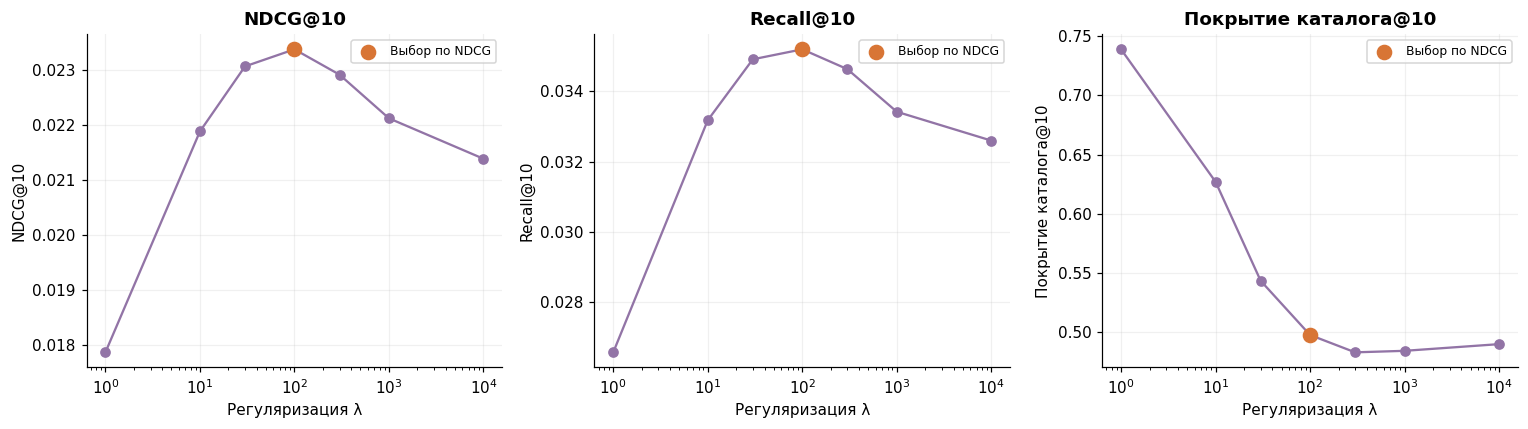

In [35]:
ease_grid=ease_search.sort_values('regularization')
ease_lambda=ease_runs['summary']['best_params']['regularization']
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10','catalog_coverage_at_10'],['NDCG@10','Recall@10','Покрытие каталога@10']):
    ax.plot(ease_grid.regularization,ease_grid[metric],marker='o',color=COLORS[3])
    best=ease_grid[ease_grid.regularization==ease_lambda].iloc[0]
    ax.scatter([ease_lambda],[best[metric]],s=85,color=COLORS[1],zorder=4,label='Выбор по NDCG')
    ax.set_xscale('log');ax.set_xlabel('Регуляризация λ');ax.set_ylabel(label)
    ax.set_title(label);ax.legend(fontsize=8)
show_figure('19_ease_regularization',fig)

### 25. Диагностика и цена плотной матрицы

EASE хранит $|I|^2$ весов: память $O(|I|^2)$, факторизация и инверсия — $O(|I|^3)$.
Показываем фактический размер весов, долю отрицательных коэффициентов и точную train objective
при оптимуме: $\sum_j 1/P_{jj}-\lambda|I|$. Маленькие тесты независимо проверяют эту формулу
и каждый столбец весов через ridge-регрессию без целевого товара во входе.

Отрицательные веса отражают условные связи и не означают ошибку. Диагональ строго нулевая.
Выбранная матрица хранится локально в `data/validation/ease/`, исключённой из Git;
в notebook нет распечатки отдельных пользовательских профилей или плотных весов.

In [36]:
ease_diagnostics=ease_runs['summary']['best_model_diagnostics']
display(pd.Series(ease_diagnostics,name='Диагностика выбранного EASE').to_frame())
print(f"Матрица весов: {ease_diagnostics['weight_bytes']/2**30:.3f} GiB; float64")

,Диагностика выбранного EASE
catalog_items,"15,578.000"
negative_fraction_of_nonzero,0.463
negative_weights,"110,083,966.000"
nonzero_weights,"237,853,506.000"
training_objective,"233,191.092"
weight_bytes,"1,941,392,672.000"


Матрица весов: 1.808 GiB; float64


### 26. Сравнение EASE, CF и iALS на validation

CF и iALS используют ранее выбранные параметры и сохранённые выдачи; повторного подбора этих
моделей нет. Совпадение когорты и исходных файлов проверяется до обучения EASE.
Времена CF/iALS взяты из предыдущих запусков; это ориентир, а не изолированный benchmark.

Парные bootstrap-интервалы (2 000 перевыборок пользователей, seed 42, 95%) считаются отдельно
для разницы EASE–CF и EASE–iALS на одной когорте. Они описательные: validation уже использован
для HPO; поправка за множественные сравнения не применяется. До финального test утверждения
об общем превосходстве моделей не делаем.

,model,catalog_coverage_at_10,evaluation_seconds,fallback_rate,ndcg_at_10,recall_at_10,users,fit_seconds
0,Popularity,0.000963,1.224501,0.000000,0.005779,0.010252,10207,0.000000
1,ItemKNN,0.738798,1.277437,0.051435,0.021111,0.032179,10207,0.337878
2,iALS,0.143215,1.582736,0.050260,0.021893,0.034360,10207,44.419219
3,EASE,0.497689,1.705730,0.051435,0.023372,0.035191,10207,18.140118


,baseline,metric,estimate_for,estimate,ci_low,ci_high
0,ItemKNN,ndcg_at_10,EASE,0.023372,0.021480,0.025366
1,ItemKNN,ndcg_at_10,ItemKNN,0.021111,0.019287,0.023026
2,ItemKNN,ndcg_at_10,difference,0.002260,0.001279,0.003287
3,ItemKNN,recall_at_10,EASE,0.035191,0.032197,0.038147
4,ItemKNN,recall_at_10,ItemKNN,0.032179,0.029379,0.035092
5,ItemKNN,recall_at_10,difference,0.003012,0.001157,0.004870
6,iALS,ndcg_at_10,EASE,0.023372,0.021480,0.025366
7,iALS,ndcg_at_10,iALS,0.021893,0.020066,0.023882
8,iALS,ndcg_at_10,difference,0.001478,-0.000202,0.003204
9,iALS,recall_at_10,EASE,0.035191,0.032197,0.038147


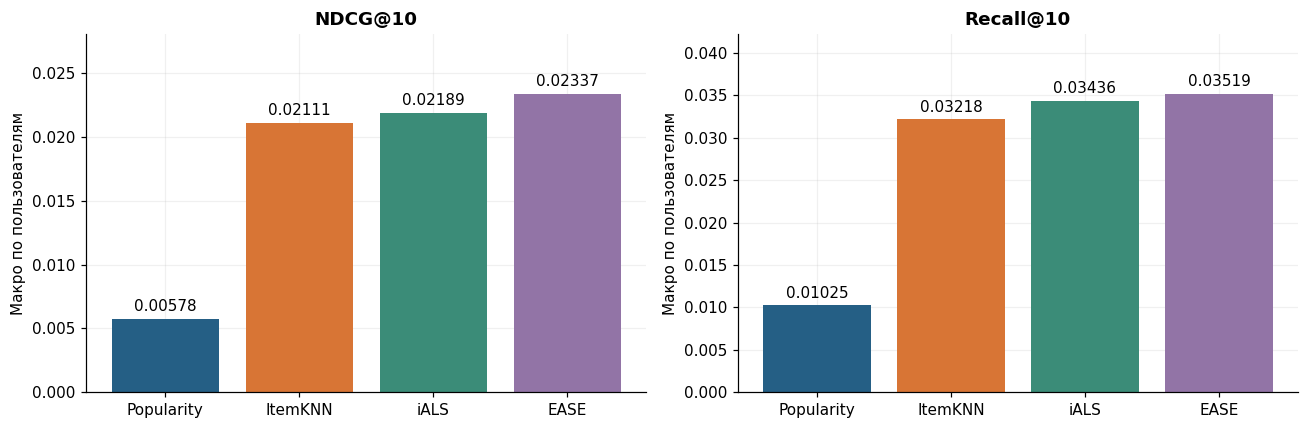

In [37]:
ease_comparison=ease_runs['comparison']
ease_intervals=ease_runs['intervals']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(ease_comparison)
    display(ease_intervals)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10'],['NDCG@10','Recall@10']):
    ax.bar(ease_comparison.model,ease_comparison[metric],color=COLORS[:4])
    for i,value in enumerate(ease_comparison[metric]):
        ax.annotate(f'{value:.5f}',(i,value),xytext=(0,5),textcoords='offset points',ha='center')
    ax.set_ylim(0,ease_comparison[metric].max()*1.2);ax.set_title(label)
    ax.set_ylabel('Макро по пользователям')
show_figure('20_ease_vs_cf_ials',fig)

users     ndcg   recall  fallback_rate
model      history_slice                                        
Popularity 1-4             5943 0.006765 0.011434       0.000000
           5-9             2766 0.004511 0.009421       0.000000
           10+             1498 0.004205 0.007094       0.000000
ItemKNN    1-4             5943 0.021634 0.032072       0.086152
           5-9             2766 0.019806 0.033355       0.004700
           10+             1498 0.021447 0.030435       0.000000
iALS       1-4             5943 0.022691 0.034203       0.084133
           5-9             2766 0.021001 0.037281       0.004700
           10+             1498 0.020377 0.029589       0.000000
EASE       1-4             5943 0.023352 0.034353       0.086152
           5-9             2766 0.023400 0.039595       0.004700
           10+             1498 0.023397 0.030388       0.000000

users  relevant_interactions  recall_at_10
model      item_slice                                                       
Popularity head_top_10_percent     5704                  10248      0.024125
           tail_other_90_percent   7765                  15398      0.000000
ItemKNN    head_top_10_percent     5704                  10248      0.056922
           tail_other_90_percent   7765                  15398      0.014238
iALS       head_top_10_percent     5704                  10248      0.081696
           tail_other_90_percent   7765                  15398      0.002851
EASE       head_top_10_percent     5704                  10248      0.068608
           tail_other_90_percent   7765                  15398      0.011670

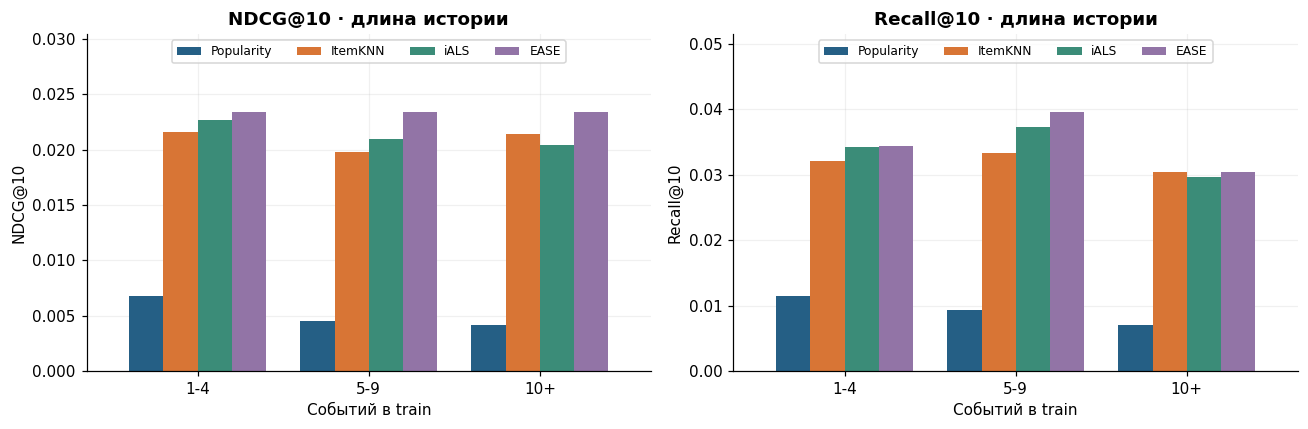

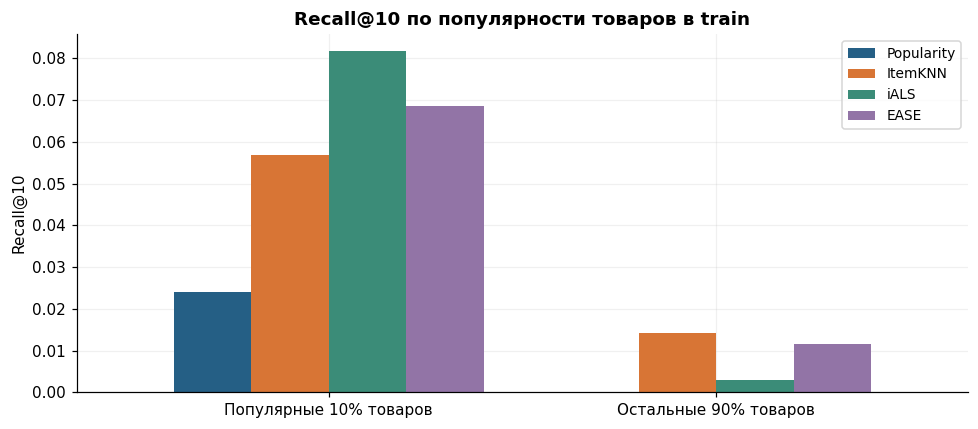

In [38]:
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(ease_runs['history_slices'])
    display(ease_runs['popularity_slices'])
fig,axes=plt.subplots(1,2,figsize=(12,4))
history_order=['1-4','5-9','10+']
for ax,metric,label in zip(axes,['ndcg','recall'],['NDCG@10','Recall@10']):
    table=ease_runs['history_slices'][metric].unstack('model').reindex(history_order)[ease_comparison.model]
    table.plot.bar(ax=ax,color=COLORS[:4],rot=0,width=.8)
    ax.set_title(label+' · длина истории');ax.set_xlabel('Событий в train');ax.set_ylabel(label)
    ax.set_ylim(0,table.to_numpy().max()*1.3)
    ax.legend(fontsize=8,ncol=4,loc='upper center')
show_figure('21_ease_history_slices',fig)
fig,ax=plt.subplots(figsize=(9,4))
item_order=['head_top_10_percent','tail_other_90_percent']
table=ease_runs['popularity_slices'].recall_at_10.unstack('model').reindex(item_order)[ease_comparison.model]
table.index=['Популярные 10% товаров','Остальные 90% товаров']
table.plot.bar(ax=ax,color=COLORS[:4],rot=0,width=.8)
ax.set_title('Recall@10 по популярности товаров в train');ax.set_xlabel('');ax.set_ylabel('Recall@10')
ax.legend(fontsize=9)
show_figure('22_ease_popularity_slices',fig)

### 27. Выводы по EASE

In [39]:
ease_m=ease_runs['summary']['best_validation_metrics']
rows=[]
for name in ['ItemKNN','iALS']:
    baseline=ease_runs['summary']['baseline_validation_metrics'][name]
    for metric in ['ndcg_at_10','recall_at_10']:
        interval=ease_intervals[(ease_intervals.baseline==name)&(ease_intervals.metric==metric)&(ease_intervals.estimate_for=='difference')].iloc[0]
        delta=ease_m[metric]-baseline[metric]
        zero='включает ноль' if interval.ci_low<=0<=interval.ci_high else 'не включает ноль'
        rows.append(f"- EASE − {name}, {metric}: {delta:+.6f} ({delta/baseline[metric]:+.2%}); 95% интервал [{interval.ci_low:.6f}; {interval.ci_high:.6f}], {zero}.")
ease_slice=ease_runs['popularity_slices']
head=ease_slice.loc[('EASE','head_top_10_percent'),'recall_at_10']
tail=ease_slice.loc[('EASE','tail_other_90_percent'),'recall_at_10']
boundary=ease_lambda in [min(ease_config['grid']['regularization']),max(ease_config['grid']['regularization'])]
display(Markdown(f"""
По validation NDCG выбрано **λ={ease_lambda:g}** из заранее фиксированной сетки.
**NDCG@10={ease_m['ndcg_at_10']:.6f}, Recall@10={ease_m['recall_at_10']:.6f}**.
Выбрана {'граница' if boundary else 'внутренняя точка'} сетки; оптимальность вне проверенных значений не установлена.

"""+'\n'.join(rows)+f"""

Оценены те же **{fmt(ease_m['users'])} пользователей**; покрытие каталога EASE — **{ease_m['catalog_coverage_at_10']:.2%}**,
fallback — **{ease_m['fallback_rate']:.2%}**.
Recall популярных товаров: EASE **{head:.6f}**, CF **{ease_slice.loc[('ItemKNN','head_top_10_percent'),'recall_at_10']:.6f}**,
iALS **{ease_slice.loc[('iALS','head_top_10_percent'),'recall_at_10']:.6f}**.
Recall хвоста: EASE **{tail:.6f}**, CF **{ease_slice.loc[('ItemKNN','tail_other_90_percent'),'recall_at_10']:.6f}**,
iALS **{ease_slice.loc[('iALS','tail_other_90_percent'),'recall_at_10']:.6f}**;
популярность рассчитана только по train, пользователь может участвовать в обоих срезах.
Срезы показывают, какие группы формируют общий результат, и не заменяют основную метрику.

Плотная матрица весов занимает **{ease_diagnostics['weight_bytes']/2**30:.3f} GiB**;
отрицательны **{ease_diagnostics['negative_fraction_of_nonzero']:.2%}** ненулевых коэффициентов.
У EASE нет метаданных и временных признаков, только бинарная положительная история.
Описательные интервалы после HPO не служат независимым доказательством превосходства.

Выполнено семь запусков; агрегаты сохранены в `reports/ease_validation/`, веса и выдачи — локально в `data/validation/ease/`.
**Test на этом этапе не открывался и не оценивался. Переобучения на train+validation не было.**
Завершённое сравнение всех пяти моделей на test — в разделах 40–45.
"""))


По validation NDCG выбрано **λ=100** из заранее фиксированной сетки.
**NDCG@10=0.023372, Recall@10=0.035191**.
Выбрана внутренняя точка сетки; оптимальность вне проверенных значений не установлена.

- EASE − ItemKNN, ndcg_at_10: +0.002260 (+10.71%); 95% интервал [0.001279; 0.003287], не включает ноль.
- EASE − ItemKNN, recall_at_10: +0.003012 (+9.36%); 95% интервал [0.001157; 0.004870], не включает ноль.
- EASE − iALS, ndcg_at_10: +0.001478 (+6.75%); 95% интервал [-0.000202; 0.003204], включает ноль.
- EASE − iALS, recall_at_10: +0.000831 (+2.42%); 95% интервал [-0.001923; 0.003507], включает ноль.

Оценены те же **10 207 пользователей**; покрытие каталога EASE — **49.77%**,
fallback — **5.14%**.
Recall популярных товаров: EASE **0.068608**, CF **0.056922**,
iALS **0.081696**.
Recall хвоста: EASE **0.011670**, CF **0.014238**,
iALS **0.002851**;
популярность рассчитана только по train, пользователь может участвовать в обоих срезах.
Срезы показывают, какие группы формируют общий результат, и не заменяют основную метрику.

Плотная матрица весов занимает **1.808 GiB**;
отрицательны **46.28%** ненулевых коэффициентов.
У EASE нет метаданных и временных признаков, только бинарная положительная история.
Описательные интервалы после HPO не служат независимым доказательством превосходства.

Выполнено семь запусков; агрегаты сохранены в `reports/ease_validation/`, веса и выдачи — локально в `data/validation/ease/`.
**Test на этом этапе не открывался и не оценивался. Переобучения на train+validation не было.**
Завершённое сравнение всех пяти моделей на test — в разделах 40–45.


### 28. Четвёртая модель: Factorization Machine с нуля

[FM второго порядка, Rendle (2010)](https://doi.org/10.1109/ICDM.2010.127):
$$s(x)=w_0+\sum_jw_jx_j+\frac12\sum_f\left[(\sum_jv_{jf}x_j)^2-\sum_jv_{jf}^2x_j^2\right].$$
Все пары активных признаков участвуют во взаимодействиях, включая item–brand, item–category
и category–category. Реализация `models/fm.py` использует NumPy: формула FM, градиенты и AdaGrad написаны вручную.
В тестах формула сравнивается с явным перебором пар, градиенты — с конечными разностями.

Для item-признаков заранее считаются сумма embedding-векторов $q_i$ и внутренний FM-score $a_i$.
Тогда точный полный score равен $w_0+w_u+a_i+\langle v_u,q_i\rangle$.
Это ускоряет ранжирование всего fit-каталога без приближений и без пересчёта пар отдельно для каждой пары user–item.

### 29. Метаданные и защита от утечки

Признаки: one-hot user ID, item ID, brand и multi-hot категории. Нормализуем регистр и пробелы;
категории каждого товара уникальны и имеют веса $1/\sqrt{m}$, чтобы суммарная L2-норма блока была 1.
Общую категорию Video Games исключаем. Словари брендов/категорий строятся **только по товарам train-каталога**,
токены с менее чем пятью товарами заменяются/сводятся в UNK; у категорий UNK используется при отсутствии
сохранённых категорий. User/item ID из validation в словари не добавляются.

Используются бренд и категории, без отзывов, цены, sales rank, связанных товаров или признаков из будущих событий.
В источнике метаданные — **crawl-time snapshot**, исторических версий нет. Их доступность на дату запроса
остаётся допущением; фильтр по train-каталогу не превращает этот снимок в историческую базу.

In [40]:
fm_config=json.loads((ROOT/'configs/fm_search.json').read_text())
display(pd.Series(fm_config,name='Зафиксированный план FM').to_frame())


,Зафиксированный план FM
model,FM
grid,"{'n_factors': [16, 32], 'learning_rate': [0.05..."
budget,8
n_epochs,12
batch_size,1024
seed,42
shuffle_seed,43
negative_sampling_seed,137
negatives_per_positive,2
minimum_items_per_metadata_token,5


### 30. Обучающие примеры и фиксированный подбор

Из train: оценки 4–5 дают $y=1$, оценки 1–3 — $y=0$. На каждое положительное событие добавляем
две равномерно выбранные ненаблюдавшиеся пары пользователя с товарами train-каталога.
Выборка с возвращением исключает **все наблюдавшиеся train-пары**, в том числе оценки 1–3;
будущие пары при этом не проверяются. Ненаблюдавшееся — условный отрицательный пример, а не подтверждённая неприязнь.
Выборка фиксируется (seed 137), одинакова между конфигурациями и эпохами. Вероятности модели не интерпретируем
как калиброванные вероятности покупки из-за такого семплирования.

Оптимизируем среднюю BCE и регуляризацию
$$L=\frac1N\sum_t[\log(1+e^{s_t})-y_ts_t]
 +\frac{\lambda}{2N}\sum_t\sum_j x_{tj}^2(w_j^2+\|v_j\|^2).$$
Регуляризация взвешена частотой и квадратами значений активных признаков; это **не uniform global ridge**.
Bias не регуляризуется. AdaGrad суммирует градиенты повторяющихся feature ID в батче до обновления аккумуляторов.

До первого обучения зафиксированы $f\in\{16,32\}$, learning rate $\in\{0.05,0.15\}$,
$\lambda\in\{10^{-5},10^{-3}\}$: 8 запусков по 12 эпох, batch=1024, init seed=42, shuffle seed=43.
Выбор — NDCG@10 на validation после последней эпохи; ties: меньше факторов, меньше LR, больше регуляризация.
Early stopping и расширения сетки нет. Дополнительный ID-only запуск — диагностическая ablation при выбранных
настройках, в HPO не участвует и отдельно не настраивается.

In [41]:
fm_runs=load_validation_report(ROOT,'fm')
assert fm_runs['summary']['completed_trials']==8
assert fm_runs['summary']['diagnostic_ablation_runs']==1
assert fm_runs['summary']['test_evaluated'] is False
assert fm_runs['summary']['cohort']['evaluation_users']==10207
fm_search=fm_runs['search'].sort_values(['ndcg_at_10','n_factors','learning_rate','regularization'],ascending=[False,True,True,False]).reset_index(drop=True)
fm_best_params=fm_runs['summary']['best_params']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}','display.max_columns',None):
    display(fm_search)

,trial,n_factors,learning_rate,regularization,n_epochs,batch_size,seed,shuffle_seed,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds,initial_probe_bce,final_probe_bce
0,6,32,0.050000,0.001000,12,1024,42,43,0.008494,0.014402,0.092952,0.000000,10207,1.492422,30.281805,0.614899,0.137884
1,5,32,0.050000,0.000010,12,1024,42,43,0.008426,0.014180,0.095134,0.000000,10207,1.736504,30.387320,0.614899,0.131295
2,4,16,0.150000,0.001000,12,1024,42,43,0.007877,0.012996,0.123315,0.000000,10207,1.558421,18.301583,0.614886,0.064640
3,3,16,0.150000,0.000010,12,1024,42,43,0.007735,0.013088,0.120683,0.000000,10207,1.587146,17.549084,0.614886,0.060837
4,7,32,0.150000,0.000010,12,1024,42,43,0.007671,0.012166,0.133393,0.000000,10207,1.626336,30.331149,0.614899,0.014198
5,8,32,0.150000,0.001000,12,1024,42,43,0.007442,0.012162,0.135062,0.000000,10207,1.588005,30.430172,0.614899,0.017140
6,2,16,0.050000,0.001000,12,1024,42,43,0.007298,0.012524,0.056362,0.000000,10207,1.509335,17.933308,0.614886,0.212362
7,1,16,0.050000,0.000010,12,1024,42,43,0.006845,0.011597,0.058608,0.000000,10207,1.526691,17.682329,0.614886,0.206991


In [42]:
fm_feature_stats=fm_runs['summary']['feature_diagnostics']
fm_training_stats=fm_runs['summary']['training_examples']
display(pd.Series(fm_feature_stats,name='Fit-only признаки').to_frame())
display(pd.Series(fm_training_stats,name='Обучающие примеры').to_frame())

,Fit-only признаки
brand_vocabulary,280
category_l2_normalization,True
category_vocabulary,78
features,59402
fit_items_with_brand,15474
fit_items_with_category,15447
item_id_features,15578
max_active_item_features,7
metadata_assumption,crawl-time static snapshot; historical availab...
minimum_catalog_items_per_token,5


,Обучающие примеры
examples,849123
fingerprint,f8a61dd491d22f49683e61e2a63bda288856a3b485758c...
negative_sampling_seed,137
negatives_per_positive,2
observed_negative,71865
observed_positive,259086
sampled_unobserved,518172
sampling,"uniform with replacement, excluding ALL observ..."


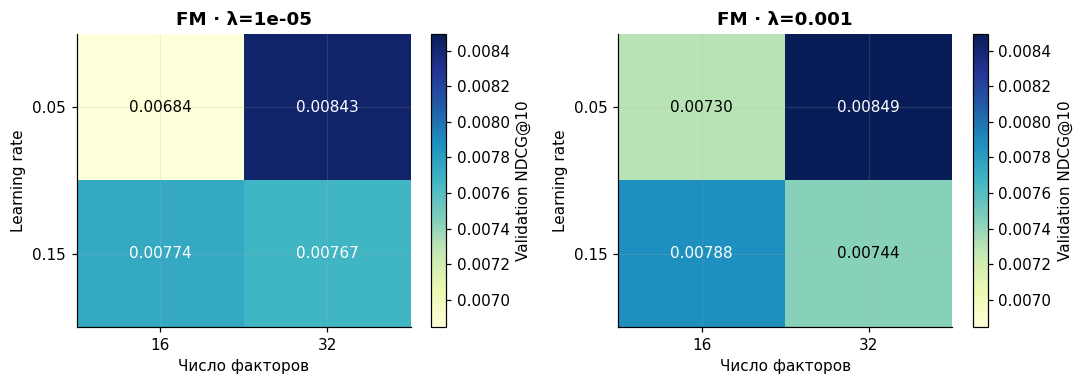

In [43]:
fig,axes=plt.subplots(1,2,figsize=(10,3.6))
lo=fm_search.ndcg_at_10.min();hi=fm_search.ndcg_at_10.max()
for ax,reg in zip(axes,fm_config['grid']['regularization']):
    table=fm_search[fm_search.regularization==reg].pivot(index='learning_rate',columns='n_factors',values='ndcg_at_10').sort_index()
    im=ax.imshow(table.values,cmap='YlGnBu',vmin=lo,vmax=hi,aspect='auto')
    ax.set_xticks(range(len(table.columns)),table.columns);ax.set_yticks(range(len(table.index)),table.index)
    ax.set_xlabel('Число факторов');ax.set_ylabel('Learning rate');ax.set_title(f'FM · λ={reg:g}')
    for i in range(len(table.index)):
        for j in range(len(table.columns)):
            value=table.iloc[i,j]
            ax.text(j,i,f'{value:.5f}',ha='center',va='center',color='white' if value>(lo+hi)/2 else 'black')
    fig.colorbar(im,ax=ax,label='Validation NDCG@10')
show_figure('23_fm_hyperparameters',fig)

### 31. Диагностика оптимизации

BCE и регуляризованный objective ниже считаются после каждой эпохи на одной фиксированной
train-подвыборке из 8 192 примеров (seed 991); это не полная train loss и не validation.
`online_objective` в CSV — среднее значение на батчах до последовательных обновлений.
У стохастического AdaGrad монотонное убывание не гарантировано. Эти кривые не использовались для выбора эпохи.
Ranking-качество выбираем через общий оценщик, а не через минимальную BCE.

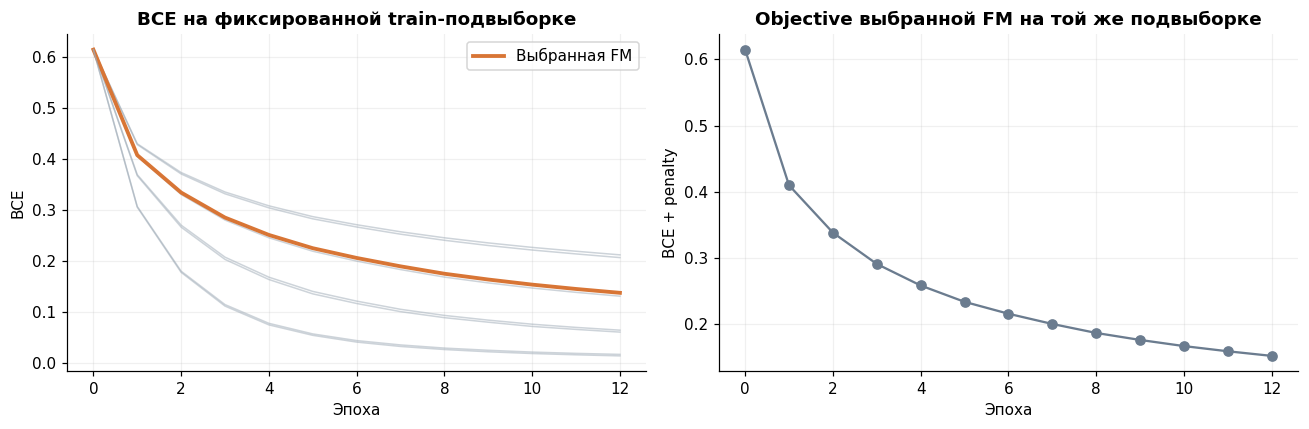

In [44]:
fm_curves=fm_runs['curve'];fm_best_trial=int(fm_search.iloc[0].trial)
assert all(len(g)==13 and g.epoch.tolist()==list(range(13)) for _,g in fm_curves.groupby('trial'))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for trial,g in fm_curves.groupby('trial'):
    winner=trial==fm_best_trial
    axes[0].plot(g.epoch,g.probe_bce,color=COLORS[1] if winner else '#9CA9B5',alpha=1 if winner else .5,lw=2.5 if winner else 1,label='Выбранная FM' if winner else None)
best_curve=fm_curves[fm_curves.trial==fm_best_trial]
axes[1].plot(best_curve.epoch,best_curve.probe_objective,marker='o',color=COLORS[4])
axes[0].set_title('BCE на фиксированной train-подвыборке');axes[0].set_ylabel('BCE');axes[0].legend()
axes[1].set_title('Objective выбранной FM на той же подвыборке');axes[1].set_ylabel('BCE + penalty')
for ax in axes:ax.set_xlabel('Эпоха')
show_figure('24_fm_training',fig)

### 32. Сравнение четырёх моделей и вклад метаданных

Сохраняем тот же full-catalog протокол: 10 207 пользователей, те же релевантные товары,
маска всей fit-истории, top-10 и ties. Общий fallback не менялся. FM использует также
отрицательные наблюдавшиеся оценки, поэтому пользователь без положительной истории может иметь
обученный профиль и конечные scores; таких пользователей не исключаем и принудительно не заменяем popularity.

CF/iALS/EASE переиспользуют зафиксированные результаты. Времена этих моделей — из прежних запусков;
построение словарей и генерация примеров не включены во время обучения FM.
Парный bootstrap: 2 000 перевыборок пользователей, seed 42, 95%; интервалы после HPO описательные,
без поправки за множественные сравнения. ID-only ablation при тех же настройках не доказывает причинный эффект
метаданных и не заменяет отдельного подбора лучшей ID-only модели.

,model,catalog_coverage_at_10,evaluation_seconds,fallback_rate,ndcg_at_10,recall_at_10,users,fit_seconds
0,Popularity,0.000963,1.224501,0.000000,0.005779,0.010252,10207,0.000000
1,ItemKNN,0.738798,1.277437,0.051435,0.021111,0.032179,10207,0.337878
2,iALS,0.143215,1.582736,0.050260,0.021893,0.034360,10207,44.419219
3,EASE,0.497689,1.705730,0.051435,0.023372,0.035191,10207,18.140118
4,FM,0.092952,1.492422,0.000000,0.008494,0.014402,10207,30.281805


,baseline,metric,estimate_for,estimate,ci_low,ci_high
0,ItemKNN,ndcg_at_10,FM,0.008494,0.007457,0.009561
1,ItemKNN,ndcg_at_10,ItemKNN,0.021111,0.019287,0.023026
2,ItemKNN,ndcg_at_10,difference,-0.012618,-0.014672,-0.010615
3,ItemKNN,recall_at_10,FM,0.014402,0.012591,0.016266
4,ItemKNN,recall_at_10,ItemKNN,0.032179,0.029379,0.035092
5,ItemKNN,recall_at_10,difference,-0.017777,-0.021139,-0.014569
6,iALS,ndcg_at_10,FM,0.008494,0.007457,0.009561
7,iALS,ndcg_at_10,iALS,0.021893,0.020066,0.023882
8,iALS,ndcg_at_10,difference,-0.013400,-0.015560,-0.011350
9,iALS,recall_at_10,FM,0.014402,0.012591,0.016266


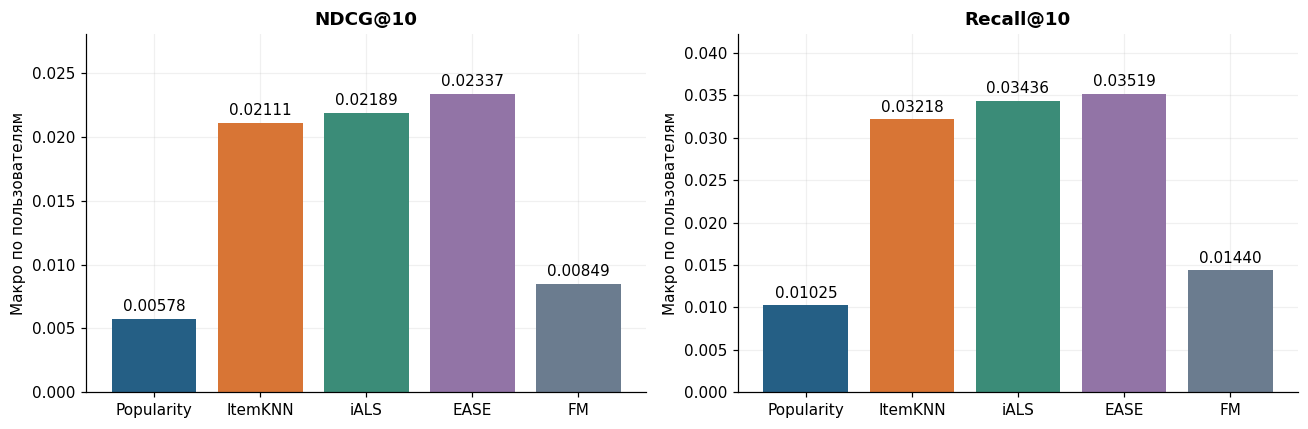

In [45]:
fm_comparison=fm_runs['comparison'];fm_intervals=fm_runs['intervals']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(fm_comparison)
    display(fm_intervals)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10'],['NDCG@10','Recall@10']):
    ax.bar(fm_comparison.model,fm_comparison[metric],color=COLORS)
    for i,value in enumerate(fm_comparison[metric]):ax.annotate(f'{value:.5f}',(i,value),xytext=(0,5),textcoords='offset points',ha='center')
    ax.set_ylim(0,fm_comparison[metric].max()*1.2);ax.set_title(label);ax.set_ylabel('Макро по пользователям')
show_figure('25_fm_comparison',fig)

,features,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds
0,IDs + brand + categories,0.008494,0.014402,0.092952,0.000000,10207,1.492422,30.281805
1,IDs only (diagnostic),0.005990,0.010861,0.152715,0.000000,10207,1.586687,11.640096


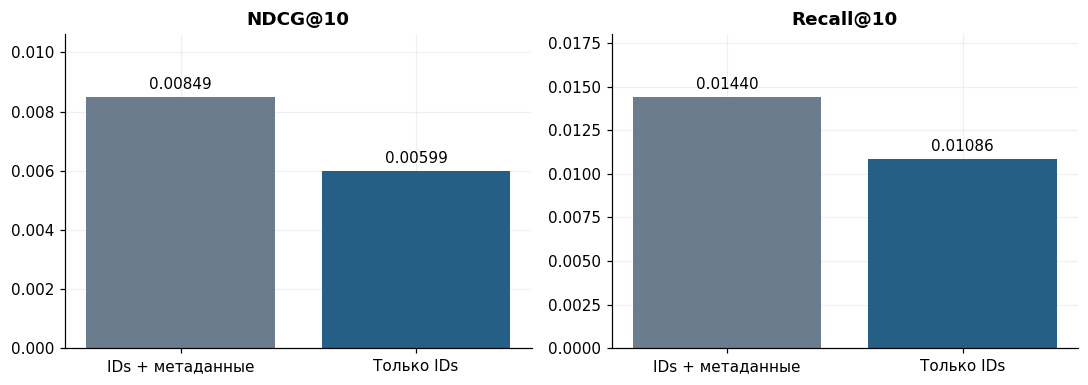

In [46]:
fm_ablation=fm_runs['ablation']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):display(fm_ablation)
fig,axes=plt.subplots(1,2,figsize=(10,3.6))
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10'],['NDCG@10','Recall@10']):
    ax.bar(['IDs + метаданные','Только IDs'],fm_ablation[metric],color=[COLORS[4],COLORS[0]])
    for i,value in enumerate(fm_ablation[metric]):ax.annotate(f'{value:.5f}',(i,value),xytext=(0,5),textcoords='offset points',ha='center')
    ax.set_ylim(0,fm_ablation[metric].max()*1.25);ax.set_title(label)
show_figure('26_fm_metadata_ablation',fig)

users     ndcg   recall  fallback_rate
model      history_slice                                        
Popularity 1-4             5943 0.006765 0.011434       0.000000
           5-9             2766 0.004511 0.009421       0.000000
           10+             1498 0.004205 0.007094       0.000000
ItemKNN    1-4             5943 0.021634 0.032072       0.086152
           5-9             2766 0.019806 0.033355       0.004700
           10+             1498 0.021447 0.030435       0.000000
iALS       1-4             5943 0.022691 0.034203       0.084133
           5-9             2766 0.021001 0.037281       0.004700
           10+             1498 0.020377 0.029589       0.000000
EASE       1-4             5943 0.023352 0.034353       0.086152
           5-9             2766 0.023400 0.039595       0.004700
           10+             1498 0.023397 0.030388       0.000000
FM         1-4             5943 0.008747 0.014267       0.000000
           5-9             2766 0.008854 0.016658       0.000000
           10+             1498 0.006821 0.010773       0.000000

users  relevant_interactions  recall_at_10
model      item_slice                                                       
Popularity head_top_10_percent     5704                  10248      0.024125
           tail_other_90_percent   7765                  15398      0.000000
ItemKNN    head_top_10_percent     5704                  10248      0.056922
           tail_other_90_percent   7765                  15398      0.014238
iALS       head_top_10_percent     5704                  10248      0.081696
           tail_other_90_percent   7765                  15398      0.002851
EASE       head_top_10_percent     5704                  10248      0.068608
           tail_other_90_percent   7765                  15398      0.011670
FM         head_top_10_percent     5704                  10248      0.036202
           tail_other_90_percent   7765                  15398      0.000303

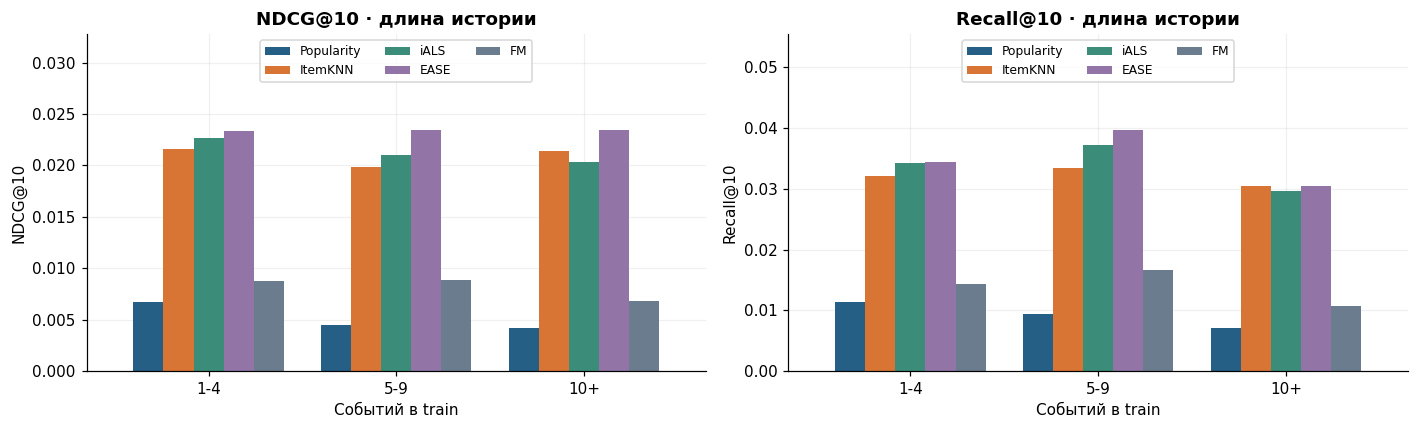

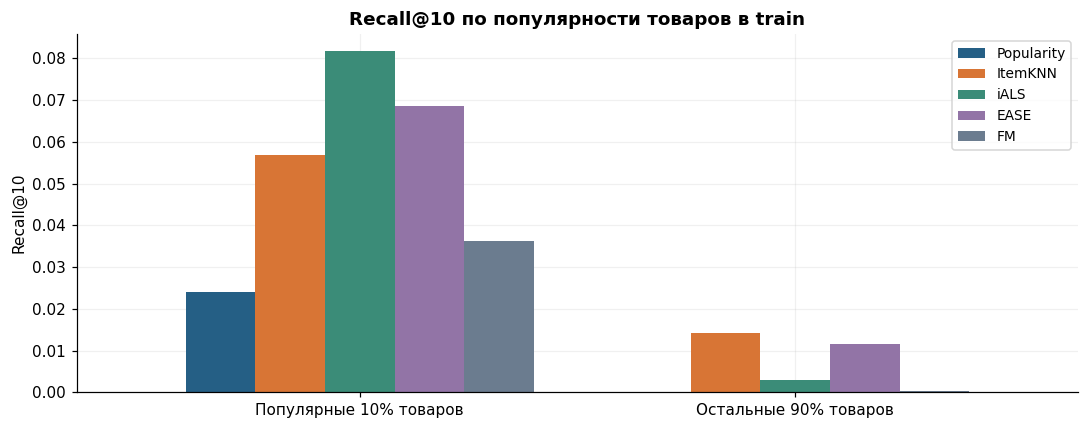

In [47]:
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(fm_runs['history_slices']);display(fm_runs['popularity_slices'])
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,metric,label in zip(axes,['ndcg','recall'],['NDCG@10','Recall@10']):
    table=fm_runs['history_slices'][metric].unstack('model').reindex(['1-4','5-9','10+'])[fm_comparison.model]
    table.plot.bar(ax=ax,color=COLORS,rot=0,width=.8)
    ax.set_ylim(0,table.to_numpy().max()*1.4);ax.legend(fontsize=8,ncol=3,loc='upper center')
    ax.set_title(label+' · длина истории');ax.set_ylabel(label);ax.set_xlabel('Событий в train')
show_figure('27_fm_history_slices',fig)
fig,ax=plt.subplots(figsize=(10,4))
table=fm_runs['popularity_slices'].recall_at_10.unstack('model').reindex(['head_top_10_percent','tail_other_90_percent'])[fm_comparison.model]
table.index=['Популярные 10% товаров','Остальные 90% товаров']
table.plot.bar(ax=ax,color=COLORS,rot=0,width=.8)
ax.set_title('Recall@10 по популярности товаров в train');ax.set_xlabel('');ax.set_ylabel('Recall@10');ax.legend(fontsize=9)
show_figure('28_fm_popularity_slices',fig)

### 33. Выводы по FM

In [48]:
fm_m=fm_runs['summary']['best_validation_metrics']
fm_order=fm_comparison[fm_comparison.model!='Popularity'].sort_values('ndcg_at_10',ascending=False).model.tolist()
fm_place=fm_order.index('FM')+1
fm_lines=[]
for name in ['ItemKNN','iALS','EASE','FM-ID-only']:
    row=fm_intervals[(fm_intervals.baseline==name)&(fm_intervals.metric=='ndcg_at_10')&(fm_intervals.estimate_for=='difference')].iloc[0]
    zero='включает ноль' if row.ci_low<=0<=row.ci_high else 'не включает ноль'
    fm_lines.append(f'- FM − {name}, NDCG: **{row.estimate:+.6f}**, 95% интервал **[{row.ci_low:.6f}; {row.ci_high:.6f}]**, {zero}.')
fm_head=fm_runs['popularity_slices'].loc[('FM','head_top_10_percent'),'recall_at_10']
fm_tail=fm_runs['popularity_slices'].loc[('FM','tail_other_90_percent'),'recall_at_10']
fm_id=fm_runs['summary']['id_only_validation_metrics']
display(Markdown(f"""
Выбраны **f={fm_best_params['n_factors']}, LR={fm_best_params['learning_rate']:g}, λ={fm_best_params['regularization']:g}**;
12 эпох, seed 42. **Validation NDCG@10={fm_m['ndcg_at_10']:.6f}, Recall@10={fm_m['recall_at_10']:.6f}**.
FM занимает **{fm_place}-е место среди четырёх моделей** по validation NDCG.
Это результат ограниченной сетки и одного seed, не утверждение об оптимальности FM в целом.

"""+'\n'.join(fm_lines)+f"""

При выбранных настройках ID-only FM имеет NDCG **{fm_id['ndcg_at_10']:.6f}** и Recall **{fm_id['recall_at_10']:.6f}**.
Эта ablation показывает поведение двух представлений в фиксированном режиме обучения; ID-only отдельно не настраивалась.
Добавление метаданных само по себе не гарантирует превосходства над коллаборативными моделями.

Когорта — **{fmt(fm_m['users'])} пользователей**; coverage FM **{fm_m['catalog_coverage_at_10']:.2%}**,
fallback **{fm_m['fallback_rate']:.2%}**. Recall популярных товаров — **{fm_head:.6f}**, хвоста — **{fm_tail:.6f}**.
BCE на train-подвыборке не заменяет top-N метрики. Источники ограничений: snapshot метаданных,
условные отрицательные примеры, фиксированные 12 эпох и один seed; вероятности не калиброваны.

Отчёты: `reports/fm_validation/`; параметры, признаки и персональные выдачи только локально в `data/validation/fm/`.
**На этапе этого подбора test не использовался.** Завершённое финальное сравнение всех пяти моделей — в разделах 40–45.
"""))


Выбраны **f=32, LR=0.05, λ=0.001**;
12 эпох, seed 42. **Validation NDCG@10=0.008494, Recall@10=0.014402**.
FM занимает **4-е место среди четырёх моделей** по validation NDCG.
Это результат ограниченной сетки и одного seed, не утверждение об оптимальности FM в целом.

- FM − ItemKNN, NDCG: **-0.012618**, 95% интервал **[-0.014672; -0.010615]**, не включает ноль.
- FM − iALS, NDCG: **-0.013400**, 95% интервал **[-0.015560; -0.011350]**, не включает ноль.
- FM − EASE, NDCG: **-0.014878**, 95% интервал **[-0.016992; -0.012745]**, не включает ноль.
- FM − FM-ID-only, NDCG: **+0.002504**, 95% интервал **[0.001272; 0.003768]**, не включает ноль.

При выбранных настройках ID-only FM имеет NDCG **0.005990** и Recall **0.010861**.
Эта ablation показывает поведение двух представлений в фиксированном режиме обучения; ID-only отдельно не настраивалась.
Добавление метаданных само по себе не гарантирует превосходства над коллаборативными моделями.

Когорта — **10 207 пользователей**; coverage FM **9.30%**,
fallback **0.00%**. Recall популярных товаров — **0.036202**, хвоста — **0.000303**.
BCE на train-подвыборке не заменяет top-N метрики. Источники ограничений: snapshot метаданных,
условные отрицательные примеры, фиксированные 12 эпох и один seed; вероятности не калиброваны.

Отчёты: `reports/fm_validation/`; параметры, признаки и персональные выдачи только локально в `data/validation/fm/`.
**На этапе этого подбора test не использовался.** Завершённое финальное сравнение всех пяти моделей — в разделах 40–45.


### 34. Пятая модель: timeSVD++ с нуля

Реализована модель [Koren (2009), уравнения 6, 9, 13, 14](https://cseweb.ucsd.edu/classes/fa17/cse291-b/reading/p447-koren.pdf):
$$\hat r_{ui}(t)=\mu+b_i+b_{i,bin(t)}+b_u+\alpha_u dev_u(t)+b_{u,t}
+q_i^\top\left[p_u+a_u dev_u(t)+p_{u,t}+|N_u|^{-1/2}\sum_{j\in N_u}y_j\right].$$
Здесь $N_u$ — **все оценённые товары train**, включая оценки 1–3;
$\mu$ — средняя оценка train. $b_{u,t}$ и $p_{u,t}$ относятся к паре пользователь–UTC-день.
Есть как неявная часть SVD++, так и временные смещения и временные пользовательские факторы.

В `models/timesvdpp.py` формула, полный градиент и AdaGrad реализованы самостоятельно на NumPy/SciPy.
Цель — исходные оценки **1–5**, без случайных отрицательных примеров и без обрезки прогнозов в [1,5].
Нормированная матрица истории $H$ содержит $1/\sqrt{|N_u|}$; считаем $HY$ и точный обратный градиент
$H^\top g$ без разворачивания истории для каждого рейтинга. На train $N_u$ включает сам target,
как в SVD++; это offline-модель всего fit-периода, а не последовательная симуляция внутри train.

### 35. Как время работает при запросе в будущее

Все даты — UTC-дни. Средний день $\bar t_u$ вычисляется только по train.
Заранее фиксируем $dev_u(t)=sign((t-\bar t_u)/365.25)\,|(t-\bar t_u)/365.25|^{0.4}$:
единица времени для дрейфа — год, что меняет масштаб параметров и их регуляризации по сравнению с сырыми днями.

Item-bins равномерны между минимальным и максимальным днём **train**. Запрос после train
использует последний bin; пользовательский дрейф продолжается по указанной функции.
Для ранее не встречавшейся пары (user, day) дневные bias и factor равны **нулю**.
Новых параметров по validation не создаём. Если у товара нет событий в последнем bin,
его локальное смещение там остаётся нулевым, а базовое $b_i$ сохраняется.

Оценщик запрашивает рекомендации на **2016-01-01**, история заморожена на train.
Даты отдельных validation-отзывов не используются при ранжировании. Это прогноз на начало окна,
а не восстановление рейтинга на его фактическую будущую дату.
Пользовательские bias одинаковы для всех товаров одного запроса и напрямую не меняют их порядок;
на ранжирование влияют item-bin bias и временная часть пользовательского вектора.

In [49]:
time_config=json.loads((ROOT/'configs/timesvdpp_search.json').read_text())
TIME_COLORS=COLORS+['#B04D55']
display(pd.Series(time_config,name='Зафиксированный план timeSVD++').to_frame())


,Зафиксированный план timeSVD++
model,timeSVD++
grid,"{'n_factors': [16, 32], 'n_bins': [12, 36], 'r..."
budget,8
learning_rate,0.050
n_epochs,50
beta,0.400
seed,42
target,original observed ratings 1..5; no negative sa...
implicit_history,"all observed fit items, including the rated ta..."
time,UTC integer Unix days; fit-only per-user mean;...


### 36. Objective и фиксированный подбор

Оптимизируем $\frac1{2N}\sum(r-\hat r)^2$ плюс L2, усреднённую по активным параметрам наблюдений.
Для $b_u,\alpha_u,p_u,a_u$ вес регуляризации равен $n_u/N$, для $b_i,q_i,y_i$ — $n_i/N$;
для item-bin и user-day — их частоты в train, делённые на $N$. Для $Y$ это соответствует
штрафу $\frac1N\sum_u n_u\sum_jH_{uj}^2\|y_j\|^2$. Среднее $\mu$ фиксировано.
Дрейфовые коэффициенты штрафуются как параметры, без дополнительного множителя $dev^2$.
Это частотно-взвешенная L2, не uniform global ridge.

Наш оптимизатор — **full-gradient AdaGrad**: одна эпоха означает один точный шаг по всем train-оценкам.
Все параметры фиксированы при вычислении градиента, история не кешируется между обновлениями параметров.
Это отличается от SGD-оптимизатора оригинальной статьи; воспроизводится prediction-модель, а не её Netflix-результаты.

До первого обучения зафиксированы факторы $\{16,32\}$, bins $\{12,36\}$,
$\lambda\in\{0.01,0.1\}$: 8 конфигураций, 50 шагов, learning rate=0.05, beta=0.4, seed=42.
Выбор по validation NDCG@10 после последнего шага; ties: меньше факторов, меньше bins, больше L2.
Сетка не расширяется, early stopping нет. Один дополнительный статический SVD++ при выбранных настройках
нужен для диагностики временных компонентов, отдельно он не настраивается.

In [50]:
time_runs=load_validation_report(ROOT,'timesvdpp')
assert time_runs['summary']['completed_trials']==8
assert time_runs['summary']['diagnostic_ablation_runs']==1
assert time_runs['summary']['test_evaluated'] is False
assert time_runs['summary']['cohort']['evaluation_users']==10207
time_search=time_runs['search'].sort_values(['ndcg_at_10','n_factors','n_bins','regularization'],ascending=[False,True,True,False]).reset_index(drop=True)
time_best_params=time_runs['summary']['best_params']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}','display.max_columns',None):display(time_search)

,trial,n_factors,n_bins,regularization,learning_rate,n_epochs,beta,seed,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds,initial_training_rmse,final_training_rmse,final_training_objective
0,7,32,36,0.010000,0.050000,50,0.400000,42,0.000616,0.000967,0.338233,0.000000,10207,1.804576,6.674915,1.183779,0.018470,0.011816
1,3,16,36,0.010000,0.050000,50,0.400000,42,0.000567,0.000938,0.263256,0.000000,10207,1.807409,3.809281,1.183765,0.024986,0.012035
2,8,32,36,0.100000,0.050000,50,0.400000,42,0.000381,0.000561,0.181217,0.000000,10207,1.986498,6.735758,1.183779,0.111772,0.080001
3,1,16,12,0.010000,0.050000,50,0.400000,42,0.000380,0.000780,0.298369,0.000000,10207,1.728736,3.704403,1.183765,0.025273,0.012324
4,5,32,12,0.010000,0.050000,50,0.400000,42,0.000364,0.000706,0.397933,0.000000,10207,1.880114,6.909408,1.183779,0.017713,0.012014
5,4,16,36,0.100000,0.050000,50,0.400000,42,0.000279,0.000386,0.177751,0.000000,10207,1.849897,3.889807,1.183765,0.121398,0.080932
6,2,16,12,0.100000,0.050000,50,0.400000,42,0.000135,0.000218,0.218513,0.000000,10207,1.815595,3.674283,1.183765,0.124070,0.083622
7,6,32,12,0.100000,0.050000,50,0.400000,42,0.000123,0.000194,0.244832,0.000000,10207,1.854660,6.732797,1.183779,0.113355,0.082377


,Fit-only время
implicit_history,"all observed fit ratings, including 1-3; targe..."
max_day,16800
mean_rating,4.192
min_day,10878
observed_ratings,330951
user_day_pairs,204153


,Время запроса и параметры
items_without_fit_observations_in_query_bin,"7,044.000"
n_bins,36.000
parameter_bytes,"89,431,880.000"
query_bin,35.000
query_day,"16,801.000"
query_deviation_max,2.953
query_deviation_median,1.068
query_deviation_min,0.094
query_user_day_unseen,"10,207.000"


,Разреженность дневных эффектов (train)
user_day_pairs,"204,153.000"
fraction_user_days_with_one_rating,0.748


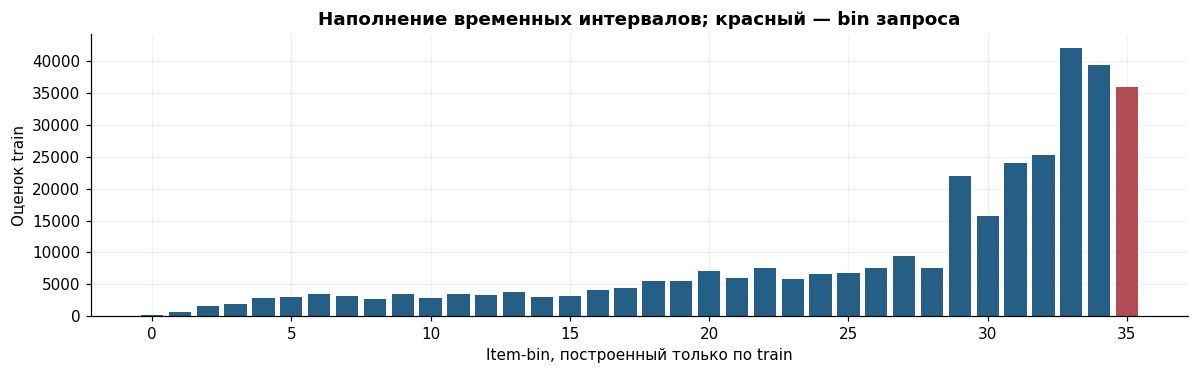

In [51]:
time_diagnostics=time_runs['summary']['best_temporal_diagnostics']
display(pd.Series(time_runs['summary']['time_statistics'],name='Fit-only время').to_frame())
display(pd.Series({k:v for k,v in time_diagnostics.items() if k!='fit_bin_counts'},name='Время запроса и параметры').to_frame())
day_stats=json.loads((ROOT/'reports/presentation_diagnostics.json').read_text())
one_rating_day_share=day_stats['fraction_user_days_with_one_rating']
display(pd.Series(day_stats,name='Разреженность дневных эффектов (train)').to_frame())
fig,ax=plt.subplots(figsize=(11,3.5))
counts=time_diagnostics['fit_bin_counts'];colors=[COLORS[0]]*len(counts);colors[time_diagnostics['query_bin']]=TIME_COLORS[-1]
ax.bar(range(len(counts)),counts,color=colors)
ax.set_xlabel('Item-bin, построенный только по train');ax.set_ylabel('Оценок train')
ax.set_title('Наполнение временных интервалов; красный — bin запроса')
show_figure('29_timesvdpp_time_bins',fig)

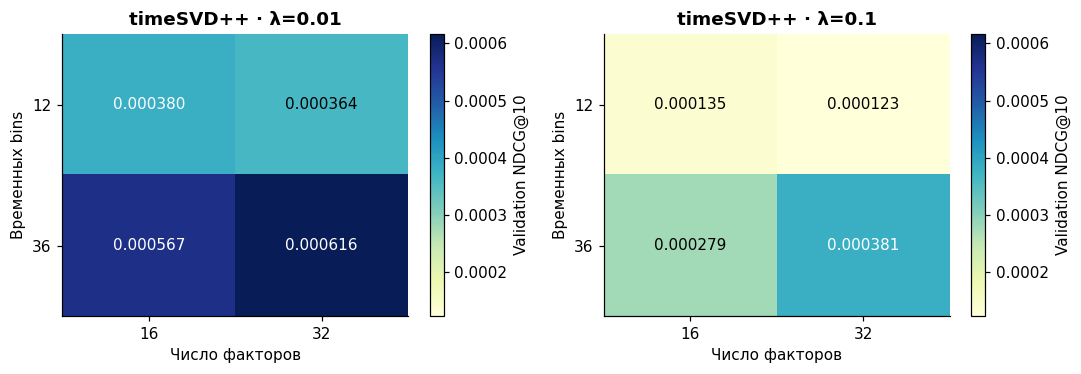

In [52]:
fig,axes=plt.subplots(1,2,figsize=(10,3.5));lo=time_search.ndcg_at_10.min();hi=time_search.ndcg_at_10.max()
for ax,reg in zip(axes,time_config['grid']['regularization']):
    table=time_search[time_search.regularization==reg].pivot(index='n_bins',columns='n_factors',values='ndcg_at_10').sort_index()
    im=ax.imshow(table.values,cmap='YlGnBu',vmin=lo,vmax=hi,aspect='auto');ax.grid(False)
    ax.set_xticks(range(len(table.columns)),table.columns);ax.set_yticks(range(len(table.index)),table.index)
    ax.set_xlabel('Число факторов');ax.set_ylabel('Временных bins');ax.set_title(f'timeSVD++ · λ={reg:g}')
    for i in range(len(table.index)):
        for j in range(len(table.columns)):
            value=table.iloc[i,j];ax.text(j,i,f'{value:.6f}',ha='center',va='center',color='white' if value>(lo+hi)/2 else 'black')
    fig.colorbar(im,ax=ax,label='Validation NDCG@10')
show_figure('30_timesvdpp_hyperparameters',fig)

### 37. Оптимизация рейтингов и ограничение интерпретации

Ниже точные train RMSE и objective, пересчитанные на **всех** train-оценках после каждого шага,
включая состояние до обучения. Монотонность AdaGrad не гарантируется.
Дневные bias/factors обладают высокой ёмкостью, особенно когда у user-day одна оценка;
эти локальные параметры недоступны для нового дня запроса.
Низкий train RMSE не подтверждает ни обобщение на будущие рейтинги, ни качество top-10.
Validation по отдельным эпохам для остановки или выбора эпохи не используется.

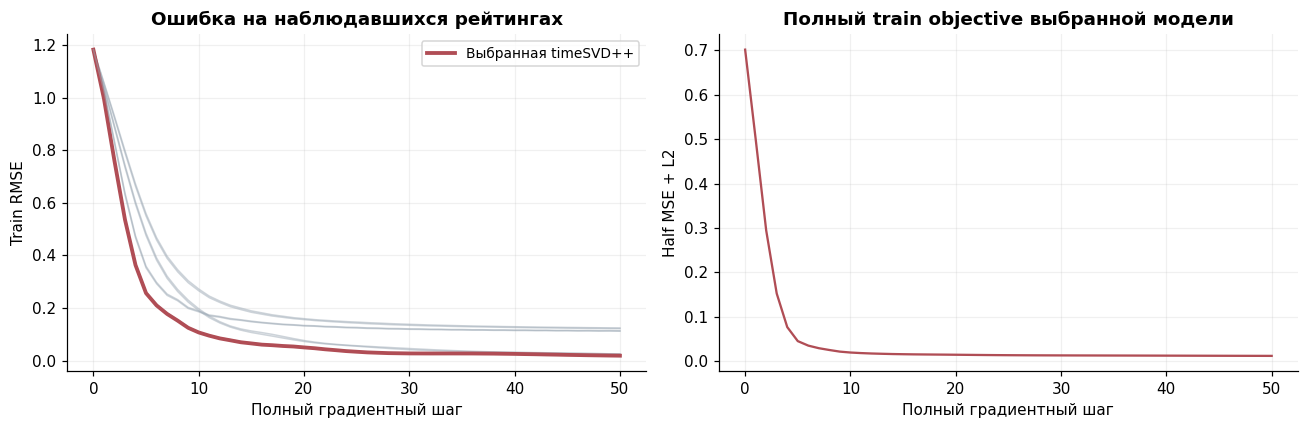

In [53]:
time_curve=time_runs['curve'];time_best_trial=int(time_search.iloc[0].trial)
assert all(len(g)==51 and g.epoch.tolist()==list(range(51)) for _,g in time_curve.groupby('trial'))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for trial,g in time_curve.groupby('trial'):
    winner=trial==time_best_trial
    axes[0].plot(g.epoch,g.training_rmse,color=TIME_COLORS[-1] if winner else '#9CA9B5',alpha=1 if winner else .5,lw=2.5 if winner else 1,label='Выбранная timeSVD++' if winner else None)
g=time_curve[time_curve.trial==time_best_trial]
axes[1].plot(g.epoch,g.training_objective,color=TIME_COLORS[-1])
axes[0].set_ylabel('Train RMSE');axes[0].set_title('Ошибка на наблюдавшихся рейтингах');axes[0].legend(fontsize=9)
axes[1].set_ylabel('Half MSE + L2');axes[1].set_title('Полный train objective выбранной модели')
for ax in axes:ax.set_xlabel('Полный градиентный шаг')
show_figure('31_timesvdpp_training',fig)

### 38. Все пять моделей на общей validation-когорте

Совпадают пользователи, релевантность rating≥4, фиксированное время запроса, полный fit-каталог,
маска всех ранее оценённых товаров, top-10 и ties. timeSVD++ возвращает конечные прогнозы и для
пользователей без положительной истории: она обучается на всех оценках; принудительный popularity fallback не добавляется.
CF/iALS/EASE/FM переиспользуют зафиксированные выдачи и настройки. Времена прежних моделей взяты из прежних запусков.

Парные bootstrap-интервалы: 2 000 перевыборок пользователей, seed 42, 95%; после HPO они описательные,
без поправки за множественные сравнения. Статический SVD++ отключает все временные параметры,
сохраняет ту же неявную историю и обучается при выбранных настройках; это диагностическая ablation,
не отдельно настроенный шестой участник основного сравнения.

,model,catalog_coverage_at_10,evaluation_seconds,fallback_rate,ndcg_at_10,recall_at_10,users,fit_seconds
0,Popularity,0.000963,1.224501,0.000000,0.005779,0.010252,10207,0.000000
1,ItemKNN,0.738798,1.277437,0.051435,0.021111,0.032179,10207,0.337878
2,iALS,0.143215,1.582736,0.050260,0.021893,0.034360,10207,44.419219
3,EASE,0.497689,1.705730,0.051435,0.023372,0.035191,10207,18.140118
4,FM,0.092952,1.492422,0.000000,0.008494,0.014402,10207,30.281805
5,timeSVD++,0.338233,1.804576,0.000000,0.000616,0.000967,10207,6.674915


,baseline,metric,estimate_for,estimate,ci_low,ci_high
0,ItemKNN,ndcg_at_10,timeSVD++,0.000616,0.000360,0.000945
1,ItemKNN,ndcg_at_10,ItemKNN,0.021111,0.019287,0.023026
2,ItemKNN,ndcg_at_10,difference,-0.020495,-0.022420,-0.018688
3,ItemKNN,recall_at_10,timeSVD++,0.000967,0.000541,0.001514
4,ItemKNN,recall_at_10,ItemKNN,0.032179,0.029379,0.035092
5,ItemKNN,recall_at_10,difference,-0.031212,-0.034128,-0.028370
6,iALS,ndcg_at_10,timeSVD++,0.000616,0.000360,0.000945
7,iALS,ndcg_at_10,iALS,0.021893,0.020066,0.023882
8,iALS,ndcg_at_10,difference,-0.021277,-0.023310,-0.019418
9,iALS,recall_at_10,timeSVD++,0.000967,0.000541,0.001514


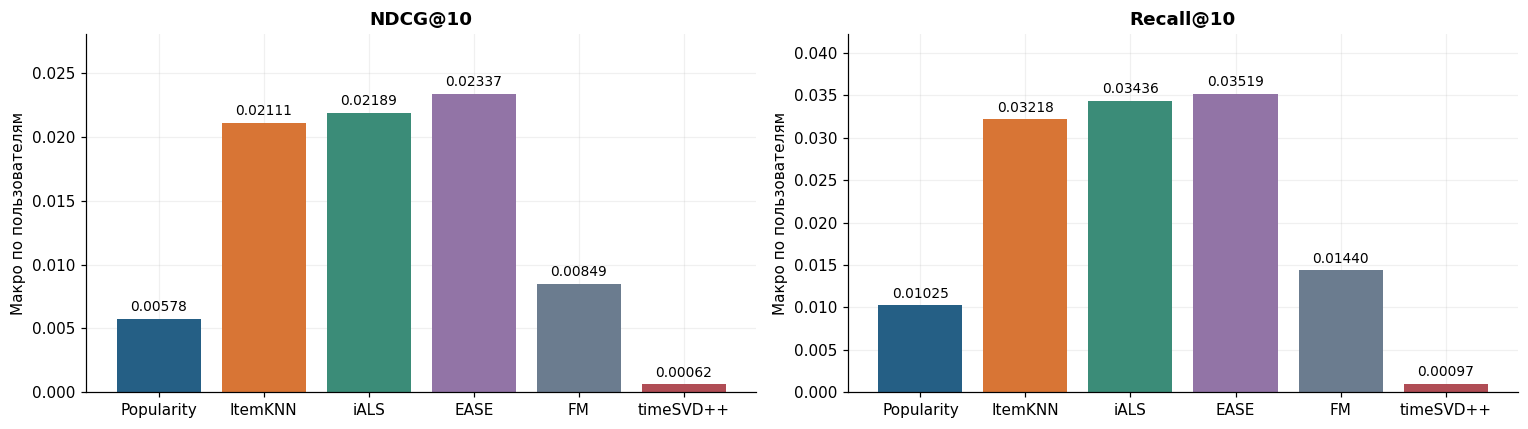

In [54]:
time_comparison=time_runs['comparison'];time_intervals=time_runs['intervals']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(time_comparison);display(time_intervals)
fig,axes=plt.subplots(1,2,figsize=(14,4))
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10'],['NDCG@10','Recall@10']):
    ax.bar(time_comparison.model,time_comparison[metric],color=TIME_COLORS)
    for i,value in enumerate(time_comparison[metric]):ax.annotate(f'{value:.5f}',(i,value),xytext=(0,5),textcoords='offset points',ha='center',fontsize=9)
    ax.set_ylim(0,time_comparison[metric].max()*1.2);ax.set_title(label);ax.set_ylabel('Макро по пользователям')
show_figure('32_timesvdpp_all_models',fig)

,model,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds
0,timeSVD++,0.000616,0.000967,0.338233,0.000000,10207,1.804576,6.674915
1,SVD++ static (diagnostic),0.001193,0.002038,0.473552,0.000000,10207,1.731394,4.755733


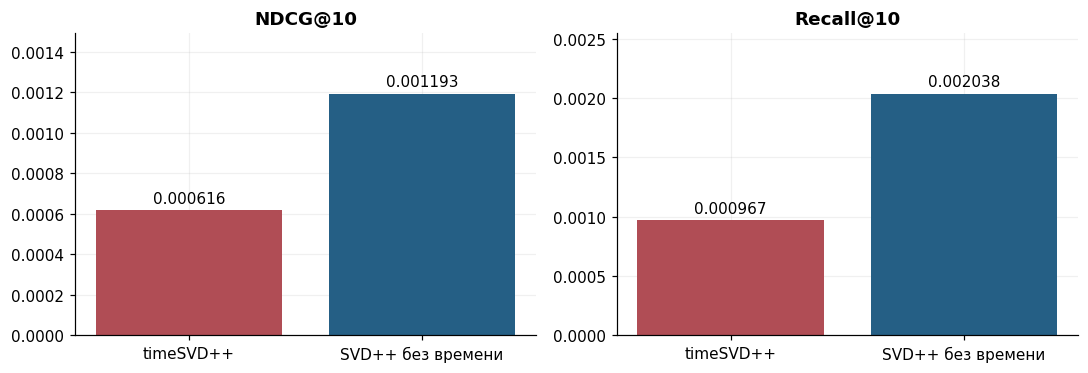

In [55]:
time_ablation=time_runs['ablation']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):display(time_ablation)
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10'],['NDCG@10','Recall@10']):
    ax.bar(['timeSVD++','SVD++ без времени'],time_ablation[metric],color=[TIME_COLORS[-1],COLORS[0]])
    for i,value in enumerate(time_ablation[metric]):ax.annotate(f'{value:.6f}',(i,value),xytext=(0,5),textcoords='offset points',ha='center')
    ax.set_ylim(0,time_ablation[metric].max()*1.25);ax.set_title(label)
show_figure('33_timesvdpp_temporal_ablation',fig)

users     ndcg   recall  fallback_rate
model      history_slice                                        
Popularity 1-4             5943 0.006765 0.011434       0.000000
           5-9             2766 0.004511 0.009421       0.000000
           10+             1498 0.004205 0.007094       0.000000
ItemKNN    1-4             5943 0.021634 0.032072       0.086152
           5-9             2766 0.019806 0.033355       0.004700
           10+             1498 0.021447 0.030435       0.000000
iALS       1-4             5943 0.022691 0.034203       0.084133
           5-9             2766 0.021001 0.037281       0.004700
           10+             1498 0.020377 0.029589       0.000000
EASE       1-4             5943 0.023352 0.034353       0.086152
           5-9             2766 0.023400 0.039595       0.004700
           10+             1498 0.023397 0.030388       0.000000
FM         1-4             5943 0.008747 0.014267       0.000000
           5-9             2766 0.008854 0.016658       0.000000
           10+             1498 0.006821 0.010773       0.000000
timeSVD++  1-4             5943 0.000488 0.000787       0.000000
           5-9             2766 0.000872 0.001265       0.000000
           10+             1498 0.000653 0.001135       0.000000

users  relevant_interactions  recall_at_10
model      item_slice                                                       
Popularity head_top_10_percent     5704                  10248      0.024125
           tail_other_90_percent   7765                  15398      0.000000
ItemKNN    head_top_10_percent     5704                  10248      0.056922
           tail_other_90_percent   7765                  15398      0.014238
iALS       head_top_10_percent     5704                  10248      0.081696
           tail_other_90_percent   7765                  15398      0.002851
EASE       head_top_10_percent     5704                  10248      0.068608
           tail_other_90_percent   7765                  15398      0.011670
FM         head_top_10_percent     5704                  10248      0.036202
           tail_other_90_percent   7765                  15398      0.000303
timeSVD++  head_top_10_percent     5704                  10248      0.001624
           tail_other_90_percent   7765                  15398      0.000558

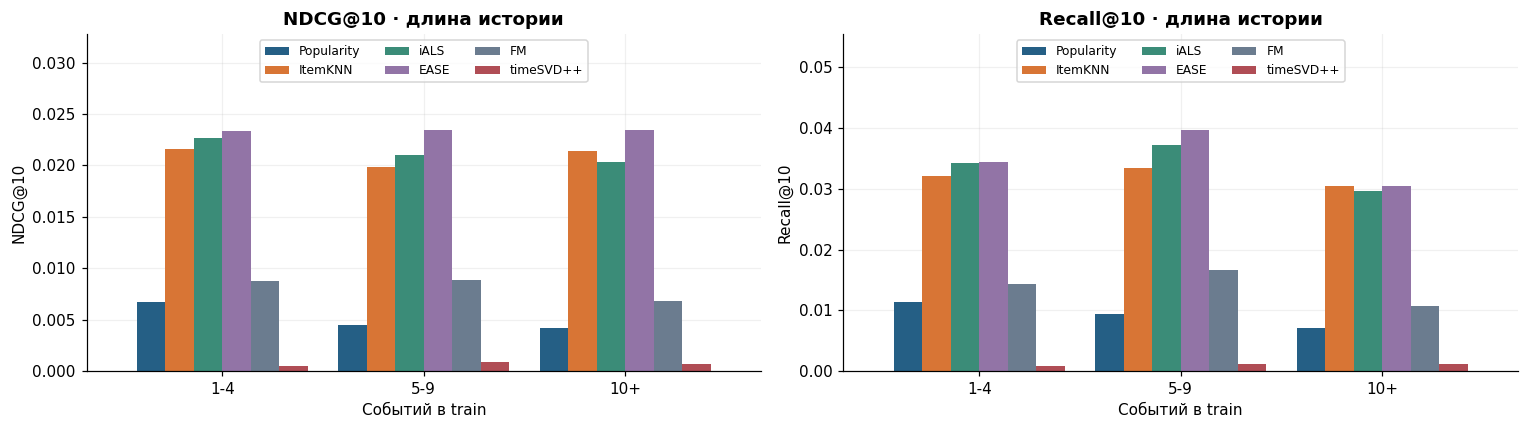

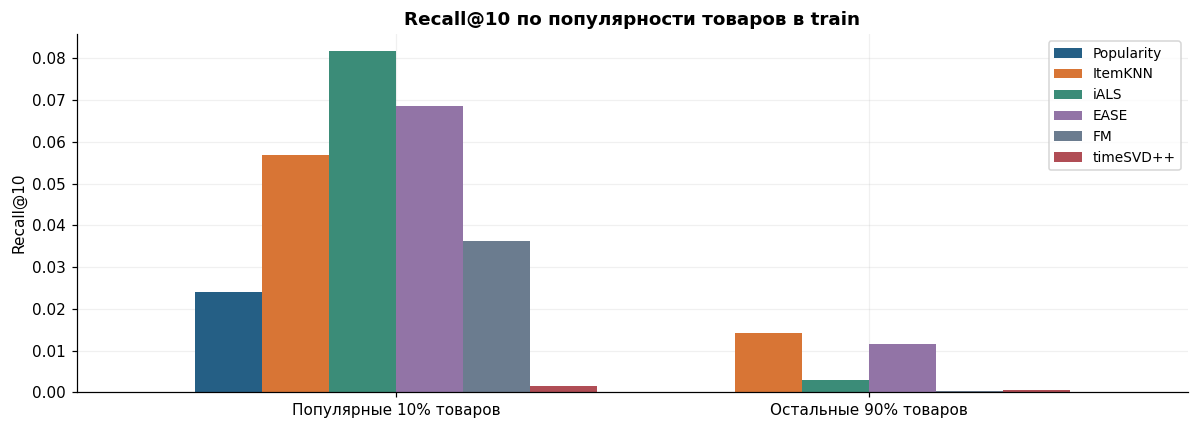

In [56]:
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(time_runs['history_slices']);display(time_runs['popularity_slices'])
fig,axes=plt.subplots(1,2,figsize=(14,4))
for ax,metric,label in zip(axes,['ndcg','recall'],['NDCG@10','Recall@10']):
    table=time_runs['history_slices'][metric].unstack('model').reindex(['1-4','5-9','10+'])[time_comparison.model]
    table.plot.bar(ax=ax,color=TIME_COLORS,rot=0,width=.85)
    ax.set_ylim(0,table.to_numpy().max()*1.4);ax.legend(fontsize=8,ncol=3,loc='upper center')
    ax.set_title(label+' · длина истории');ax.set_xlabel('Событий в train');ax.set_ylabel(label)
show_figure('34_timesvdpp_history_slices',fig)
fig,ax=plt.subplots(figsize=(11,4))
table=time_runs['popularity_slices'].recall_at_10.unstack('model').reindex(['head_top_10_percent','tail_other_90_percent'])[time_comparison.model]
table.index=['Популярные 10% товаров','Остальные 90% товаров']
table.plot.bar(ax=ax,color=TIME_COLORS,rot=0,width=.85)
ax.set_title('Recall@10 по популярности товаров в train');ax.set_xlabel('');ax.set_ylabel('Recall@10');ax.legend(fontsize=9)
show_figure('35_timesvdpp_popularity_slices',fig)

### 39. Выводы по timeSVD++ и текущему сравнению

In [57]:
time_m=time_runs['summary']['best_validation_metrics'];static_m=time_runs['summary']['static_validation_metrics']
model_order=time_comparison[time_comparison.model!='Popularity'].sort_values('ndcg_at_10',ascending=False).model.tolist()
time_place=model_order.index('timeSVD++')+1;time_lines=[]
for name in ['ItemKNN','iALS','EASE','FM','SVD++ static']:
    row=time_intervals[(time_intervals.baseline==name)&(time_intervals.metric=='ndcg_at_10')&(time_intervals.estimate_for=='difference')].iloc[0]
    zero='включает ноль' if row.ci_low<=0<=row.ci_high else 'не включает ноль'
    time_lines.append(f'- timeSVD++ − {name}, NDCG: **{row.estimate:+.6f}**, 95% интервал **[{row.ci_low:.6f}; {row.ci_high:.6f}]**, {zero}.')
rmse=float(time_search.iloc[0].final_training_rmse)
display(Markdown(f"""
Выбраны **f={time_best_params['n_factors']}, bins={time_best_params['n_bins']}, λ={time_best_params['regularization']:g}**,
50 full-gradient шагов, LR=0.05, beta=0.4, seed=42.
**Validation NDCG@10={time_m['ndcg_at_10']:.6f}, Recall@10={time_m['recall_at_10']:.6f}**.
Место среди пяти моделей — **{time_place}**. Текущий лидер validation — **{model_order[0]}**;
это не финальное test-сравнение. Проверены восемь конфигураций и один seed;
результат характеризует этот режим, а не предельные возможности timeSVD++.

"""+'\n'.join(time_lines)+f"""

Статический SVD++ при тех же настройках имеет NDCG **{static_m['ndcg_at_10']:.6f}** и Recall **{static_m['recall_at_10']:.6f}**.
Временная часть в этом эксперименте {'улучшила' if time_m['ndcg_at_10']>static_m['ndcg_at_10'] else 'не улучшила'} NDCG;
ablation отдельно не настраивалась. Улучшение от timeSVD++ в других задачах не гарантирует улучшения здесь.

Train RMSE выбранной модели — **{rmse:.6f}**, но это восстановление известных оценок, а не top-N качество.
**{one_rating_day_share:.2%}** user-day пар содержат одну оценку; дневные параметры дают высокую ёмкость на train.
У всех **{fmt(time_diagnostics['query_user_day_unseen'])}** пользователей оценки локальных дневных параметров на день запроса равны нулю.
У **{fmt(time_diagnostics['items_without_fit_observations_in_query_bin'])}** товаров нет train-событий в bin запроса.
Это ограничения данного режима прогнозирования; один эксперимент не отделяет их влияние от objective и регуляризации.

Coverage timeSVD++ — **{time_m['catalog_coverage_at_10']:.2%}**, fallback — **{time_m['fallback_rate']:.2%}**;
сохранены те же **{fmt(time_m['users'])}** пользователей. Описательные интервалы после HPO не являются независимой оценкой обобщения.

Все пять моделей реализованы. Агрегаты — `reports/timesvdpp_validation/`; параметры, временная схема и персональные выдачи
только локально в `data/validation/timesvdpp/`. **На этапе validation test не использовался.** Фиксация настроек, переобучение и завершённая оценка на test приведены в разделах 40–45.
"""))


Выбраны **f=32, bins=36, λ=0.01**,
50 full-gradient шагов, LR=0.05, beta=0.4, seed=42.
**Validation NDCG@10=0.000616, Recall@10=0.000967**.
Место среди пяти моделей — **5**. Текущий лидер validation — **EASE**;
это не финальное test-сравнение. Проверены восемь конфигураций и один seed;
результат характеризует этот режим, а не предельные возможности timeSVD++.

- timeSVD++ − ItemKNN, NDCG: **-0.020495**, 95% интервал **[-0.022420; -0.018688]**, не включает ноль.
- timeSVD++ − iALS, NDCG: **-0.021277**, 95% интервал **[-0.023310; -0.019418]**, не включает ноль.
- timeSVD++ − EASE, NDCG: **-0.022756**, 95% интервал **[-0.024749; -0.020854]**, не включает ноль.
- timeSVD++ − FM, NDCG: **-0.007878**, 95% интервал **[-0.008978; -0.006815]**, не включает ноль.
- timeSVD++ − SVD++ static, NDCG: **-0.000577**, 95% интервал **[-0.001057; -0.000109]**, не включает ноль.

Статический SVD++ при тех же настройках имеет NDCG **0.001193** и Recall **0.002038**.
Временная часть в этом эксперименте не улучшила NDCG;
ablation отдельно не настраивалась. Улучшение от timeSVD++ в других задачах не гарантирует улучшения здесь.

Train RMSE выбранной модели — **0.018470**, но это восстановление известных оценок, а не top-N качество.
**74.77%** user-day пар содержат одну оценку; дневные параметры дают высокую ёмкость на train.
У всех **10 207** пользователей оценки локальных дневных параметров на день запроса равны нулю.
У **7 044** товаров нет train-событий в bin запроса.
Это ограничения данного режима прогнозирования; один эксперимент не отделяет их влияние от objective и регуляризации.

Coverage timeSVD++ — **33.82%**, fallback — **0.00%**;
сохранены те же **10 207** пользователей. Описательные интервалы после HPO не являются независимой оценкой обобщения.

Все пять моделей реализованы. Агрегаты — `reports/timesvdpp_validation/`; параметры, временная схема и персональные выдачи
только локально в `data/validation/timesvdpp/`. **На этапе validation test не использовался.** Фиксация настроек, переобучение и завершённая оценка на test приведены в разделах 40–45.


### 40. Фиксация решений перед открытием test

`configs/final_models.json` содержит лучшие настройки всех пяти validation-поисков,
число итераций/эпох, seeds и правила FM-препроцессинга. Сводки validation и их контрольные суммы
зафиксированы вместе с параметрами. Источник выбора — macro NDCG@10 на validation с исходными ties;
число шагов не увеличивалось. **EASE заранее выбрана reference-моделью по validation.**

`reports/final_test/final_plan.json` записан до первого финального fit. Весь код моделей и оценщика
сохранён без изменений. Финальный конвейер сначала переобучает и сохраняет все пять моделей,
затем снимает блокировку чтения test. Порядок событий записан в `execution_journal.jsonl`.
После открытия test параметры, признаки, objective и протокол не менялись; ablation-модели не дообучались.

Этот раздел только загружает проверенные завершённые результаты. Он не запускает обучение или новый
поиск и не открывает исходный test-файл. Воспроизведение финального конвейера:
`python scripts/run_final_test.py`; при наличии завершённого отчёта он проверяет и переиспользует его.
Рендер только этой секции: `python scripts/execute_notebook.py --section final`.

In [58]:
final=load_final_report(ROOT)
final_summary=final['summary']
final_lock=json.loads((ROOT/'configs/final_models.json').read_text())
assert final_summary['completed_refits']==5
assert final_summary['completed_test_evaluations']==6  # 5 models and popularity control
assert final_summary['test_evaluated'] is True
assert final_summary['models']==final_lock['models']
FINAL_COLORS=COLORS+['#B04D55']

In [59]:
display(pd.DataFrame([{'model':name,**params} for name,params in final_lock['models'].items()]).set_index('model'))
refit_rows=[]
for name,info in final_summary['refit_manifest'].items():
    refit_rows.append({'model':name,'fit_seconds':info['fit_seconds'],'fit_fingerprint_matches':info['fit_fingerprint']==final_summary['fit_fingerprint']})
display(pd.DataFrame(refit_rows).set_index('model'))
display(pd.Series(final_summary['refit_manifest']['FM']['diagnostics'],name='FM: новый препроцессинг по train+validation').to_frame())
training_diagnostics=[]
for name,curve in final['training_curves'].items():
    last=curve.iloc[-1]
    training_diagnostics.append({'model':name,**{k:float(last[k]) for k in ['objective','probe_bce','training_rmse','training_objective'] if k in last}})
display(pd.DataFrame(training_diagnostics).set_index('model'))

,regularization,batch_size,learning_rate,n_epochs,n_factors,seed,...,shrinkage,alpha,n_iterations,solver_batch_size,beta,n_bins
model,,,,,,,,,,,,,
EASE,100.000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN
FM,0.001,"1,024.000",0.050,12.000,32.000,42.000,...,NaN,NaN,NaN,NaN,NaN,NaN
ItemKNN,NaN,NaN,NaN,NaN,NaN,NaN,...,10.000,NaN,NaN,NaN,NaN,NaN
iALS,0.100,NaN,NaN,NaN,64.000,42.000,...,NaN,40.000,15.000,128.000,NaN,NaN
timeSVD++,0.010,NaN,0.050,50.000,32.000,42.000,...,NaN,NaN,NaN,NaN,0.400,36.000


,fit_seconds,fit_fingerprint_matches
model,,
EASE,20.958,True
FM,36.724,True
ItemKNN,0.408,True
iALS,51.044,True
timeSVD++,8.491,True


,FM: новый препроцессинг по train+validation
feature_diagnostics,"{'brand_vocabulary': 302, 'category_l2_normali..."
feature_fingerprint,152734f987b314792036b9d995c623612c27d5f51d5ee1...
preparation_seconds,0.636
training_examples,"{'examples': 1041411, 'fingerprint': 'd7e649cb..."


,objective,probe_bce,training_rmse,training_objective
model,,,,
iALS,"6,254,222.619",NaN,NaN,NaN
FM,NaN,0.138,NaN,NaN
timeSVD++,NaN,NaN,0.019,0.012


### 41. Финальный fit и границы применимости test-метрик

Fit — объединение train и validation, без warm start. Индексы пользователей/товаров,
положительные матрицы, similarity и все веса обучены заново. Для FM заново построены словари
брендов/категорий и отрицательная выборка, исключающая все наблюдавшиеся пары объединённого fit.
Для timeSVD++ пересчитаны средние даты, user-day параметры, границы bins и вся неявная история.
Порог релевантности rating≥4, определения objective и гиперпараметры сохранены.

Рекомендации вычислены на **2017-01-01 UTC**; история train+validation заморожена на всё окно test.
Товары, оценённые в train или validation с любой оценкой, исключены из кандидатов.
Оценщик тот же: полный fit-каталог без sampling, macro NDCG@10/Recall@10, прежние ties и fallback.

Основные метрики относятся только к известным пользователям с доступной релевантностью и ≥10 кандидатами.
Cold users/items исключаются согласно протоколу, а не из-за качества конкретной модели.
Это не оценка качества на всём будущем трафике и не причинная online-метрика.
Сохраняются ограничения full-period 5-core и snapshot-метаданных Amazon.

In [60]:
final_protocol=json.loads((ROOT/'reports/evaluation_protocol.json').read_text())
final_scope=final_protocol['evaluation_diagnostics']['test']
display(pd.Series(final_summary['fit'],name='Финальное обучение').to_frame())
display(pd.Series(final_summary['cohort'],name='Общая test-когорта').to_frame())
display(pd.Series({
    'test_events':final_summary['test_rows'],
    'all_positive_test_events':final_scope['all_positive_interactions'],
    'available_relevant_test_events':final_summary['cohort']['relevant_interactions'],
    'positive_event_coverage':final_scope['positive_interaction_coverage'],
    'query_utc':str(pd.Timestamp(final_summary['query_timestamp'],unit='s',tz='UTC')),
    'validation_reference':final_summary['validation_reference']},name='Область оценки').to_frame())
assert final_summary['cohort']['evaluation_users']==9521
assert final_summary['cohort']['catalog_items']==16721
assert final_summary['cohort']['relevant_interactions']==23454

,Финальное обучение
interactions,403681
items,16721
max_timestamp,1483142400
users,48349


,Общая test-когорта
catalog_items,16721
evaluation_users,9521
new_item_interactions,4423
new_user_interactions,16023
relevant_interactions,23454
seen_relevant_items_removed,0
users_excluded_for_fewer_than_k_candidates,0


,Область оценки
test_events,49308
all_positive_test_events,40470
available_relevant_test_events,23454
positive_event_coverage,0.580
query_utc,2017-01-01 00:00:00+00:00
validation_reference,EASE


### 42. Итоговое сравнение на test

Интервалы — парный bootstrap по тем же пользователям (2 000 перевыборок, seed 42, 95%).
Reference EASE выбрана **до test**, а не по максимальной test-метрике.
Интервалы условны на фиксированных обученных моделях; они не учитывают вариацию обучения между seeds.
Поправка за пять сравнений с reference не применяется: ненулевой интервал сам по себе не означает
одновременного статистического превосходства над всеми моделями.
Времена обучения измерены в этом финальном запуске; построение индексов и специальный препроцессинг
FM/timeSVD++ исключены из `fit_seconds`, это не универсальный benchmark скорости.

,model,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds,selected_parameters
0,Popularity,0.009712,0.012274,0.001076,0.000000,9521,1.481654,0.000000,{}
1,ItemKNN,0.021241,0.032328,0.674242,0.034030,9521,1.255915,0.407540,"{""n_neighbors"": 100, ""shrinkage"": 10.0}"
2,iALS,0.022217,0.034842,0.135040,0.033295,9521,1.714993,51.044373,"{""alpha"": 40.0, ""n_factors"": 64, ""n_iterations..."
3,EASE,0.022048,0.033390,0.442378,0.034030,9521,5.245361,20.957787,"{""regularization"": 100.0}"
4,FM,0.009612,0.016354,0.082352,0.000000,9521,1.702478,36.723912,"{""batch_size"": 1024, ""learning_rate"": 0.05, ""n..."
5,timeSVD++,0.000579,0.001113,0.348185,0.000000,9521,1.695619,8.490954,"{""beta"": 0.4, ""learning_rate"": 0.05, ""n_bins"":..."


,comparison,metric,estimate_for,estimate,ci_low,ci_high
2,Popularity - EASE,ndcg_at_10,difference,-0.012336,-0.014643,-0.009981
5,Popularity - EASE,recall_at_10,difference,-0.021116,-0.024299,-0.017868
8,ItemKNN - EASE,ndcg_at_10,difference,-0.000807,-0.001768,0.000217
11,ItemKNN - EASE,recall_at_10,difference,-0.001062,-0.002773,0.000774
14,iALS - EASE,ndcg_at_10,difference,0.000169,-0.001465,0.001961
17,iALS - EASE,recall_at_10,difference,0.001452,-0.001359,0.004324
20,FM - EASE,ndcg_at_10,difference,-0.012436,-0.014451,-0.010465
23,FM - EASE,recall_at_10,difference,-0.017036,-0.019996,-0.013965
26,timeSVD++ - EASE,ndcg_at_10,difference,-0.021469,-0.023387,-0.019520
29,timeSVD++ - EASE,recall_at_10,difference,-0.032277,-0.035190,-0.029425


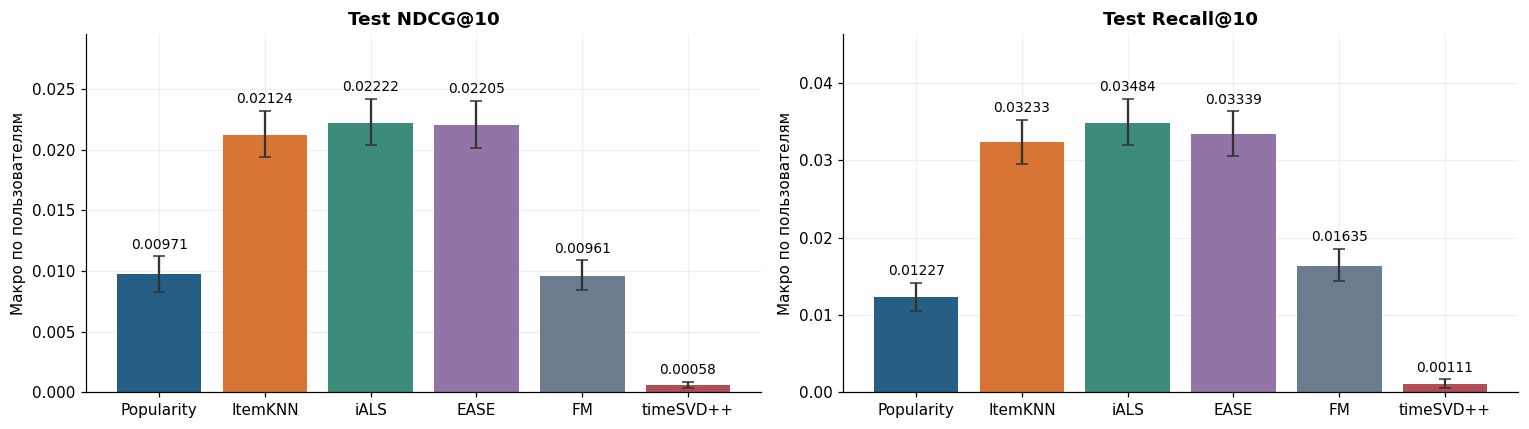

In [61]:
final_comparison=final['comparison'];final_intervals=final['intervals']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}','display.max_columns',None):
    display(final_comparison.assign(selected_parameters=final_comparison.model.map(lambda name: json.dumps(final_lock['models'].get(name,{}),ensure_ascii=False,sort_keys=True))))
    display(final_intervals[final_intervals.estimate_for=='difference'])
fig,axes=plt.subplots(1,2,figsize=(14,4))
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10'],['Test NDCG@10','Test Recall@10']):
    ax.bar(final_comparison.model,final_comparison[metric],color=FINAL_COLORS)
    tops=[]
    for i,row in final_comparison.iterrows():
        ci=final_intervals[(final_intervals.metric==metric)&(final_intervals.estimate_for==row.model)].iloc[0]
        ax.errorbar(i,row[metric],yerr=[[max(0,row[metric]-ci.ci_low)],[max(0,ci.ci_high-row[metric])]],fmt='none',ecolor='#333333',capsize=4)
        tops.append(ci.ci_high)
        ax.annotate(f'{row[metric]:.5f}',(i,ci.ci_high),xytext=(0,5),textcoords='offset points',ha='center',fontsize=9)
    ax.set_ylim(0,max(tops)*1.22);ax.set_title(label);ax.set_ylabel('Макро по пользователям')
show_figure('36_final_test_metrics',fig)

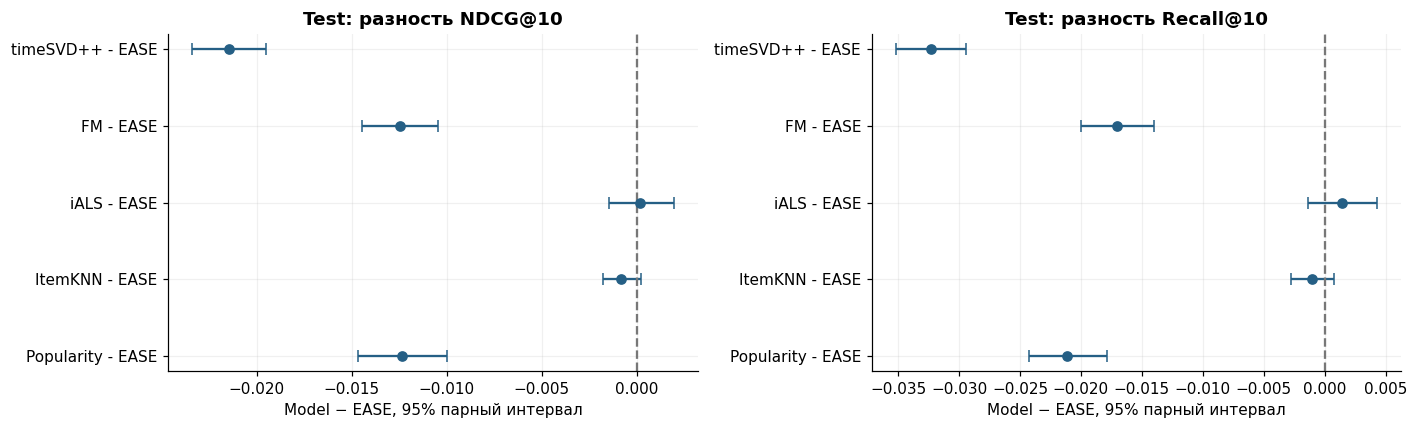

In [62]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10'],['NDCG@10','Recall@10']):
    table=final_intervals[(final_intervals.metric==metric)&(final_intervals.estimate_for=='difference')].reset_index(drop=True)
    ax.errorbar(table.estimate,range(len(table)),xerr=[table.estimate-table.ci_low,table.ci_high-table.estimate],fmt='o',capsize=4,color='#255F85')
    ax.axvline(0,color='#777777',ls='--');ax.set_yticks(range(len(table)),table.comparison)
    ax.set_title('Test: разность '+label);ax.set_xlabel('Model − EASE, 95% парный интервал')
show_figure('37_final_paired_differences',fig)

### 43. Validation и test: описательное сопоставление

Здесь различаются и обученные веса, и состав когорты, и доступный каталог, и горизонт будущего окна.
Validation охватывает 2016 год, test — период с 2017 до октября 2018 года. Поэтому разность метрик
между колонками не является эффектом дополнительного обучения или статистически парным сравнением.
Test не использован для изменения модели, даже если порядок моделей отличается от validation.

,model,metric,validation,test
0,ItemKNN,ndcg_at_10,0.021,0.021
1,ItemKNN,recall_at_10,0.032,0.032
2,ItemKNN,catalog_coverage_at_10,0.739,0.674
3,iALS,ndcg_at_10,0.022,0.022
4,iALS,recall_at_10,0.034,0.035
5,iALS,catalog_coverage_at_10,0.143,0.135
6,EASE,ndcg_at_10,0.023,0.022
7,EASE,recall_at_10,0.035,0.033
8,EASE,catalog_coverage_at_10,0.498,0.442
9,FM,ndcg_at_10,0.008,0.010


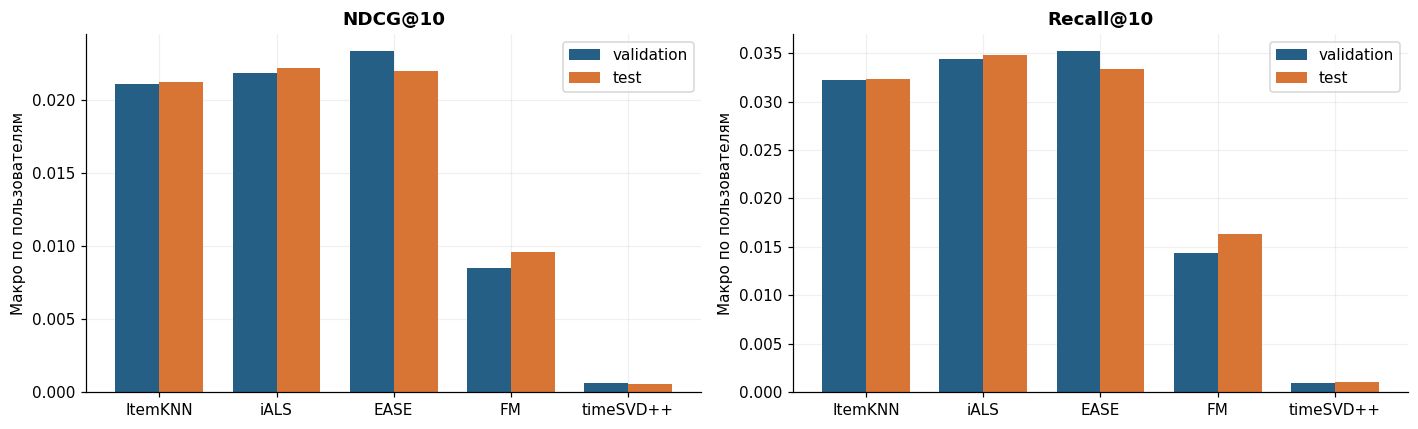

In [63]:
display(final['validation_vs_test'])
fig,axes=plt.subplots(1,2,figsize=(13,4))
order=final_comparison.loc[final_comparison.model!='Popularity','model'].tolist()
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10'],['NDCG@10','Recall@10']):
    table=final['validation_vs_test'][final['validation_vs_test'].metric==metric].set_index('model').reindex(order)[['validation','test']]
    table.plot.bar(ax=ax,rot=0,color=[COLORS[0],COLORS[1]],width=.75)
    ax.set_title(label);ax.set_xlabel('');ax.set_ylabel('Макро по пользователям')
show_figure('38_final_validation_vs_test',fig)

### 44. Срезы и компромиссы качества

Группы длины истории и head/tail товаров определены только по train+validation.
Recall head/tail усреднён по пользователям с релевантными товарами данного среза;
пользователь может присутствовать в обоих. Эти срезы диагностические, не новые критерии выбора.
Покрытие каталога и fallback дополняют точность попаданий и не подменяют её.

users     ndcg   recall  fallback_rate
model      history_slice                                        
Popularity 1-4             4561 0.009973 0.012498       0.000000
           5-9             3149 0.008969 0.011169       0.000000
           10+             1811 0.010345 0.013631       0.000000
ItemKNN    1-4             4561 0.023038 0.033194       0.067310
           5-9             3149 0.019291 0.031996       0.005399
           10+             1811 0.020105 0.030724       0.000000
iALS       1-4             4561 0.025259 0.037720       0.065775
           5-9             3149 0.020026 0.033892       0.005399
           10+             1811 0.018363 0.029246       0.000000
EASE       1-4             4561 0.024040 0.033743       0.067310
           5-9             3149 0.020436 0.033490       0.005399
           10+             1811 0.019831 0.032327       0.000000
FM         1-4             4561 0.011069 0.017962       0.000000
           5-9             3149 0.009205 0.016900       0.000000
           10+             1811 0.006652 0.011352       0.000000
timeSVD++  1-4             4561 0.000307 0.000488       0.000000
           5-9             3149 0.000390 0.000926       0.000000
           10+             1811 0.001592 0.003013       0.000000

users  relevant_interactions  recall_at_10
model      item_slice                                                       
Popularity head_top_10_percent     5572                  10028      0.027900
           tail_other_90_percent   7063                  13426      0.000000
ItemKNN    head_top_10_percent     5572                  10028      0.056127
           tail_other_90_percent   7063                  13426      0.013090
iALS       head_top_10_percent     5572                  10028      0.077209
           tail_other_90_percent   7063                  13426      0.002494
EASE       head_top_10_percent     5572                  10028      0.064549
           tail_other_90_percent   7063                  13426      0.009704
FM         head_top_10_percent     5572                  10028      0.037563
           tail_other_90_percent   7063                  13426      0.000413
timeSVD++  head_top_10_percent     5572                  10028      0.001546
           tail_other_90_percent   7063                  13426      0.000549

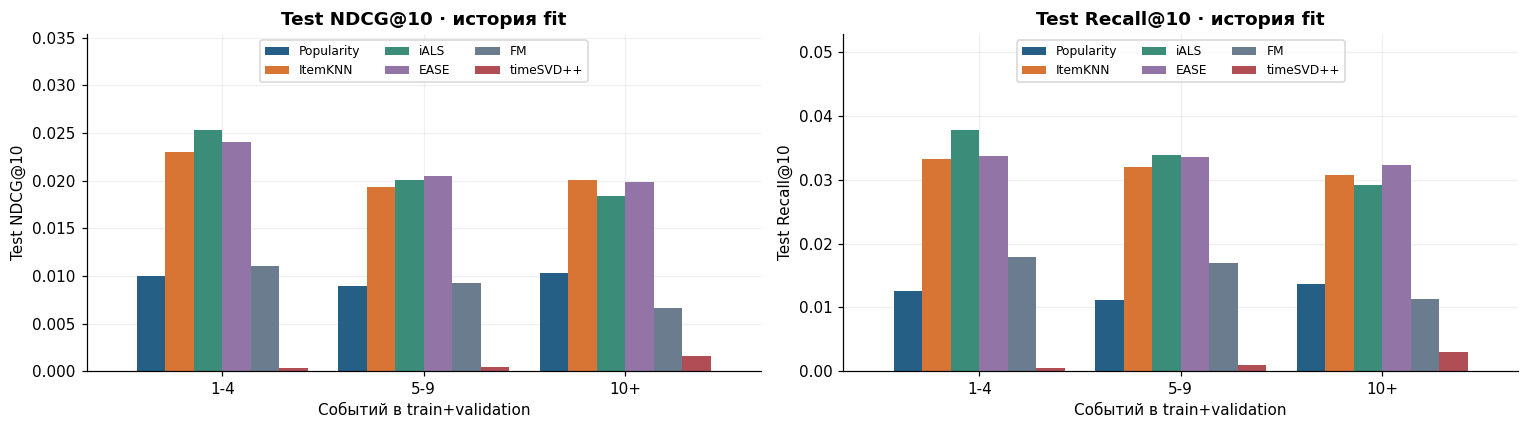

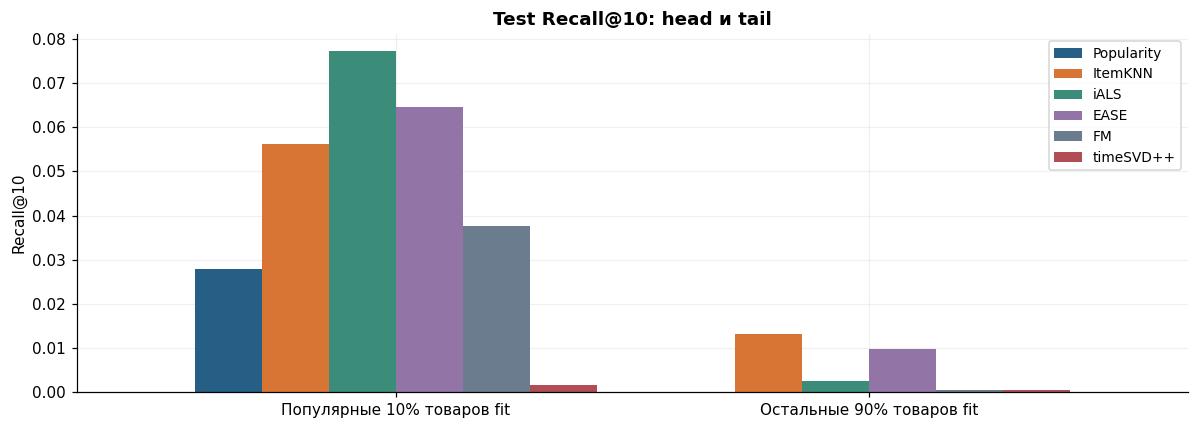

In [64]:
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(final['history_slices']);display(final['popularity_slices'])
fig,axes=plt.subplots(1,2,figsize=(14,4))
for ax,metric,label in zip(axes,['ndcg','recall'],['Test NDCG@10','Test Recall@10']):
    table=final['history_slices'][metric].unstack('model').reindex(['1-4','5-9','10+'])[final_comparison.model]
    table.plot.bar(ax=ax,color=FINAL_COLORS,rot=0,width=.85)
    ax.set_ylim(0,table.to_numpy().max()*1.4);ax.legend(fontsize=8,ncol=3,loc='upper center')
    ax.set_title(label+' · история fit');ax.set_xlabel('Событий в train+validation');ax.set_ylabel(label)
show_figure('39_final_history_slices',fig)
fig,ax=plt.subplots(figsize=(11,4))
table=final['popularity_slices'].recall_at_10.unstack('model').reindex(['head_top_10_percent','tail_other_90_percent'])[final_comparison.model]
table.index=['Популярные 10% товаров fit','Остальные 90% товаров fit']
table.plot.bar(ax=ax,color=FINAL_COLORS,rot=0,width=.85)
ax.set_title('Test Recall@10: head и tail');ax.set_xlabel('');ax.set_ylabel('Recall@10');ax.legend(fontsize=9)
show_figure('40_final_popularity_slices',fig)

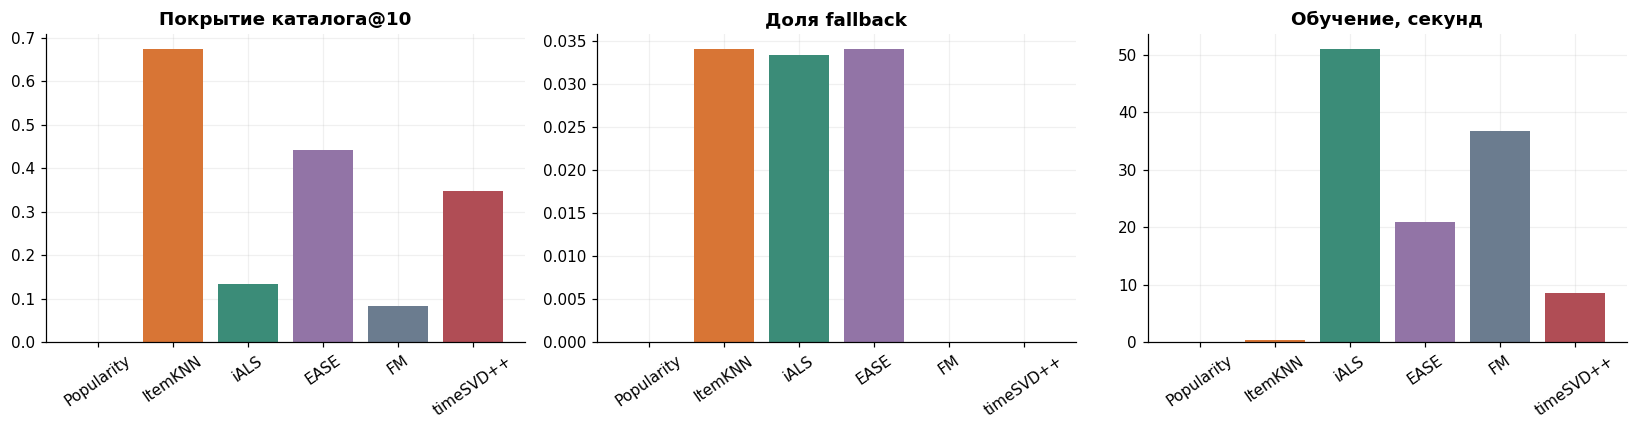

In [65]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,metric,label in zip(axes,['catalog_coverage_at_10','fallback_rate','fit_seconds'],['Покрытие каталога@10','Доля fallback','Обучение, секунд']):
    ax.bar(final_comparison.model,final_comparison[metric],color=FINAL_COLORS)
    ax.set_title(label);ax.tick_params(axis='x',labelrotation=35)
show_figure('41_final_coverage_fallback_cost',fig)

### 45. Итоговые выводы

In [66]:
final_models=final_comparison[final_comparison.model!='Popularity'].sort_values('ndcg_at_10',ascending=False)
observed_test_leader=final_models.iloc[0]
reference=final_summary['validation_reference']
ref=final_comparison.set_index('model').loc[reference]
final_lines=[]
for _,row in final_intervals[(final_intervals.metric=='ndcg_at_10')&(final_intervals.estimate_for=='difference')].iterrows():
    zero='включает ноль' if row.ci_low<=0<=row.ci_high else 'не включает ноль'
    final_lines.append(f'- {row.comparison}: **{row.estimate:+.6f}**, 95% интервал **[{row.ci_low:.6f}; {row.ci_high:.6f}]**, {zero}.')
tail_table=final['popularity_slices'].recall_at_10.unstack('model')
tail_best=tail_table.loc['tail_other_90_percent'].idxmax()
display(Markdown(f"""
Все пять моделей заново обучены на **train+validation: {fmt(final_summary['fit']['interactions'])} взаимодействий**.
Test: **{fmt(final_summary['test_rows'])} событий**; основная оценка — когорта из **{fmt(final_summary['cohort']['evaluation_users'])} пользователей**,
каталог из **{fmt(final_summary['cohort']['catalog_items'])} товаров** и **{fmt(final_summary['cohort']['relevant_interactions'])} релевантных событий**.
Положительная test-релевантность покрыта на **{final_scope['positive_interaction_coverage']:.2%}**;
выводы ограничены зафиксированным warm-start протоколом.

Выбранная по validation reference-модель — **{reference}**: test NDCG@10 **{ref.ndcg_at_10:.6f}**,
Recall@10 **{ref.recall_at_10:.6f}**. Самая высокая точечная test NDCG среди пяти моделей — у
**{observed_test_leader.model} ({observed_test_leader.ndcg_at_10:.6f})**. Это описательный итог test,
а не основание для нового подбора, изменения параметров или повторного обучения.

Разности test NDCG относительно заранее выбранной EASE:

"""+'\n'.join(final_lines)+f"""

Интервалы не скорректированы за множественные сравнения и не учитывают seed-вариацию обучения.
Максимальный Recall хвоста в этом test-срезе — у **{tail_best}**; общая точность и охват товаров
могут задавать разные компромиссы. Rating-based timeSVD++ и pointwise FM имеют иные objective,
поэтому их train loss напрямую не сравнивается с ranking-качеством других моделей.

Финальные настройки сохранены в `configs/final_models.json`, план и сводки — в `reports/final_test/`.
Веса, словари, временные схемы и персональные выдачи находятся только в локальной `data/final_test/`, исключённой из Git.
После открытия test **не менялись гиперпараметры, число шагов, признаки, targets или протокол**.
Исторические validation-секции сохранены как этап выбора; их пометки о закрытом test относятся к тому этапу.
Численный эксперимент завершён, но строгое соответствие требованию исторической доступности
метапризнаков FM требует согласования или корректирующего эксперимента (см. README). Ограничения: наблюдаемые отзывы вместо логов показов/покупок, full-period 5-core,
snapshot-метаданные, cold-start исключения и разные временные горизонты; результаты не являются online A/B-эффектом.
"""))


Все пять моделей заново обучены на **train+validation: 403 681 взаимодействий**.
Test: **49 308 событий**; основная оценка — когорта из **9 521 пользователей**,
каталог из **16 721 товаров** и **23 454 релевантных событий**.
Положительная test-релевантность покрыта на **57.95%**;
выводы ограничены зафиксированным warm-start протоколом.

Выбранная по validation reference-модель — **EASE**: test NDCG@10 **0.022048**,
Recall@10 **0.033390**. Самая высокая точечная test NDCG среди пяти моделей — у
**iALS (0.022217)**. Это описательный итог test,
а не основание для нового подбора, изменения параметров или повторного обучения.

Разности test NDCG относительно заранее выбранной EASE:

- Popularity - EASE: **-0.012336**, 95% интервал **[-0.014643; -0.009981]**, не включает ноль.
- ItemKNN - EASE: **-0.000807**, 95% интервал **[-0.001768; 0.000217]**, включает ноль.
- iALS - EASE: **+0.000169**, 95% интервал **[-0.001465; 0.001961]**, включает ноль.
- FM - EASE: **-0.012436**, 95% интервал **[-0.014451; -0.010465]**, не включает ноль.
- timeSVD++ - EASE: **-0.021469**, 95% интервал **[-0.023387; -0.019520]**, не включает ноль.

Интервалы не скорректированы за множественные сравнения и не учитывают seed-вариацию обучения.
Максимальный Recall хвоста в этом test-срезе — у **ItemKNN**; общая точность и охват товаров
могут задавать разные компромиссы. Rating-based timeSVD++ и pointwise FM имеют иные objective,
поэтому их train loss напрямую не сравнивается с ranking-качеством других моделей.

Финальные настройки сохранены в `configs/final_models.json`, план и сводки — в `reports/final_test/`.
Веса, словари, временные схемы и персональные выдачи находятся только в локальной `data/final_test/`, исключённой из Git.
После открытия test **не менялись гиперпараметры, число шагов, признаки, targets или протокол**.
Исторические validation-секции сохранены как этап выбора; их пометки о закрытом test относятся к тому этапу.
Численный эксперимент завершён, но строгое соответствие требованию исторической доступности
метапризнаков FM требует согласования или корректирующего эксперимента (см. README). Ограничения: наблюдаемые отзывы вместо логов показов/покупок, full-period 5-core,
snapshot-метаданные, cold-start исключения и разные временные горизонты; результаты не являются online A/B-эффектом.
